# ECOv003 JET Accuracy Analysis with ECOv002 Cal-Val

This notebook performs a sensitivity analysis of the JET ensemble using ECOSTRESS Collection 2 Cal-Val data. 

## Import Required Libraries and Functions

This cell imports all necessary libraries and functions for data processing, model execution, statistical analysis, and plotting. It includes custom modules for the JET ensemble, sensitivity analysis, and net radiation calculations, as well as standard scientific Python libraries.

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname("__file__"), '..')))
from typing import Callable
from os import makedirs
from os.path import join
import numpy as np
import pandas as pd
from verma_net_radiation import verma_net_radiation_table
from JET3 import process_JET_table, load_ECOv002_calval_JET_inputs
import matplotlib.pyplot as plt
from scipy.stats import mstats
import seaborn as sns
from matplotlib.ticker import FuncFormatter

## Configuration Options

Set configuration options for the notebook, including whether to save plots to files.

In [2]:
# Configuration: Set to True to save plots to files, False to only display them
SAVE_PLOTS = False

In [3]:
use_input_filters = True
use_dropna = False

input_variables = [
    "ST_C",
    "NDVI",
    "albedo",
    "Ta_C",
    "RH",
    "AOT",
    "COT",
    "vapor_gccm",
    "ozone_cm",
    "elevation_m",
    "canopy_height_meters"
]

output_variables = [
    "Rn_Wm2",
    "ET_daylight_kg",
    "GPP_inst_g_m2_s"
]

# Per-variable physical bounds to keep perturbations realistic
input_min = {
    # "ST_C": 0.0,
    "NDVI": 0.05,
    # "albedo": 0.0,
    # "Ta_C": 0.0,
    # "RH": 0.0,
    # "AOT": 0.0,
    # "COT": 0.0,
    # "vapor_gccm": 0.0,
    # "ozone_cm": 0.0,
    # "elevation_m": 0.0,
    # "canopy_height_meters": 0.0,
}

input_max = {
    # "ST_C": 50.0,
    # "NDVI": 1,
    # "albedo": 1,
}

## Define Processing Function for Model Table

This cell defines the forward process for analysis as the BESS-JPL model.

In [4]:
forward_process = process_JET_table
model_name = "JET"

## Load and Filter Input Data

This cell loads the ECOSTRESS Cal-Val input data using a custom loader function and filters out surface temperatures greater than 50 Celsius and NDVI values less than 0.05. The resulting DataFrame is displayed for inspection.

In [5]:
input_df = load_ECOv002_calval_JET_inputs()

print(len(input_df))

if use_input_filters:
    # Apply lower and upper bounds from configuration dictionaries
    mask = pd.Series(True, index=input_df.index)
    for var, min_val in input_min.items():
        if var in input_df.columns:
            mask &= input_df[var] >= min_val
    for var, max_val in input_max.items():
        if var in input_df.columns:
            mask &= input_df[var] <= max_val

    input_df = input_df[mask]

if use_dropna:
    input_df = input_df.dropna()

print(len(input_df))
    
input_df

1065
1063


,Unnamed: 0,ID,vegetation,climate,STICinst,BESSinst,MOD16inst,PTJPLSMinst,ETinst,ETinstUncertainty,...,CL,Tmin_open,Tmin_closed,VPD_open,VPD_closed,Tmin_C,Topt_C,fAPARmax,field_capacity,wilting_point
0,0,US-NC3,ENF,Cfa,270.345200,78.53355,392.851840,307.021970,487.383423,118.916280,...,0.0070,12.02,-8.0,650.0,4500.0,32.65892,10.09,0.4659,0.24,0.11
1,1,US-Mi3,CVM,Dfb,232.141600,229.20093,640.118470,375.089300,106.825577,167.919460,...,0.0065,11.39,-8.0,650.0,3500.0,20.56636,1.39,0.4865,0.31,0.14
2,2,US-Mi3,CVM,Dfb,356.355740,335.23154,625.661700,284.686250,NaN,132.936340,...,0.0065,11.39,-8.0,650.0,3500.0,20.56636,1.39,0.4865,0.31,0.14
3,3,US-Mi3,CVM,Dfb,332.938400,326.68680,624.254330,251.414490,178.827545,141.132420,...,0.0065,11.39,-8.0,650.0,3500.0,20.56636,1.39,0.4865,0.31,0.14
4,4,US-Mi3,CVM,Dfb,286.854030,237.21654,511.082180,228.520170,154.791626,114.809410,...,0.0065,11.39,-8.0,650.0,3500.0,20.56636,1.39,0.4865,0.31,0.14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1060,1060,US-xAE,GRA,Cfa,70.923310,172.37459,81.645230,15.282976,NaN,56.385185,...,NaN,NaN,NaN,NaN,NaN,NaN,7.99,0.3387,0.28,0.13
1061,1061,US-xAE,GRA,Cfa,116.543190,121.81641,65.469320,22.186659,NaN,40.509410,...,NaN,NaN,NaN,NaN,NaN,NaN,7.99,0.3387,0.28,0.13
1062,1062,US-xAE,GRA,Cfa,129.880100,0.00000,118.777240,55.343586,NaN,52.403820,...,NaN,NaN,NaN,NaN,NaN,NaN,7.99,0.3387,0.28,0.13
1063,1063,US-xAE,GRA,Cfa,2.707851,140.38632,126.490524,40.434025,NaN,57.769722,...,NaN,NaN,NaN,NaN,NaN,NaN,7.99,0.3387,0.28,0.13


## Process Input Data Through Model

This cell applies the processing function to the filtered input data, running it through the model, and displays the resulting DataFrame.

In [6]:
processed = forward_process(input_df)
processed

[2026-08-27 10:36:54 INFO] starting JET table processing
[2026-08-27 10:36:54 INFO] started extracting geometry from JET input table
[2026-08-27 10:36:54 INFO] completed extracting geometry from JET input table (0.009 seconds)
[2026-08-27 10:36:54 INFO] started extracting time from JET input table
[2026-08-27 10:36:54 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:36:54 INFO] running Forest Light Environmental Simulator
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
[2026-08-27 10:36:55 INFO] completed processing FLiES-ANN in 0.24 seconds
[2026-08-27 10:36:55 INFO] variable PAR_albedo min: 0.003 mean: 0.051 max: 0.295 nan: 0.00% (nan)
[2026-08-27 10:36:55 INFO] variable NIR_albedo min: 0.028 mean: 0.163 max: 0.582 nan: 0.00% (nan)
[2026-08-27 10:36:55 INFO] variable PAR_direct_Wm2 min: 4.617 mean: 266.384 max: 473.257 nan: 0.38% (nan)
[2026-08-27 10:36:55 INFO] variable SWin_FLiES_ANN min: 104.662 mean: 715.760 max: 1153.185 nan: 0.38% (nan)
[2026-08-27 10:

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Use

,Unnamed: 0,ID,vegetation,climate,STICinst,BESSinst,MOD16inst,PTJPLSMinst,ETinst,ETinstUncertainty,...,G_PMJPL_Wm2,G_Wm2,LE_instantaneous_Wm2,LE_Wm2,H_Wm2,ET_daylight_kg,ET_uncertainty,GPP_inst_g_m2_s,ET_canopy_inst_kg_m2_s,WUE
0,0,US-NC3,ENF,Cfa,270.345200,78.53355,392.851840,307.021970,487.383423,118.916280,...,60.425858,60.425858,351.448461,351.448461,54.761772,4.144935,0.773774,0.000212,0.000109,1.943556
1,1,US-Mi3,CVM,Dfb,232.141600,229.20093,640.118470,375.089300,106.825577,167.919460,...,99.328964,99.328964,326.039533,326.039533,360.706912,4.279363,1.239315,0.000269,0.000111,2.421845
2,2,US-Mi3,CVM,Dfb,356.355740,335.23154,625.661700,284.686250,NaN,132.936340,...,94.519459,94.519459,335.227018,335.227018,306.110166,4.353823,0.920482,0.000251,0.000044,5.670131
3,3,US-Mi3,CVM,Dfb,332.938400,326.68680,624.254330,251.414490,178.827545,141.132420,...,78.277108,78.277108,332.815927,332.815927,345.610073,4.433066,0.372526,0.000303,0.000049,6.158837
4,4,US-Mi3,CVM,Dfb,286.854030,237.21654,511.082180,228.520170,154.791626,114.809410,...,70.628272,70.628272,290.934683,290.934683,260.113128,4.244395,0.368856,0.000283,0.000058,4.846558
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1060,1060,US-xAE,GRA,Cfa,70.923310,172.37459,81.645230,15.282976,NaN,56.385185,...,5.985290,5.985290,35.172963,35.172963,196.977862,0.423263,0.427738,0.000006,0.000008,0.723558
1061,1061,US-xAE,GRA,Cfa,116.543190,121.81641,65.469320,22.186659,NaN,40.509410,...,23.006292,23.006292,37.569782,37.569782,187.016966,0.815033,1.326901,0.000015,0.000012,1.260016
1062,1062,US-xAE,GRA,Cfa,129.880100,0.00000,118.777240,55.343586,NaN,52.403820,...,43.185134,43.185134,27.267394,27.267394,258.399557,0.585193,0.710205,0.000041,0.000031,1.332510
1063,1063,US-xAE,GRA,Cfa,2.707851,140.38632,126.490524,40.434025,NaN,57.769722,...,28.164664,28.164664,58.151032,58.151032,265.153028,1.076440,0.606770,0.000024,0.000023,1.048858


## Accuracy Comparison of In-Situ Observations to Model Estimates

Examining the accuracy of model estimates compared to ground data.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

def generate_accuracy_plot(df, x_variable, y_variable, output_variable, model_name, color_col='ST_C', cbar_label="ECOSTRESS Surface Temperature (°C)", save_plots=False):
    """
    Generates and optionally saves a scatter plot comparing in-situ data to model output,
    including a 1:1 line, OLS regression fit, R-squared, and RMSE annotations.
    """
    # FIX 3: Replaced hardcoded 'ST_C' with color_col parameter
    valid_data = df[[x_variable, y_variable, color_col]].dropna()
    
    # Calculate the 2nd and 98th percentiles for the color dimension
    vmin = np.percentile(valid_data[color_col], 2)
    vmax = np.percentile(valid_data[color_col], 98)
    
    # Create the scatter plot
    # FIX: Removed `color=None` to prevent conflicts with `c` in newer matplotlib versions
    sc = plt.scatter(
        x=valid_data[x_variable],
        y=valid_data[y_variable],
        c=valid_data[color_col],
        cmap="jet",
        s=5,
        vmin=vmin,    # Apply 2nd percentile minimum
        vmax=vmax     # Apply 98th percentile maximum
    )

    # Get the actual data bounds to ensure lines span the whole plot
    x_min, x_max = valid_data[x_variable].min(), valid_data[x_variable].max()
    y_min, y_max = valid_data[y_variable].min(), valid_data[y_variable].max()
    
    # Calculate a square bounding box for the 1:1 line
    plot_min = min(x_min, y_min)
    plot_max = max(x_max, y_max)

    # FIX 2: Draw 1-to-1 line across the entire data range, not just 5th-95th percentile
    plt.plot([plot_min, plot_max], [plot_min, plot_max], color='black', linestyle='-', linewidth=1, label='1:1 Line')

    # Add OLS regression line
    coefs = np.polyfit(valid_data[x_variable], valid_data[y_variable], 1)
    ols_x = np.array([x_min, x_max])
    ols_y = coefs[0] * ols_x + coefs[1]
    plt.plot(ols_x, ols_y, color='black', linestyle='--', linewidth=1, label='OLS Fit')

    # FIX 1: Calculate metrics properly
    # R-squared of the linear fit (how linear the relationship is)
    y_true_for_r2 = valid_data[y_variable]
    y_pred_from_ols = coefs[0] * valid_data[x_variable] + coefs[1]
    r2 = r2_score(y_true_for_r2, y_pred_from_ols)
    
    # RMSE between the model and in-situ data (how accurate the model actually is)
    rmse = np.sqrt(mean_squared_error(valid_data[x_variable], valid_data[y_variable]))

    # Annotate R-squared and RMSE on plot in lower right corner
    plt.annotate(f"$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}",
                xy=(0.95, 0.05), xycoords='axes fraction',  # Changed x-coordinate to 0.95
                ha='right', va='bottom',                    # Changed horizontal alignment to 'right'
                fontsize=10,
                bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.7))

    # Format the plot
    plt.grid(True, zorder=0) 
    plt.xlabel(f"In-Situ {output_variable}")
    plt.ylabel(f"{model_name} {output_variable}")
    plt.title(f"Accuracy Comparison\nof In-Situ {output_variable}\nto {model_name} {output_variable}")
    
    # FIX 3: Use dynamic colorbar label
    # The colorbar will now automatically reflect the 2nd to 98th percentile range
    plt.colorbar(sc, label=cbar_label, extend='both') # Added extend='both' to show out-of-bounds data points visually
    
    # Place the line legend in the top-left
    plt.legend(loc='upper left')
    
    # Save if requested
    if save_plots:
        plt.savefig(f"Accuracy Comparison of In-Situ {output_variable} to {model_name} {output_variable}.jpeg", format='jpeg', bbox_inches='tight')
        plt.savefig(f"Accuracy Comparison of In-Situ {output_variable} to {model_name} {output_variable}.svg", format='svg', bbox_inches='tight')
    
    plt.show()

analyzing JET accuracy for ET_daylight_kg compared to insitu_ET_daylight_kg


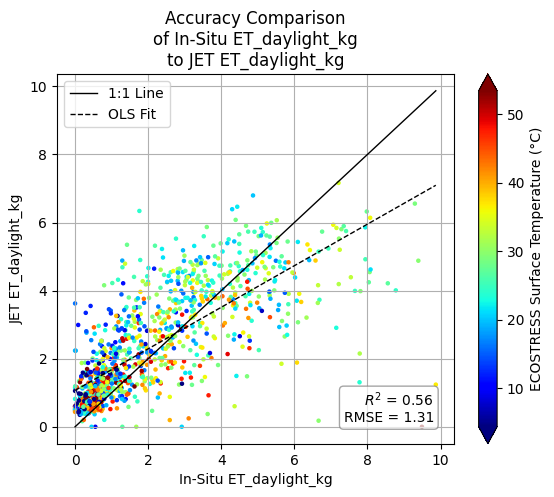

analyzing JET accuracy for G_Wm2 compared to insitu_G_Wm2


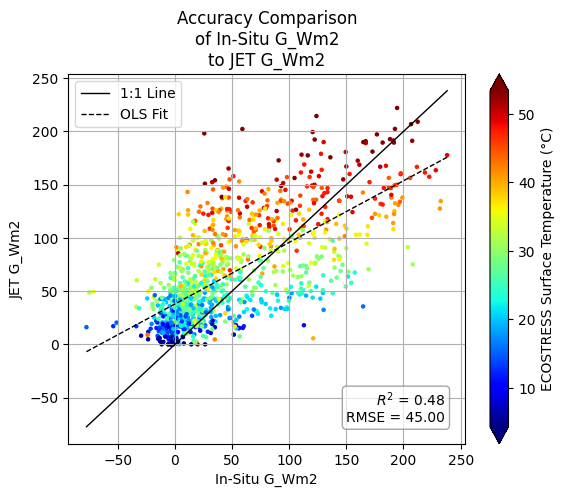

analyzing JET accuracy for H_Wm2 compared to insitu_H_Wm2


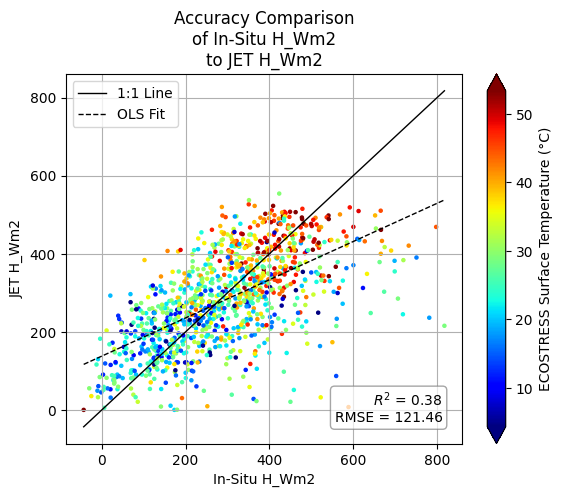

analyzing JET accuracy for LE_Wm2 compared to insitu_LE_Wm2


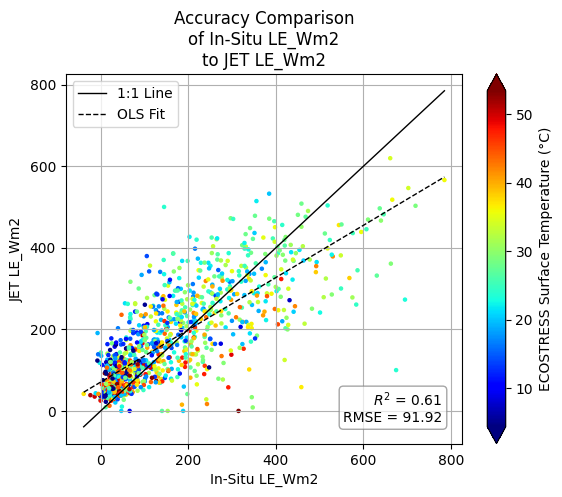

analyzing JET accuracy for LE_daylight_Wm2 compared to insitu_LE_daylight_Wm2
Error processing LE_daylight_Wm2: "['LE_daylight_Wm2'] not in index"
analyzing JET accuracy for RH compared to insitu_RH


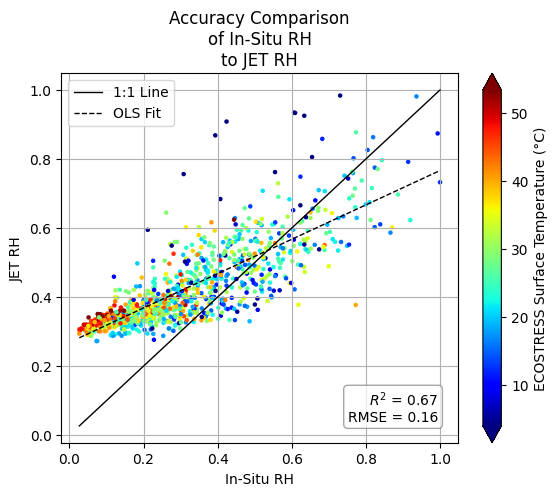

analyzing JET accuracy for Rn_Wm2 compared to insitu_Rn_Wm2


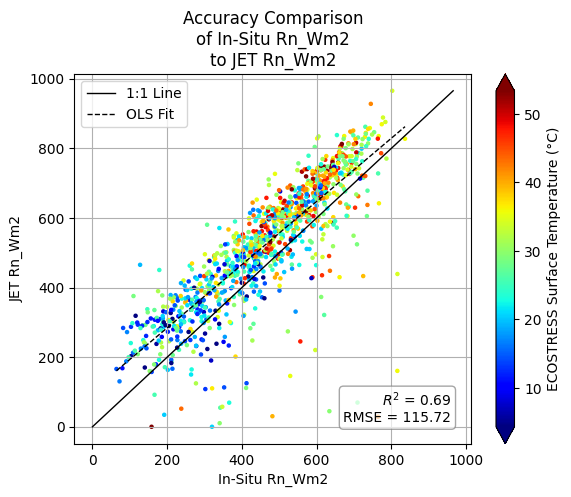

analyzing JET accuracy for Rn_daylight_Wm2 compared to insitu_Rn_daylight_Wm2
Error processing Rn_daylight_Wm2: "['Rn_daylight_Wm2'] not in index"
analyzing JET accuracy for SWin_Wm2 compared to insitu_SWin_Wm2


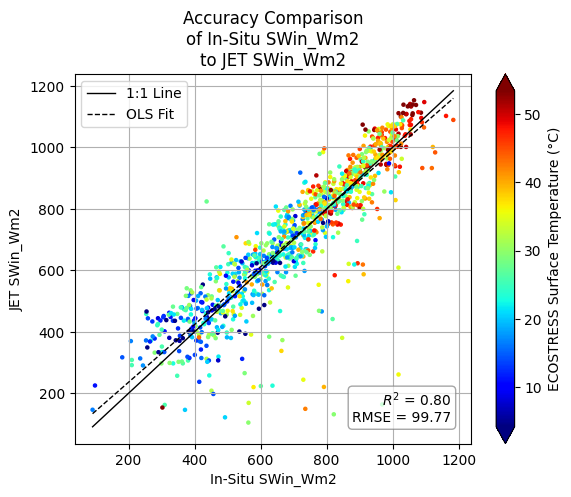

analyzing JET accuracy for Ta_C compared to insitu_Ta_C


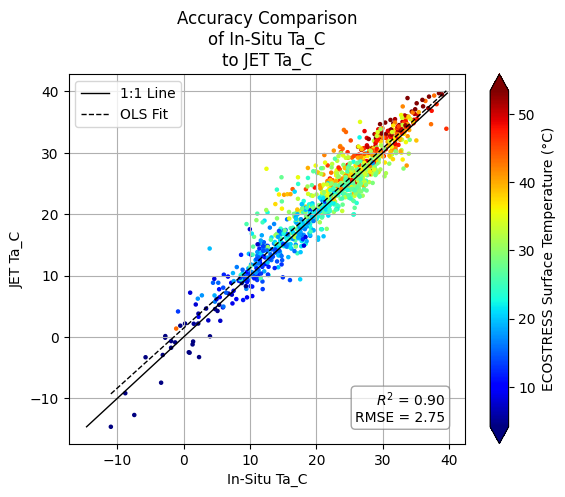

In [8]:
insitu_columns = sorted([column for column in processed.columns if "insitu" in column])

for insitu_variable in insitu_columns:
    output_variable = insitu_variable.replace("insitu_", "")
    print(f"analyzing {model_name} accuracy for {output_variable} compared to {insitu_variable}")
    
    try:
        generate_accuracy_plot(
            df=processed,
            x_variable=insitu_variable,
            y_variable=output_variable,
            output_variable=output_variable,
            model_name=model_name,
            save_plots=SAVE_PLOTS
        )
    except Exception as e:
        print(f"Error processing {output_variable}: {e}")
        continue

# Accuracy Comparison for Net Radiation between BESS and Verma

analyzing JET accuracy for Rn_BESS_Wm2 compared to insitu_Rn_Wm2


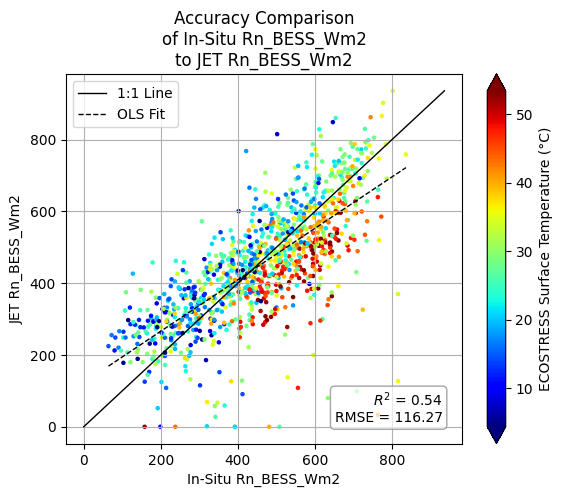

analyzing JET accuracy for Rn_verma_Wm2 compared to insitu_Rn_Wm2


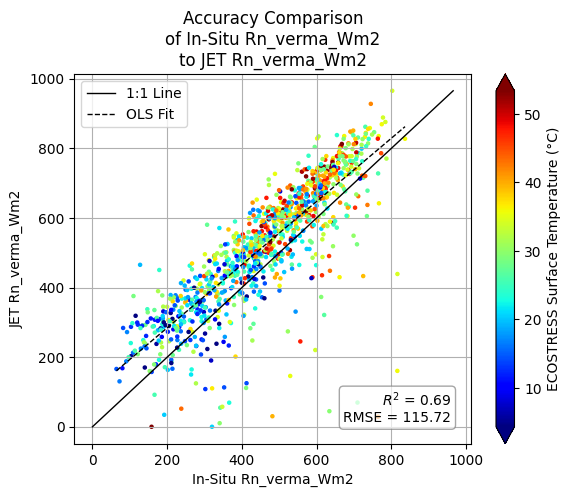

In [9]:
insitu_variable = "insitu_Rn_Wm2"

for output_variable in ["Rn_BESS_Wm2", "Rn_verma_Wm2"]:
    print(f"analyzing {model_name} accuracy for {output_variable} compared to {insitu_variable}")
    
    try:
        generate_accuracy_plot(
            df=processed,
            x_variable=insitu_variable,
            y_variable=output_variable,
            output_variable=output_variable,
            model_name=model_name,
            save_plots=SAVE_PLOTS
        )
    except Exception as e:
        print(f"Error processing {output_variable}: {e}")
        continue

analyzing JET accuracy for LE_BESS_Wm2 compared to insitu_LE_Wm2


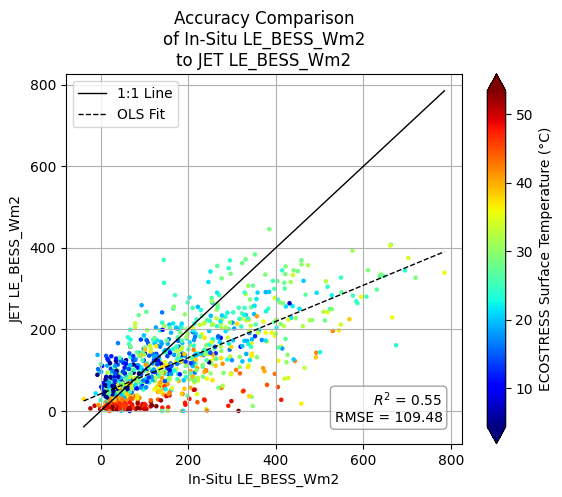

analyzing JET accuracy for LE_STIC_Wm2 compared to insitu_LE_Wm2


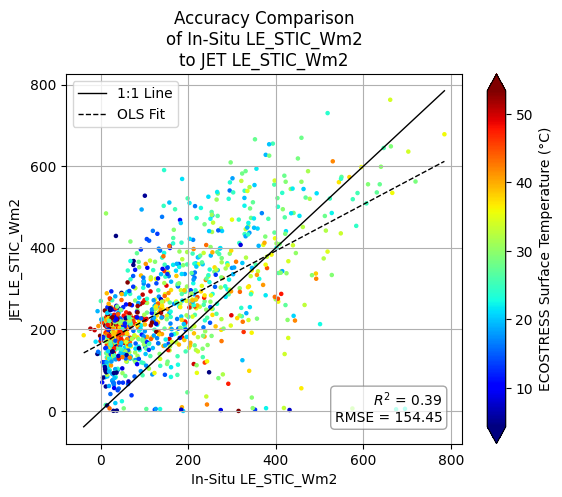

analyzing JET accuracy for LE_PTJPLSM_Wm2 compared to insitu_LE_Wm2


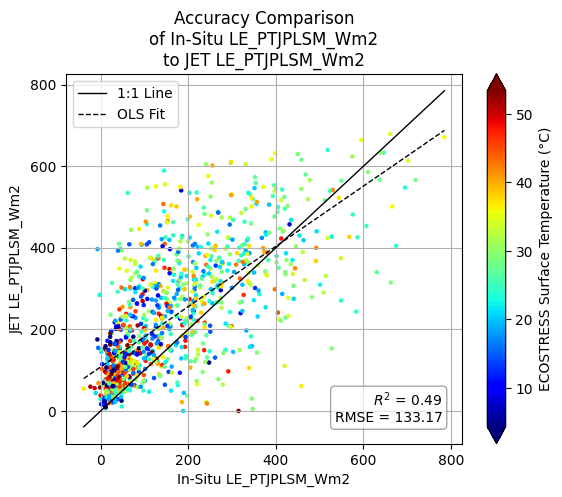

analyzing JET accuracy for LE_PMJPL_Wm2 compared to insitu_LE_Wm2


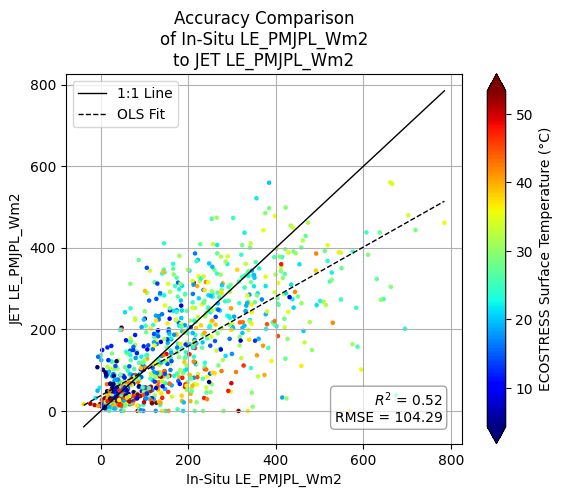

analyzing JET accuracy for LE_Wm2 compared to insitu_LE_Wm2


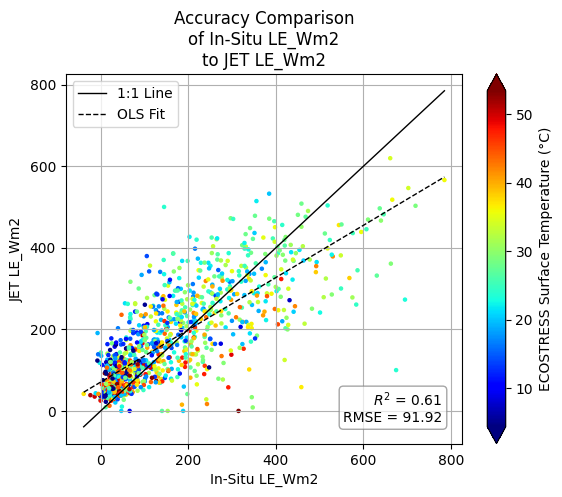

In [10]:
insitu_variable = "insitu_LE_Wm2"

output_variables = [
    "LE_BESS_Wm2",
    "LE_STIC_Wm2",
    "LE_PTJPLSM_Wm2",
    "LE_PMJPL_Wm2",
    "LE_Wm2"
]

for output_variable in output_variables:
    print(f"analyzing {model_name} accuracy for {output_variable} compared to {insitu_variable}")
    
    try:
        generate_accuracy_plot(
            df=processed,
            x_variable=insitu_variable,
            y_variable=output_variable,
            output_variable=output_variable,
            model_name=model_name,
            save_plots=SAVE_PLOTS
        )
    except Exception as e:
        print(f"Error processing {output_variable}: {e}")
        continue

In [11]:
import os
import contextlib
import math
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from SALib.sample import sobol as sobol_sample
from SALib.analyze import sobol

def SOBOL_sensitivity_analysis(
    input_df, 
    input_variables, 
    target_output, 
    forward_process, 
    custom_bounds=None, 
    groups=None,
    N=1024, 
    theme_name="whitegrid", 
    palette_name="viridis"
):
    """
    Generates Sobol samples from bounds, runs the forward model via a callback, 
    and computes/plots first-order (S1) and total-order (ST) Sobol indices.
    
    Parameters:
    - custom_bounds: Optional dictionary mapping variable names to [min, max].
    - groups: Optional list of group names matching the length of input_variables.
              Used to force rank-correlated dependent sampling for collinear inputs.
    """
    
    # 1. Clean the input table
    input_df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    
    # 2. Define problem bounds
    bounds = []
    for var in input_variables:
        if custom_bounds and var in custom_bounds:
            bounds.append(custom_bounds[var])
        else:
            bounds.append([input_df_clean[var].min(), input_df_clean[var].max()])
            
    problem = {
        'num_vars': len(input_variables),
        'names': input_variables,
        'bounds': bounds
    }
    
    # Inject groups if provided
    if groups is not None:
        if len(groups) != len(input_variables):
            raise ValueError("The 'groups' list must be exactly the same length as 'input_variables'.")
        problem['groups'] = groups
    
    # 3. Generate samples using SALib
    param_values = sobol_sample.sample(problem, N, calc_second_order=True)
    
    # 4. Create baseline dataset using the median of numeric columns 
    base_row = input_df_clean.iloc[[0]].copy()
    numeric_medians = input_df_clean.select_dtypes(include=[np.number]).median()
    
    for col in numeric_medians.index:
        base_row[col] = numeric_medians[col]
        
    # Broadcast base row and inject Sobol samples
    samples_df = pd.concat([base_row] * len(param_values), ignore_index=True)
    for i, var in enumerate(input_variables):
        samples_df[var] = param_values[:, i]
        
    # 5. Execute the forward run with suppressed console output
    print(f"Executing forward process for {len(samples_df)} generated samples...")
    
    with open(os.devnull, 'w') as fnull:
        with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
            processed_samples = forward_process(samples_df)
            
    print("Forward process complete.")
    
    # 6. Extract target output and handle NaNs safely
    Y = processed_samples[target_output].values
    
    if np.isnan(Y).any():
        nan_count = np.isnan(Y).sum()
        pct_missing = (nan_count / len(Y)) * 100
        warnings.warn(f"\nWarning: {nan_count} ({pct_missing:.2f}%) NaN values detected in output.")
        warnings.warn("Replacing NaNs with the mean of valid outputs. If missingness is high, variance indices will be artificially skewed.")
        
        valid_mean = np.nanmean(Y)
        Y = np.nan_to_num(Y, nan=valid_mean)
    
    # 7. Calculate Sobol indices
    Si = sobol.analyze(problem, Y, calc_second_order=True)
    
    # Floor negative indices at zero (numerical artifacts)
    for key in ['S1', 'ST', 'S2']:
        if key in Si and Si[key] is not None:
            Si[key] = np.maximum(0, Si[key])
    
    # When grouping is used, SALib outputs the grouped names in Si['names']
    analyzed_names = Si.get('names', input_variables)
    
    # Sort the variables based on ST descending
    sort_indices = np.argsort(Si['ST'])[::-1]
    sorted_vars = [analyzed_names[i] for i in sort_indices]
    sorted_S1 = Si['S1'][sort_indices]
    sorted_ST = Si['ST'][sort_indices]
    
    # 8. Visualize First-Order and Total-Order Indices
    sns.set_theme(style=theme_name)
    colors = sns.color_palette(palette_name, n_colors=2)
    
    # Slightly larger figure to accommodate bigger text
    fig, ax = plt.subplots(figsize=(12, 9))
    x = np.arange(len(sorted_vars))
    width = 0.35
    
    ax.bar(x - width/2, sorted_S1, width, label='$S_1$ (Direct Variance)', color=colors[0], edgecolor="white", linewidth=1)
    ax.bar(x + width/2, sorted_ST, width, label='$S_T$ (Includes Interactions)', color=colors[1], edgecolor="white", linewidth=1)
    
    # Increased font sizes for legibility
    ax.set_ylabel('Sobol Index', fontsize=16, weight='bold')
    title = f'Grouped Sobol Sensitivity' if groups else f'Sobol Sensitivity Indices'
    ax.set_title(f'{title} for {target_output}', fontsize=20, weight='bold', pad=20)
    
    ax.set_xticks(x)
    ax.set_xticklabels(sorted_vars, rotation=45, ha='right', fontsize=14)
    ax.tick_params(axis='y', labelsize=14)
    
    # Larger legend text
    ax.legend(frameon=True, facecolor='white', edgecolor='lightgray', fontsize=14)
    
    sns.despine(left=True)
    ax.grid(axis='y', linestyle='-', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    return Si


def SOBOL_scatter_analysis(
    input_df, 
    input_variables, 
    target_output, 
    forward_process, 
    custom_bounds=None,
    groups=None,
    N=1024, 
    theme_name="whitegrid"
):
    """
    Generates Sobol samples, runs the forward model, and computes Sobol indices.
    Outputs individual absolute main effect scatter plots with LOWESS trendlines.
    """
    # 1. Clean the input table
    input_df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    
    # 2. Define problem bounds
    bounds = []
    for var in input_variables:
        if custom_bounds and var in custom_bounds:
            bounds.append(custom_bounds[var])
        else:
            bounds.append([input_df_clean[var].min(), input_df_clean[var].max()])
            
    problem = {
        'num_vars': len(input_variables),
        'names': input_variables,
        'bounds': bounds
    }
    
    if groups is not None:
        if len(groups) != len(input_variables):
            raise ValueError("The 'groups' list must be exactly the same length as 'input_variables'.")
        problem['groups'] = groups
    
    # 3. Generate samples using SALib
    param_values = sobol_sample.sample(problem, N, calc_second_order=True)
    
    # 4. Create baseline dataset using the median of numeric columns 
    base_row = input_df_clean.iloc[[0]].copy()
    numeric_medians = input_df_clean.select_dtypes(include=[np.number]).median()
    
    for col in numeric_medians.index:
        base_row[col] = numeric_medians[col]
        
    # Broadcast base row and inject Sobol samples
    samples_df = pd.concat([base_row] * len(param_values), ignore_index=True)
    for i, var in enumerate(input_variables):
        samples_df[var] = param_values[:, i]
        
    # 5. Execute the forward run with suppressed console output
    print(f"Executing forward process for {len(samples_df)} generated samples (console output hidden)...")
    
    with open(os.devnull, 'w') as fnull:
        with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
            processed_samples = forward_process(samples_df)
            
    print("Forward process complete.")
    
    # 6. Extract the target output values and check for NaNs safely
    Y = processed_samples[target_output].values
    
    if np.isnan(Y).any():
        nan_count = np.isnan(Y).sum()
        pct_missing = (nan_count / len(Y)) * 100
        warnings.warn(f"\nWarning: {nan_count} ({pct_missing:.2f}%) NaN values detected in output.")
        warnings.warn("Replacing NaNs with the mean of valid outputs.")
        
        valid_mean = np.nanmean(Y)
        Y = np.nan_to_num(Y, nan=valid_mean)
    
    # 7. Calculate Sobol indices
    Si = sobol.analyze(problem, Y, calc_second_order=True)
    
    # Floor negative indices at zero
    for key in ['S1', 'ST', 'S2']:
        if key in Si and Si[key] is not None:
            Si[key] = np.maximum(0, Si[key])
    
    # 8. Visualize Absolute Main Effect Scatter Plots (Individually)
    print("Generating main effect scatter plots...")
    sns.set_theme(style=theme_name)
    
    # Build a DataFrame specifically for plotting
    plot_df = pd.DataFrame(param_values, columns=input_variables)
    plot_df[target_output] = Y
    
    for i, var in enumerate(input_variables):
        # Create a new, standalone figure for each variable
        fig, ax = plt.subplots(figsize=(6, 4.5))
        
        sns.regplot(
            data=plot_df, 
            x=var, 
            y=target_output, 
            ax=ax, 
            scatter_kws={'alpha': 0.2, 's': 8, 'edgecolor': 'none'}, 
            line_kws={'color': 'red', 'linewidth': 2.5},
            lowess=True
        )
        
        # If grouped, show the group name in the title for clarity
        group_label = f" (Group: {groups[i]})" if groups else ""
        ax.set_title(f'{var}{group_label}', weight='bold')
        ax.set_ylabel(f'Absolute {target_output}')
        ax.set_xlabel(f'Sampled {var}')
        ax.grid(True, linestyle='--', alpha=0.6)
        
        plt.tight_layout()
        plt.show()  # Renders the current figure so it outputs to the notebook cell immediately
    
    return Si

def SOBOL_pairwise_analysis(
    input_df, 
    input_variables, 
    target_output, 
    forward_process, 
    custom_bounds=None,
    groups=None,
    N=1024, 
    theme_name="whitegrid",
    colormap="viridis"
):
    """
    Generates Sobol samples, runs the forward model, and computes Sobol indices.
    Outputs a pairwise corner plot of the sampled variables, colored by the target output 
    to visualize parameter interactions and the response surface.
    """
    # 1. Clean the input table
    input_df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    
    # 2. Define problem bounds
    bounds = []
    for var in input_variables:
        if custom_bounds and var in custom_bounds:
            bounds.append(custom_bounds[var])
        else:
            bounds.append([input_df_clean[var].min(), input_df_clean[var].max()])
            
    problem = {
        'num_vars': len(input_variables),
        'names': input_variables,
        'bounds': bounds
    }
    
    if groups is not None:
        if len(groups) != len(input_variables):
            raise ValueError("The 'groups' list must be exactly the same length as 'input_variables'.")
        problem['groups'] = groups
    
    # 3. Generate samples using SALib
    param_values = sobol_sample.sample(problem, N, calc_second_order=True)
    
    # 4. Create baseline dataset using the median of numeric columns 
    base_row = input_df_clean.iloc[[0]].copy()
    numeric_medians = input_df_clean.select_dtypes(include=[np.number]).median()
    
    for col in numeric_medians.index:
        base_row[col] = numeric_medians[col]
        
    # Broadcast base row and inject Sobol samples
    samples_df = pd.concat([base_row] * len(param_values), ignore_index=True)
    for i, var in enumerate(input_variables):
        samples_df[var] = param_values[:, i]
        
    # 5. Execute the forward run with suppressed console output
    print(f"Executing forward process for {len(samples_df)} generated samples (console output hidden)...")
    
    with open(os.devnull, 'w') as fnull:
        with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
            processed_samples = forward_process(samples_df)
            
    print("Forward process complete.")
    
    # 6. Extract the target output values and check for NaNs safely
    Y = processed_samples[target_output].values
    
    if np.isnan(Y).any():
        nan_count = np.isnan(Y).sum()
        pct_missing = (nan_count / len(Y)) * 100
        warnings.warn(f"\nWarning: {nan_count} ({pct_missing:.2f}%) NaN values detected in output.")
        warnings.warn("Replacing NaNs with the mean of valid outputs.")
        
        valid_mean = np.nanmean(Y)
        Y = np.nan_to_num(Y, nan=valid_mean)
    
    # 7. Calculate Sobol indices
    Si = sobol.analyze(problem, Y, calc_second_order=True)
    
    # Floor negative indices at zero
    for key in ['S1', 'ST', 'S2']:
        if key in Si and Si[key] is not None:
            Si[key] = np.maximum(0, Si[key])
    
    # 8. Visualize Pair-wise Plots
    print("Generating pair-wise scatter plots...")
    sns.set_theme(style=theme_name)
    
    plot_df = pd.DataFrame(param_values, columns=input_variables)
    plot_df[target_output] = Y
    
    # Custom mapping function for the lower triangle to allow color mapping
    def scatter_colored(x, y, **kwargs):
        plt.scatter(x, y, c=Y, cmap=colormap, alpha=0.5, s=8, edgecolors='none')
        
    # Create the PairGrid (corner=True hides the redundant upper triangle)
    g = sns.PairGrid(plot_df, vars=input_variables, corner=True, height=2.5)
    
    # Map the lower triangle to the colored scatter and the diagonal to histograms
    g.map_lower(scatter_colored)
    g.map_diag(sns.histplot, color="gray", bins=25, alpha=0.6)
    
    # Add a unified colorbar for the figure
    sm = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(vmin=Y.min(), vmax=Y.max()))
    sm.set_array([])
    
    # Position the colorbar in the empty upper-right space
    cbar_ax = g.fig.add_axes([0.65, 0.65, 0.02, 0.25]) 
    g.fig.colorbar(sm, cax=cbar_ax, label=f'{target_output} Intensity')
    
    g.fig.suptitle(f"Pair-wise Interaction Map for {target_output}", y=1.02, fontsize=16, weight='bold')
    
    plt.show()
    
    return Si

Executing forward process for 3072 generated samples...
[2026-08-27 10:36:57 INFO] starting JET table processing
[2026-08-27 10:36:57 INFO] started extracting geometry from JET input table
[2026-08-27 10:36:57 INFO] completed extracting geometry from JET input table (0.024 seconds)
[2026-08-27 10:36:57 INFO] started extracting time from JET input table
[2026-08-27 10:36:57 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:36:57 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:36:57 INFO] completed processing FLiES-ANN in 0.23 seconds
[2026-08-27 10:36:57 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:36:57 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:36:57 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:36:57 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:36:57 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.00% (nan)
[2026-08-27 10:

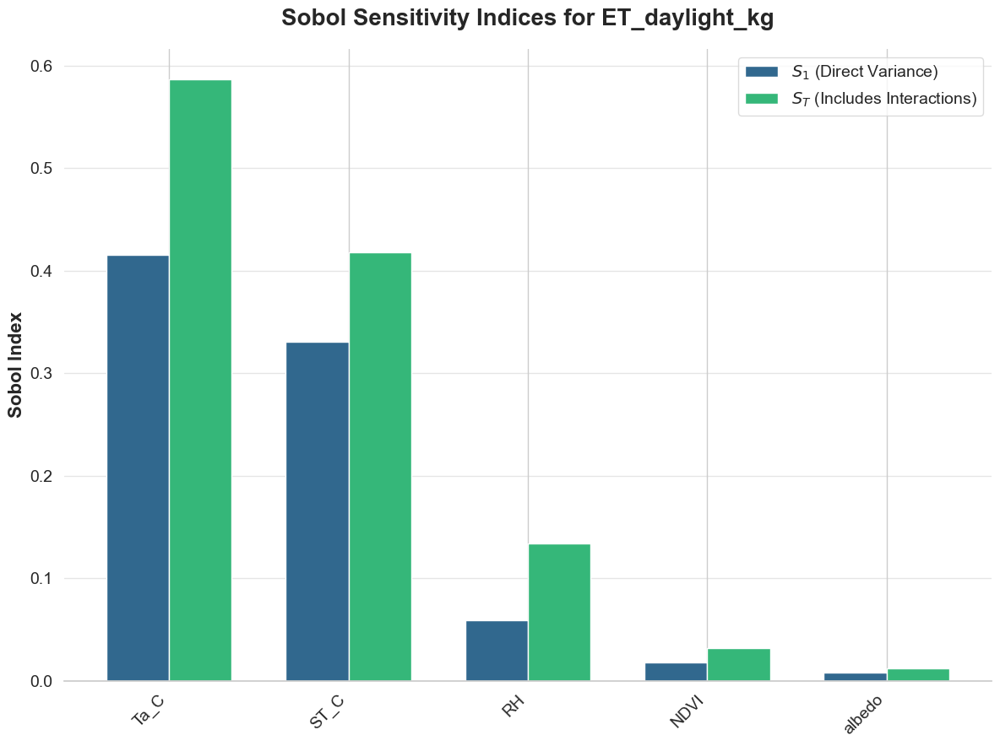

In [12]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:36:59 INFO] starting JET table processing
[2026-08-27 10:36:59 INFO] started extracting geometry from JET input table
[2026-08-27 10:36:59 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:36:59 INFO] started extracting time from JET input table
[2026-08-27 10:36:59 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:36:59 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:36:59 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:36:59 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:36:59 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:36:59 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:36:59 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:36:59 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.0

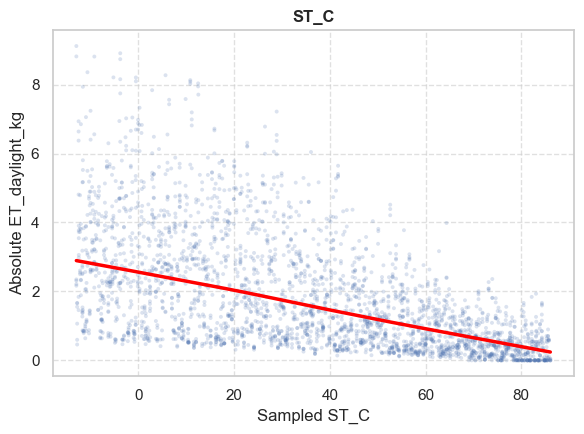

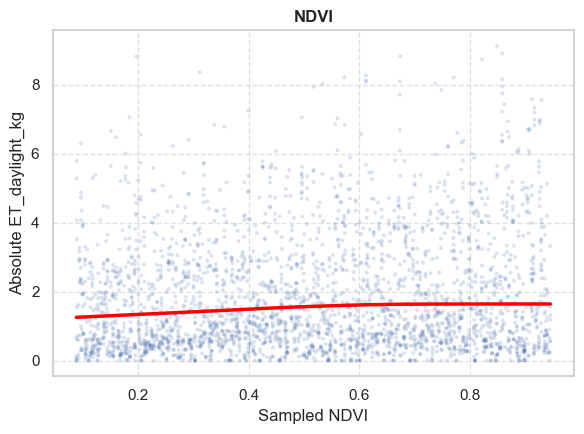

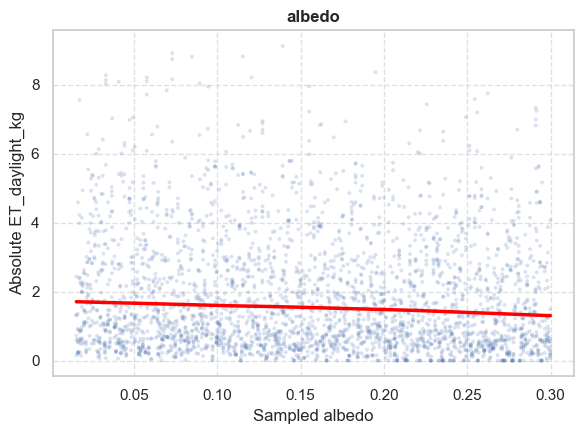

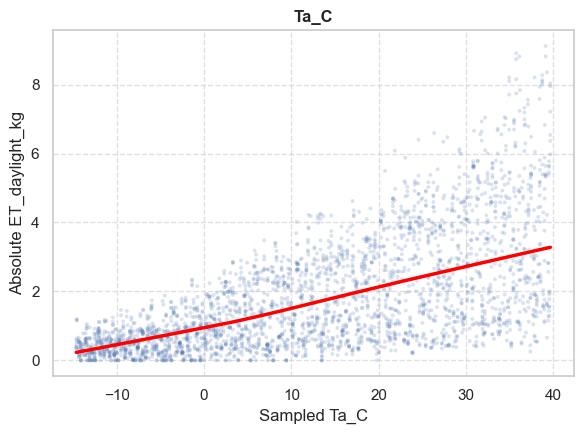

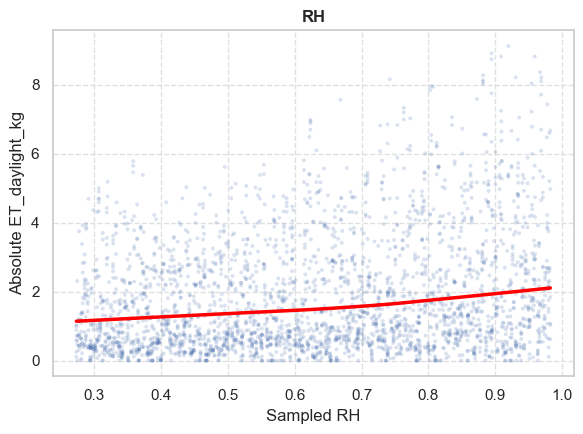

In [13]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:01 INFO] starting JET table processing
[2026-08-27 10:37:01 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:01 INFO] completed extracting geometry from JET input table (0.027 seconds)
[2026-08-27 10:37:01 INFO] started extracting time from JET input table
[2026-08-27 10:37:01 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:01 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:01 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:01 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:01 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:01 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:01 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:01 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.0

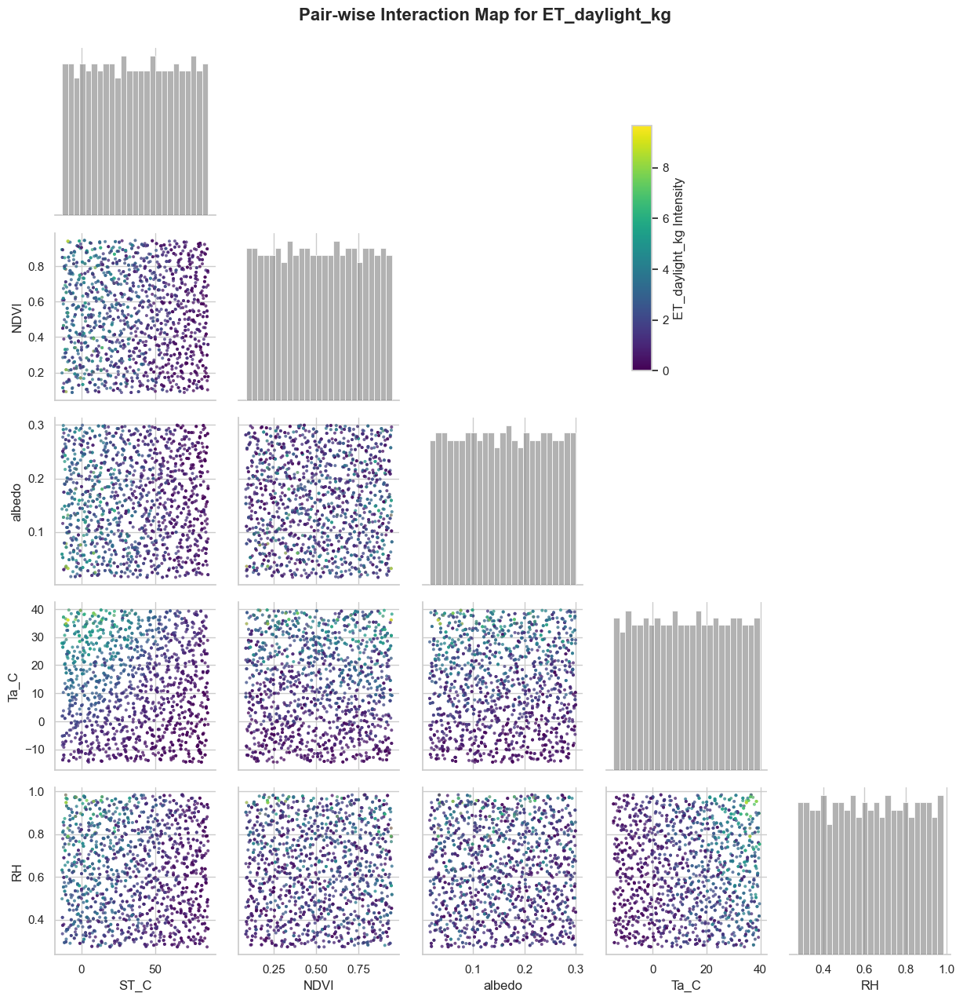

In [14]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_pairwise_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:03 INFO] starting JET table processing
[2026-08-27 10:37:03 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:03 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:37:03 INFO] started extracting time from JET input table
[2026-08-27 10:37:03 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:03 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:03 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:03 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:03 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:03 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:03 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:03 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.00% (nan)
[2026-08-27 10:

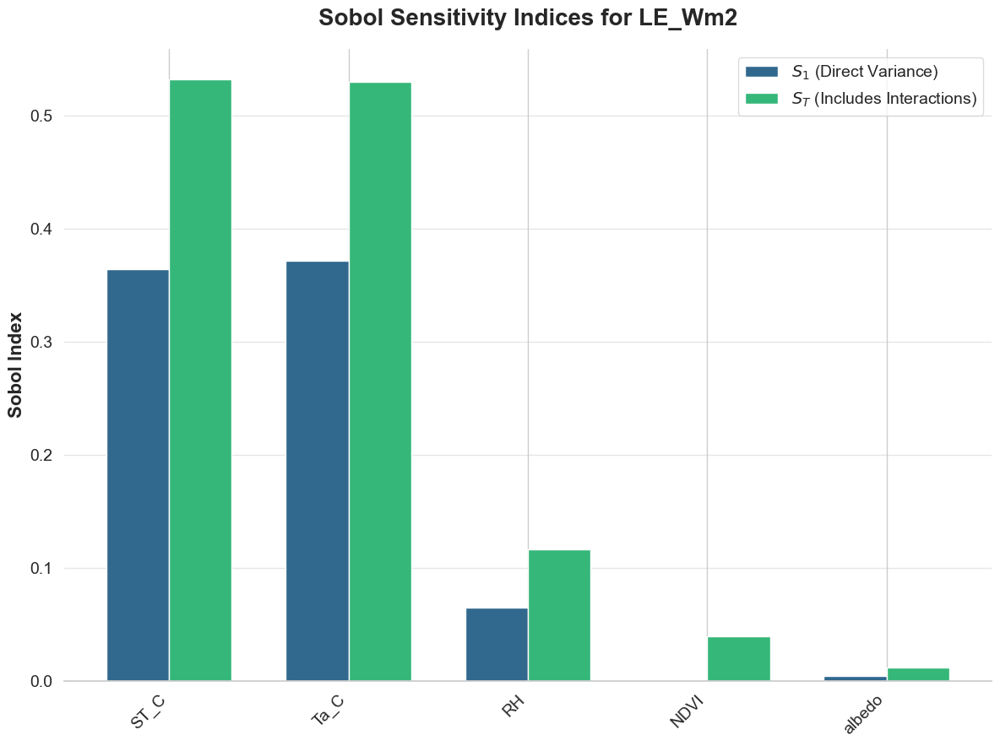

In [15]:
target_output = "LE_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:05 INFO] starting JET table processing
[2026-08-27 10:37:05 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:05 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:37:05 INFO] started extracting time from JET input table
[2026-08-27 10:37:05 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:05 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:05 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:05 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:05 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:05 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:05 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:05 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.047 nan: 0.00% (nan)
[2026-08-27 10:

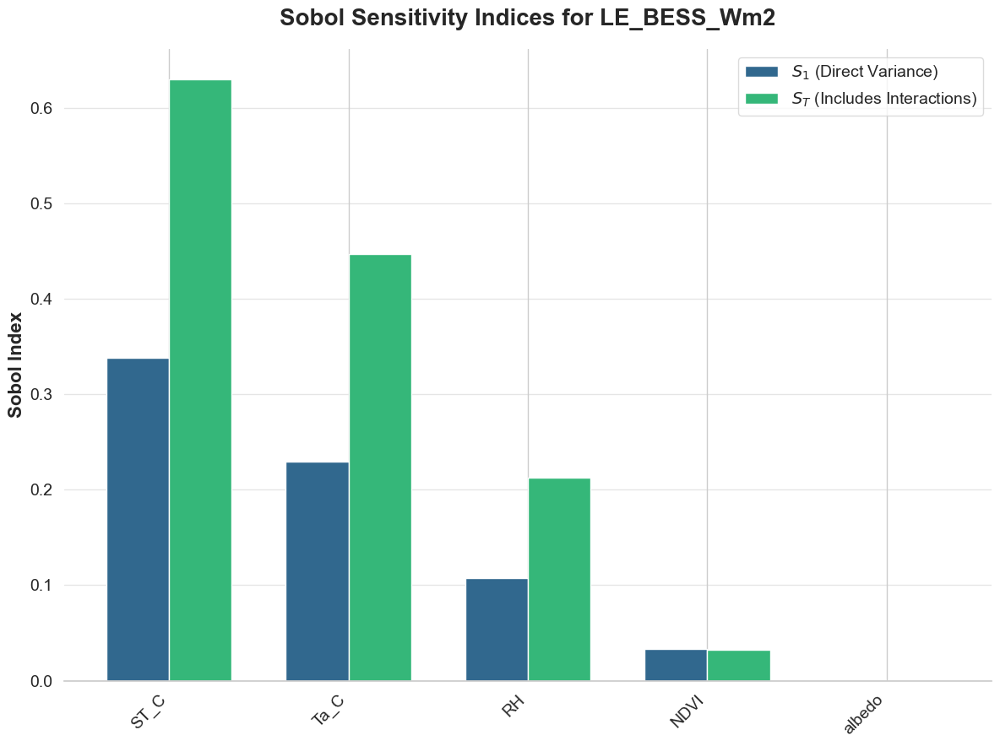

In [16]:
target_output = "LE_BESS_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:07 INFO] starting JET table processing
[2026-08-27 10:37:07 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:07 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:07 INFO] started extracting time from JET input table
[2026-08-27 10:37:07 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:07 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:07 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:07 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:07 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:07 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:07 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:07 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.050 nan: 0.00% (nan)
[2026-08-27 10:

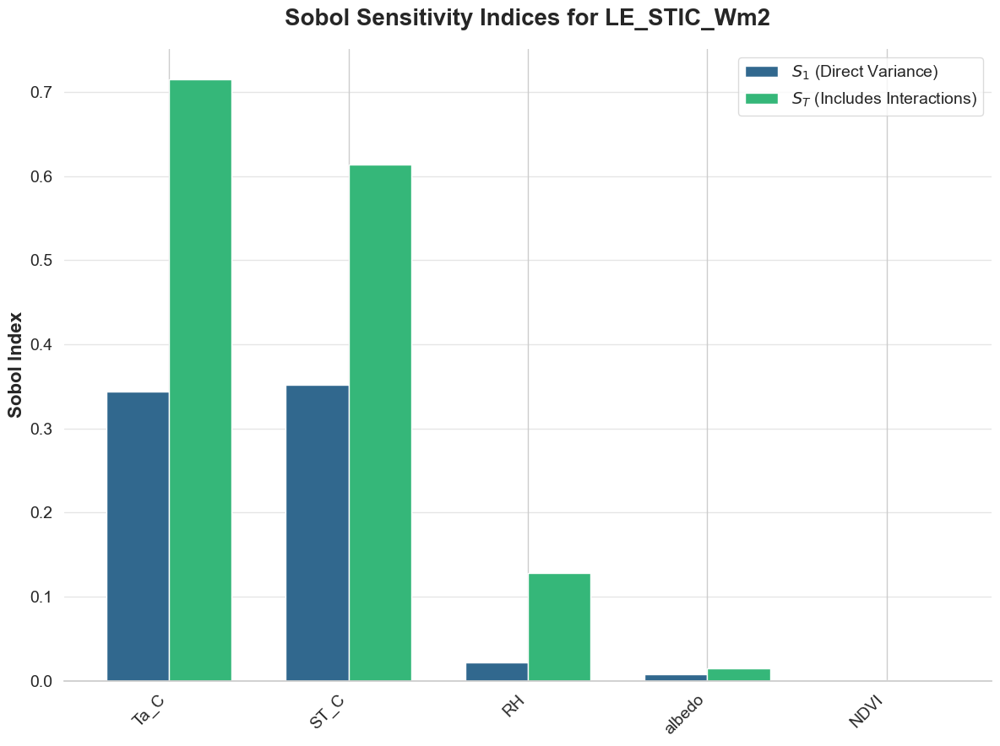

In [17]:
target_output = "LE_STIC_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:08 INFO] starting JET table processing
[2026-08-27 10:37:08 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:08 INFO] completed extracting geometry from JET input table (0.027 seconds)
[2026-08-27 10:37:08 INFO] started extracting time from JET input table
[2026-08-27 10:37:08 INFO] completed extracting time from JET input table (0.117 seconds)
[2026-08-27 10:37:08 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:09 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:09 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:09 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:09 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:09 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:09 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.0

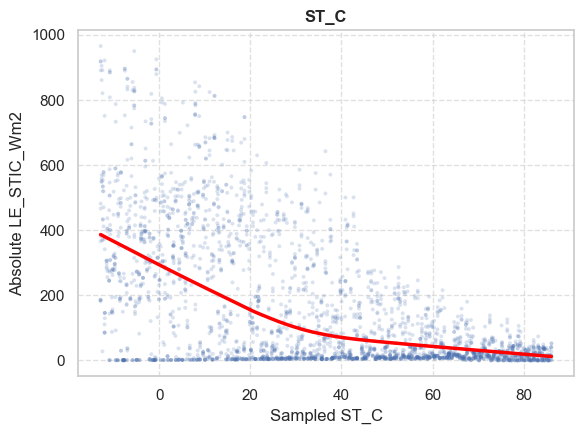

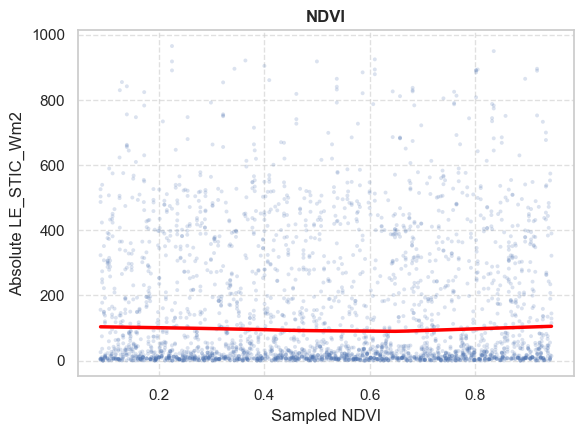

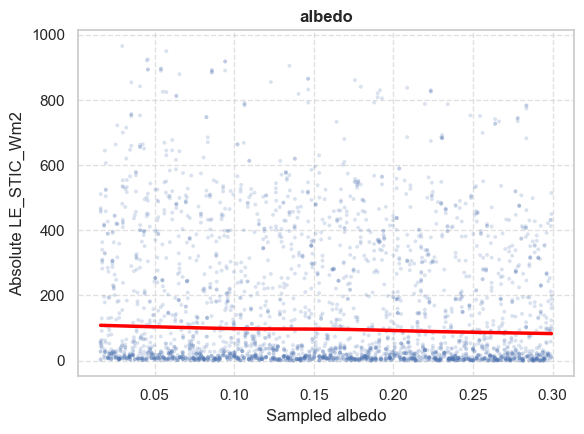

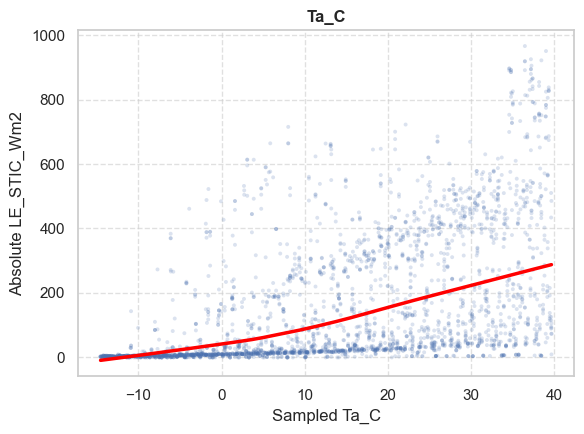

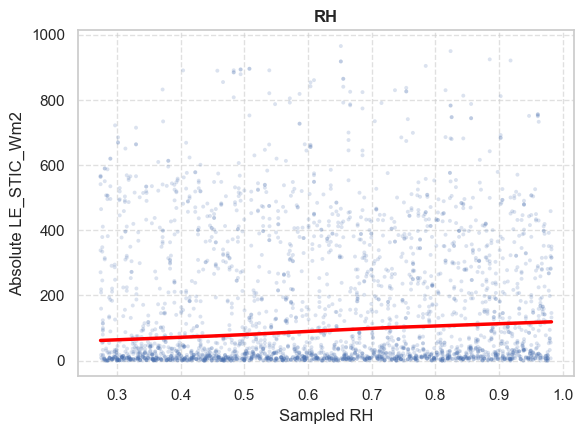

In [18]:
target_output = "LE_STIC_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:10 INFO] starting JET table processing
[2026-08-27 10:37:10 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:10 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:10 INFO] started extracting time from JET input table
[2026-08-27 10:37:10 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:10 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:11 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:11 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:11 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:11 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:11 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:11 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.00% (nan)
[2026-08-27 10:

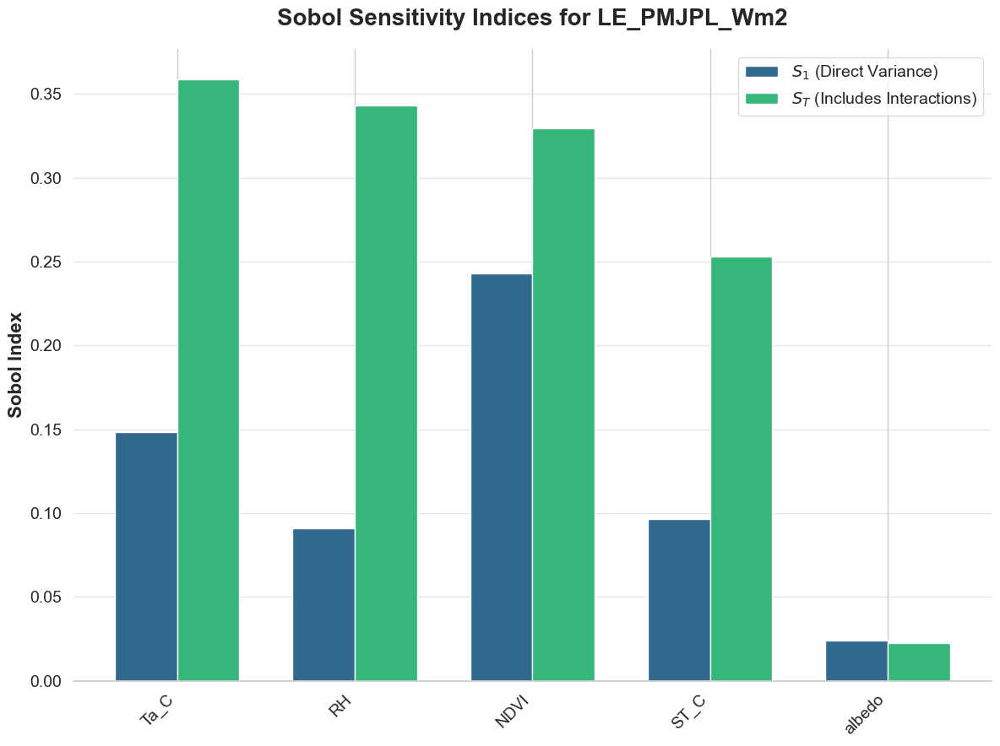

In [19]:
target_output = "LE_PMJPL_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:12 INFO] starting JET table processing
[2026-08-27 10:37:12 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:12 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:12 INFO] started extracting time from JET input table
[2026-08-27 10:37:12 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:12 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:12 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:12 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:12 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:12 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:12 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:12 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.0

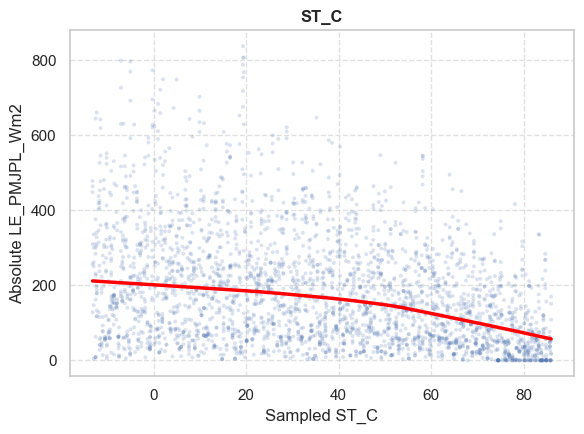

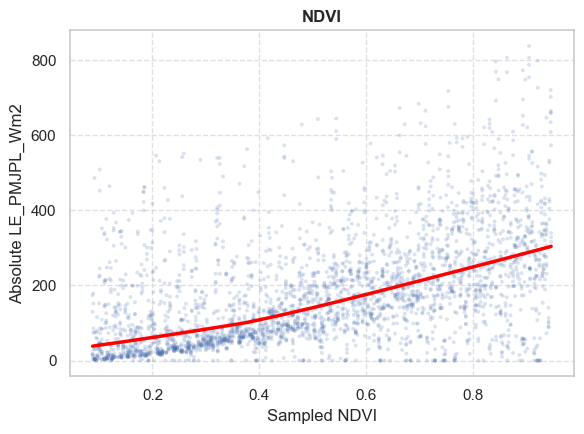

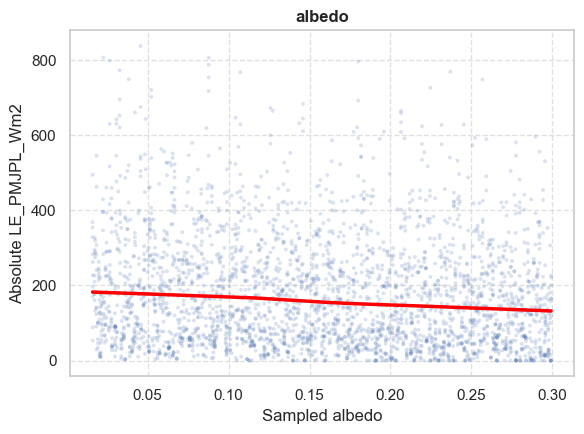

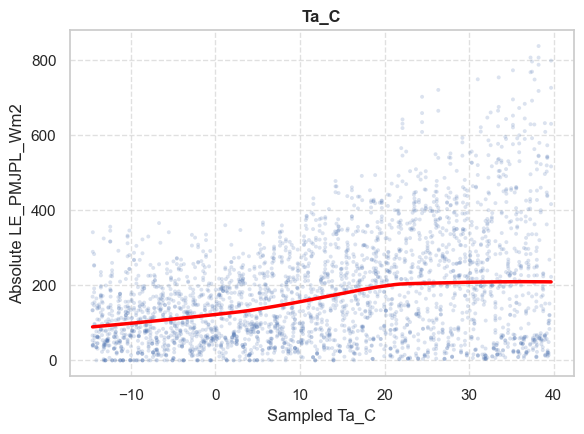

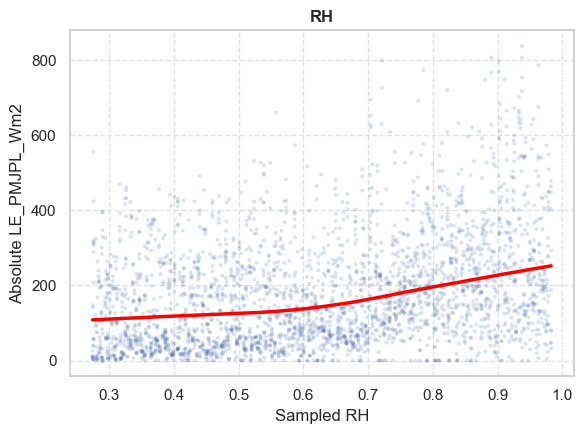

In [20]:
target_output = "LE_PMJPL_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:14 INFO] starting JET table processing
[2026-08-27 10:37:14 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:14 INFO] completed extracting geometry from JET input table (0.027 seconds)
[2026-08-27 10:37:14 INFO] started extracting time from JET input table
[2026-08-27 10:37:14 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:14 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:14 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:14 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:14 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:14 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:14 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:14 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.050 nan: 0.00% (nan)
[2026-08-27 10:

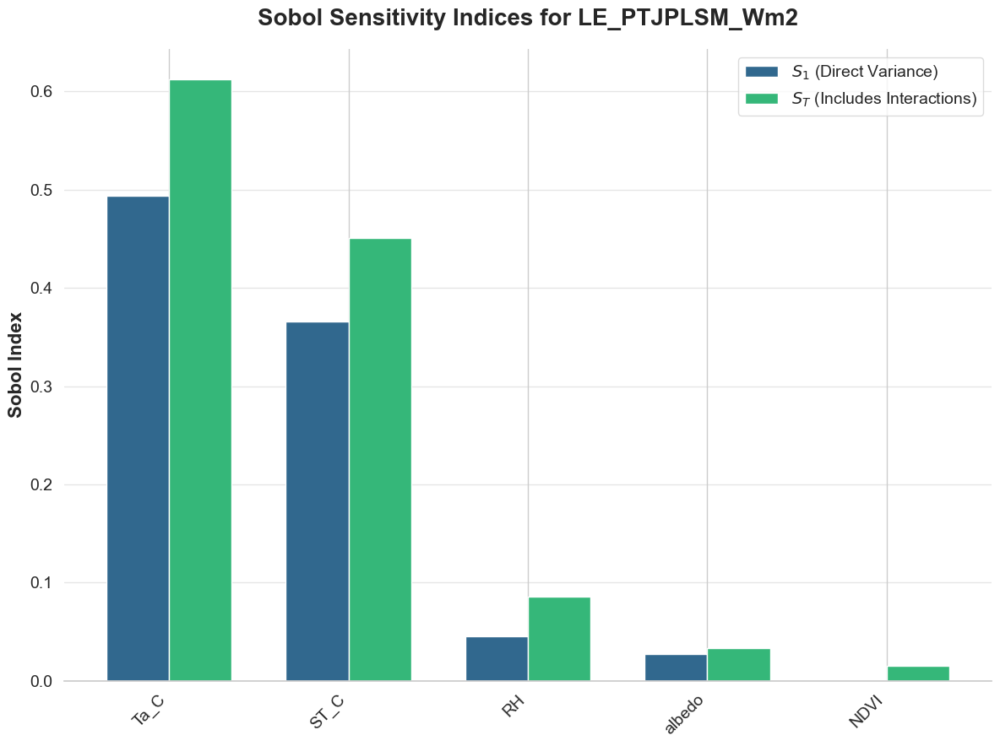

In [21]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:16 INFO] starting JET table processing
[2026-08-27 10:37:16 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:16 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:16 INFO] started extracting time from JET input table
[2026-08-27 10:37:16 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:16 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:16 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:16 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:16 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:16 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:16 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:16 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.0

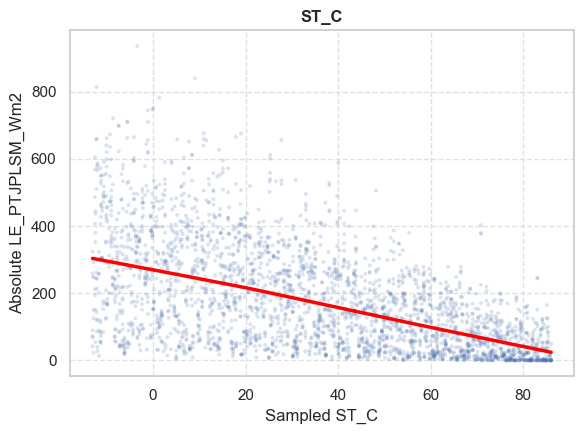

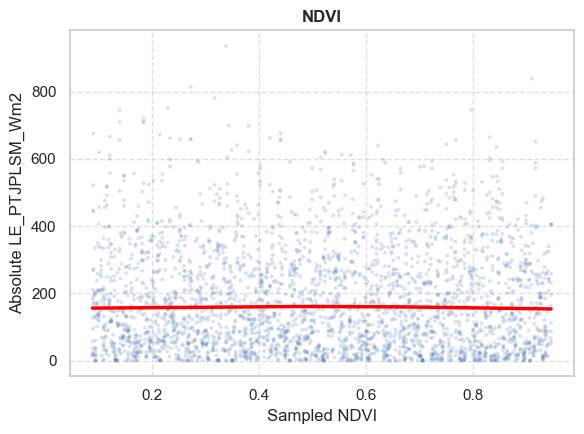

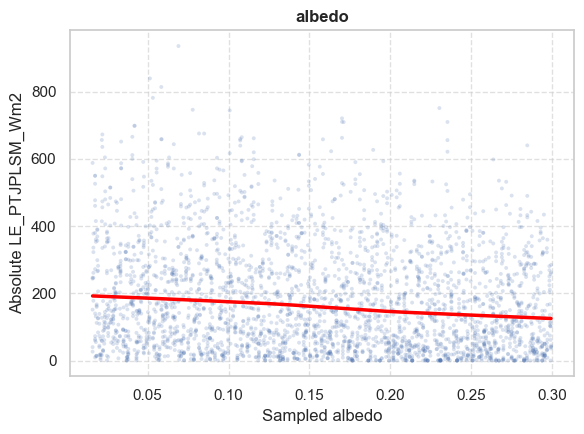

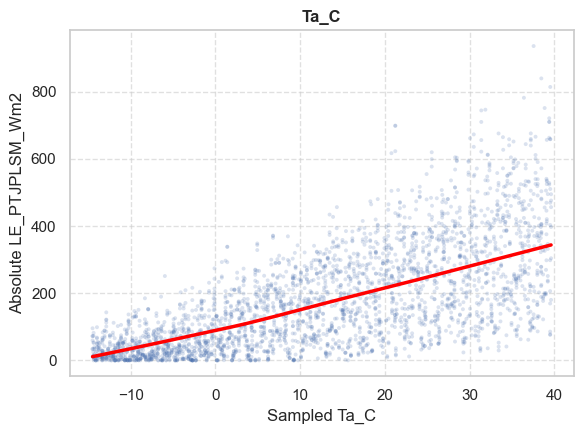

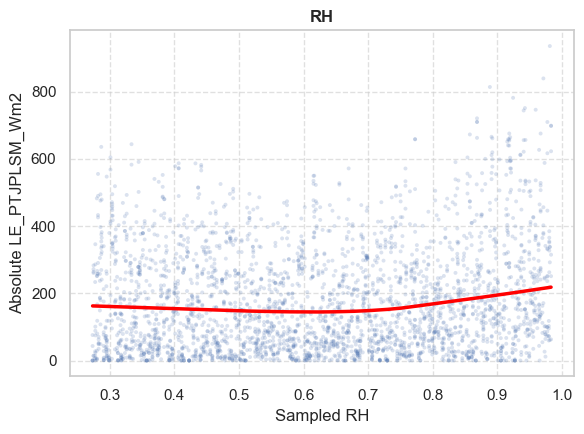

In [22]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 2048 generated samples...
[2026-08-27 10:37:18 INFO] starting JET table processing
[2026-08-27 10:37:18 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:18 INFO] completed extracting geometry from JET input table (0.018 seconds)
[2026-08-27 10:37:18 INFO] started extracting time from JET input table
[2026-08-27 10:37:18 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:18 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:18 INFO] completed processing FLiES-ANN in 0.17 seconds
[2026-08-27 10:37:18 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:18 INFO] * 0.0444982903496672: 2048
[2026-08-27 10:37:18 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:18 INFO] * 0.1450579477239534: 2048
[2026-08-27 10:37:18 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.00% (nan)
[2026-08-27 10:

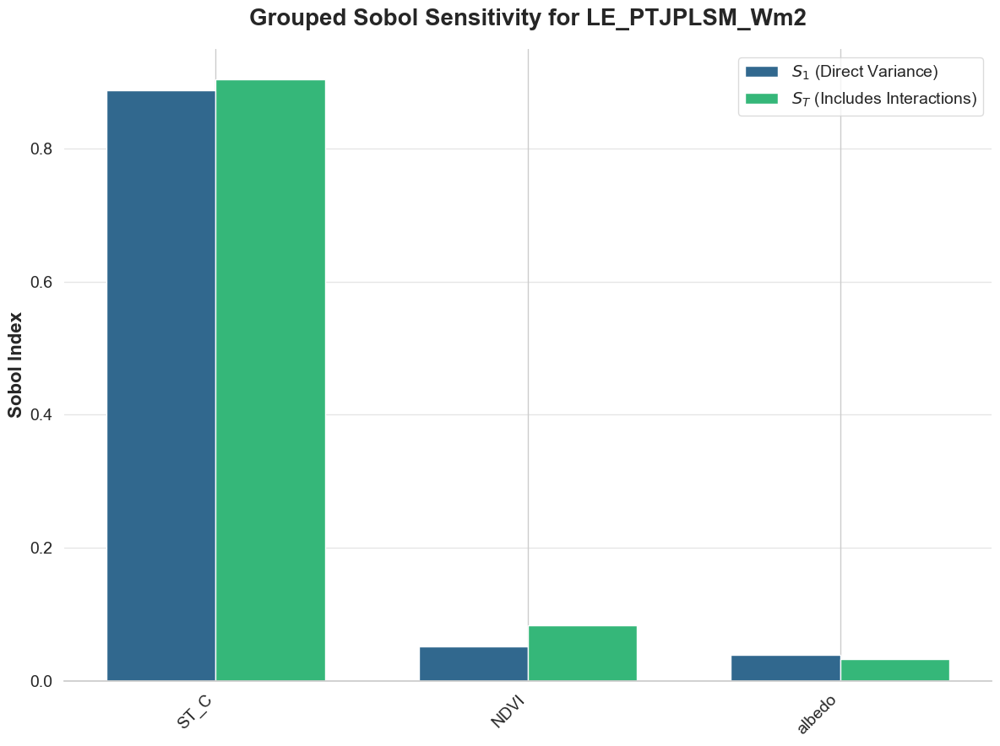

In [23]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

groups = [
    "Thermal", "Infrared", "Optical", "Thermal", "Infrared"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
    groups=groups
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:19 INFO] starting JET table processing
[2026-08-27 10:37:19 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:19 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:19 INFO] started extracting time from JET input table
[2026-08-27 10:37:19 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:19 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:19 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:19 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:19 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:19 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:19 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:19 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.00% (nan)
[2026-08-27 10:

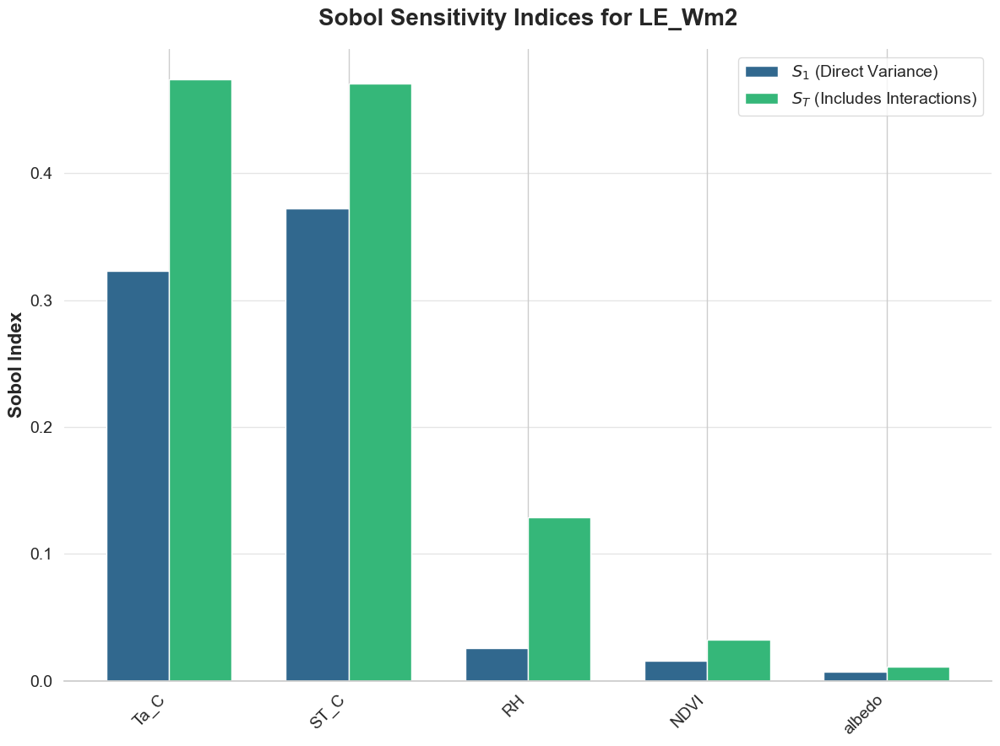

In [24]:
target_output = "LE_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:21 INFO] starting JET table processing
[2026-08-27 10:37:21 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:21 INFO] completed extracting geometry from JET input table (0.027 seconds)
[2026-08-27 10:37:21 INFO] started extracting time from JET input table
[2026-08-27 10:37:21 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:21 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:21 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:21 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:21 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:21 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:21 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:21 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.050 nan: 0.0

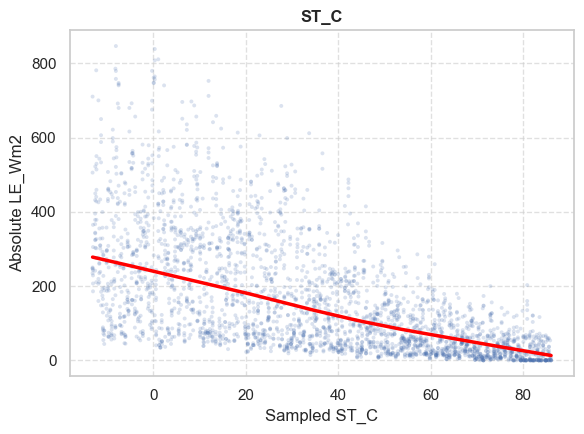

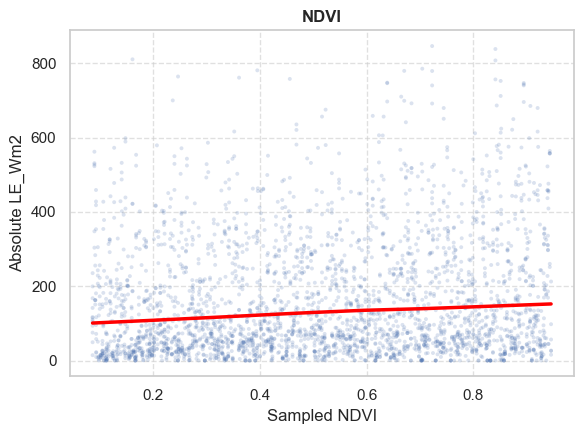

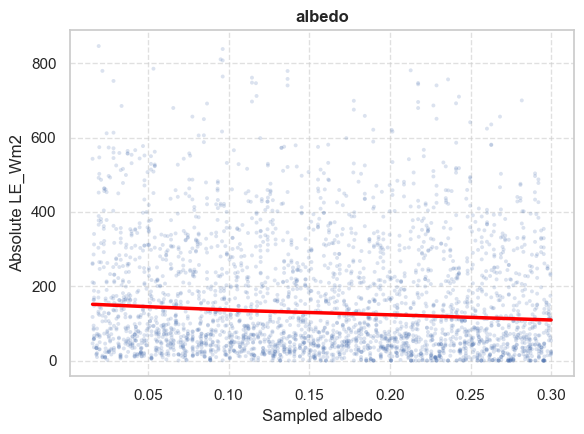

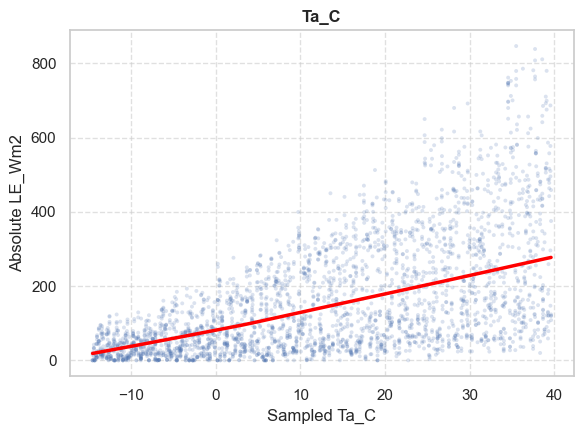

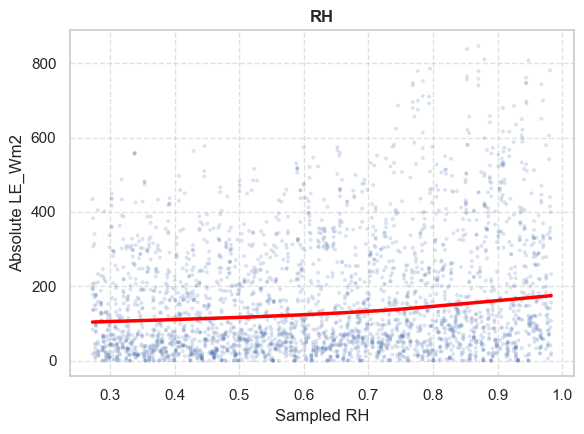

In [25]:
target_output = "LE_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 1536 generated samples...
[2026-08-27 10:37:23 INFO] starting JET table processing
[2026-08-27 10:37:23 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:23 INFO] completed extracting geometry from JET input table (0.013 seconds)
[2026-08-27 10:37:23 INFO] started extracting time from JET input table
[2026-08-27 10:37:23 INFO] completed extracting time from JET input table (0.001 seconds)
[2026-08-27 10:37:23 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:23 INFO] completed processing FLiES-ANN in 0.15 seconds
[2026-08-27 10:37:23 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:23 INFO] * 0.0444982903496672: 1536
[2026-08-27 10:37:23 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:23 INFO] * 0.1450579477239534: 1536
[2026-08-27 10:37:23 INFO] variable PAR_direct_Wm2 (float32) with [300.81683] unique values
[2026-08-27 10:37:23 INFO] * 30

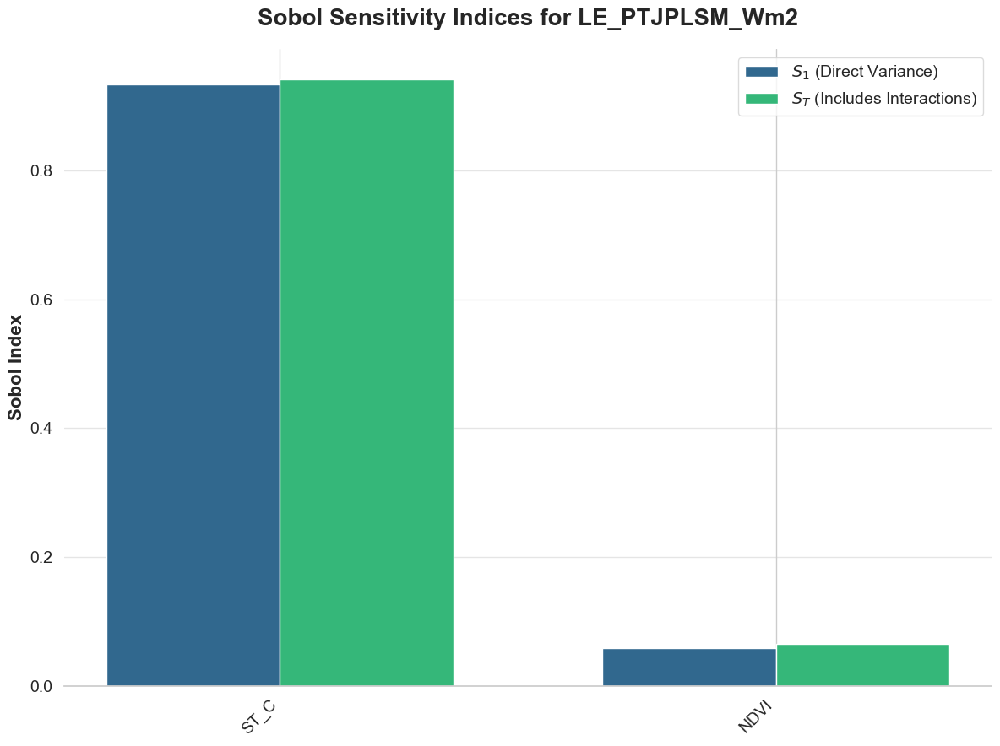

In [26]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

def analyze_input_collinearity(
    input_df, 
    input_variables, 
    theme_name="whitegrid", 
    cmap_name="coolwarm"
):
    """
    Analyzes and visualizes the collinearity of input variables using a 
    Pearson correlation heatmap and calculates Variance Inflation Factors (VIF).
    
    Returns:
    - corr_matrix: DataFrame containing the Pearson correlation coefficients.
    - vif_data: DataFrame containing the computed VIF for each variable.
    """
    
    # 1. Clean the input table
    df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    X = df_clean[input_variables]
    
    # 2. Compute Pearson Correlation Matrix
    corr_matrix = X.corr()
    
    # 3. Compute Variance Inflation Factor (VIF)
    # Add a constant (intercept) to baseline the VIF calculation properly
    X_vif = X.copy()
    X_vif['intercept'] = 1 
    
    vif_data = pd.DataFrame()
    vif_data["Variable"] = input_variables
    vif_data["VIF"] = [
        variance_inflation_factor(X_vif.values, i) 
        for i in range(len(input_variables))
    ]
    
    # 4. Visualization Setup
    sns.set_theme(style=theme_name)
    fig = plt.figure(figsize=(14, 6))
    
    # --- Subplot 1: Correlation Heatmap ---
    ax1 = fig.add_subplot(1, 2, 1)
    
    # Create a mask to hide the upper triangle for a cleaner look
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    sns.heatmap(
        corr_matrix, 
        mask=mask, 
        cmap=cmap_name, 
        vmax=1.0, 
        vmin=-1.0, 
        center=0, 
        annot=True, 
        fmt=".2f", 
        square=True, 
        linewidths=.5, 
        cbar_kws={"shrink": .8},
        ax=ax1
    )
    ax1.set_title("Pearson Correlation Matrix", weight='bold', fontsize=14, pad=15)
    
    # --- Subplot 2: VIF Bar Chart ---
    ax2 = fig.add_subplot(1, 2, 2)
    
    # Extract a color from the colormap for the bars
    bar_color = sns.color_palette(cmap_name)[-1] 
    
    sns.barplot(
        data=vif_data, 
        x="VIF", 
        y="Variable", 
        color=bar_color, 
        ax=ax2,
        edgecolor="white"
    )
    
    # Add a vertical threshold line at VIF = 5 (standard threshold for high collinearity)
    ax2.axvline(x=5, color='red', linestyle='--', linewidth=1.5, label='High Collinearity Threshold (VIF=5)')
    
    ax2.set_title("Variance Inflation Factor (VIF)", weight='bold', fontsize=14, pad=15)
    ax2.set_xlabel("VIF Score", weight='bold')
    ax2.set_ylabel("")
    ax2.legend(frameon=True, facecolor='white', edgecolor='lightgray')
    
    sns.despine(left=True, ax=ax2)
    ax2.grid(axis='x', linestyle='-', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    return corr_matrix, vif_data

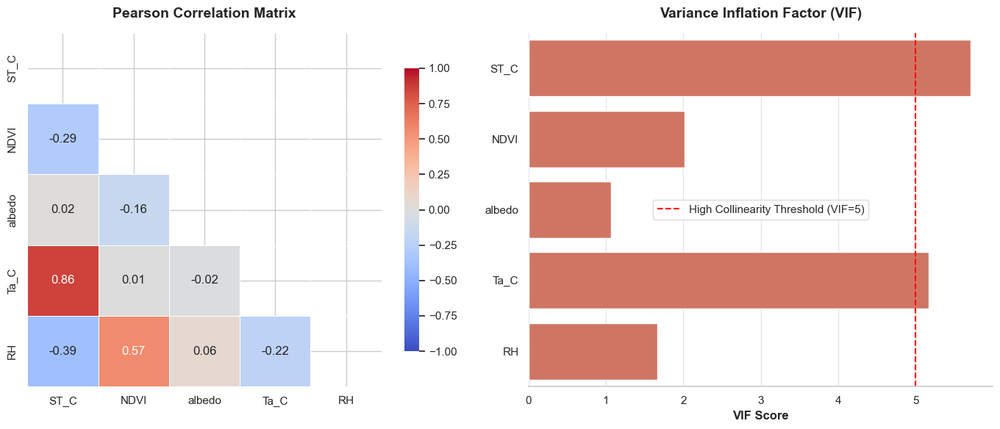

In [28]:
input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

collinearity_results = analyze_input_collinearity(
    input_df=input_df, 
    input_variables=input_variables
)

Executing forward process for 2560 generated samples...
[2026-08-27 10:37:24 INFO] starting JET table processing
[2026-08-27 10:37:24 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:24 INFO] completed extracting geometry from JET input table (0.021 seconds)
[2026-08-27 10:37:24 INFO] started extracting time from JET input table
[2026-08-27 10:37:24 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:24 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:24 INFO] completed processing FLiES-ANN in 0.20 seconds
[2026-08-27 10:37:24 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:24 INFO] * 0.0444982903496672: 2560
[2026-08-27 10:37:24 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:24 INFO] * 0.1450579477239534: 2560
[2026-08-27 10:37:24 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.00% (nan)
[2026-08-27 10:

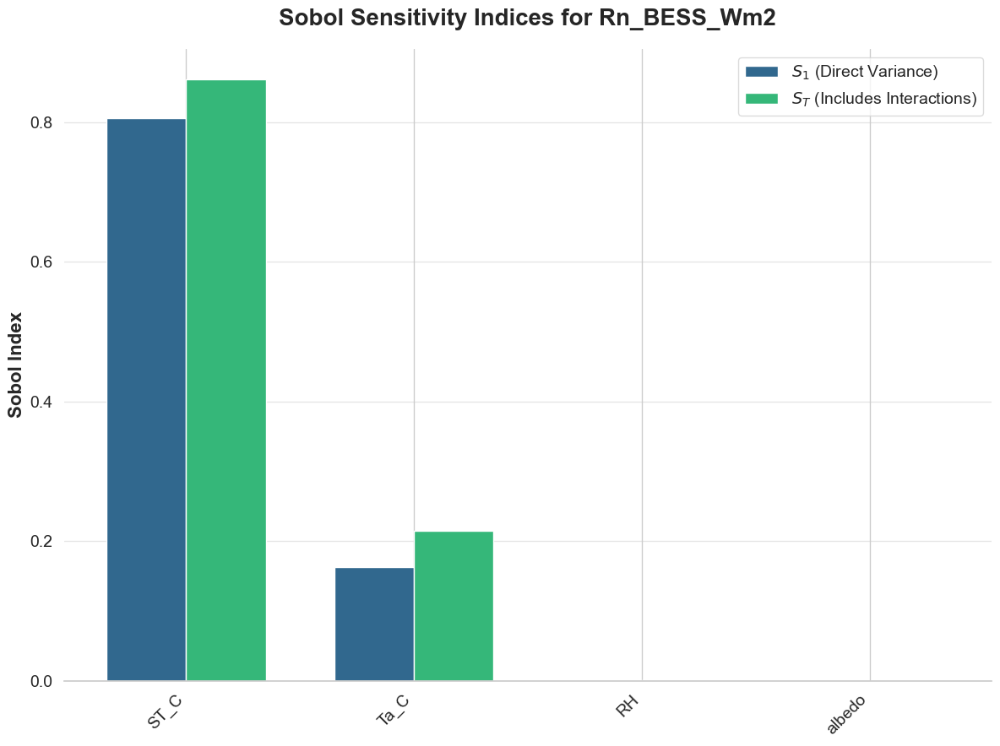

In [29]:
target_output = "Rn_BESS_Wm2"

input_variables = [
    "ST_C", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 2560 generated samples (console output hidden)...
[2026-08-27 10:37:25 INFO] starting JET table processing
[2026-08-27 10:37:25 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:26 INFO] completed extracting geometry from JET input table (0.023 seconds)
[2026-08-27 10:37:26 INFO] started extracting time from JET input table
[2026-08-27 10:37:26 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:26 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:26 INFO] completed processing FLiES-ANN in 0.19 seconds
[2026-08-27 10:37:26 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:26 INFO] * 0.0444982903496672: 2560
[2026-08-27 10:37:26 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:26 INFO] * 0.1450579477239534: 2560
[2026-08-27 10:37:26 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.0

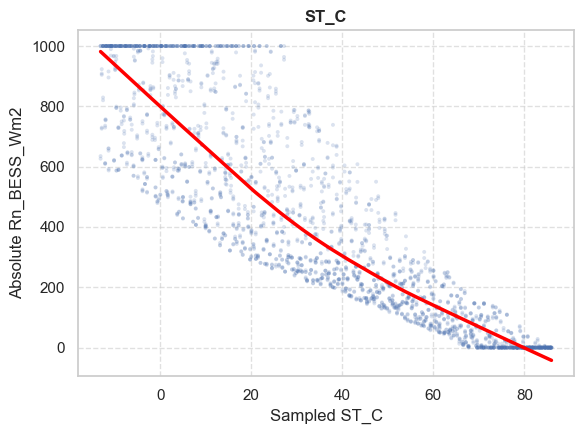

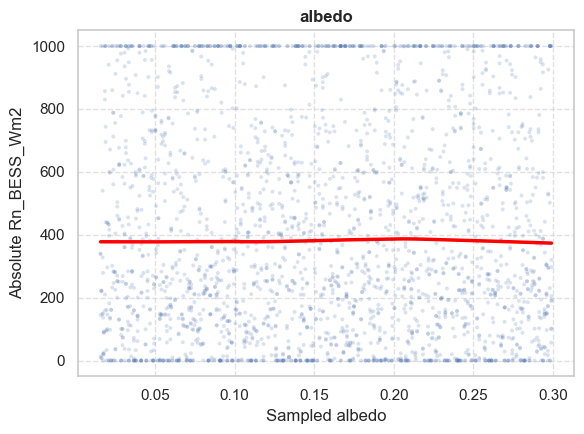

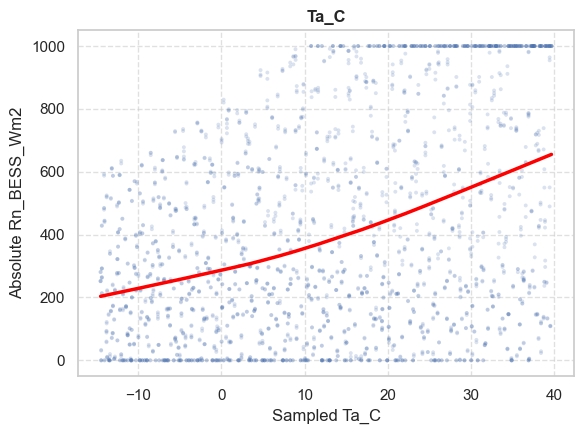

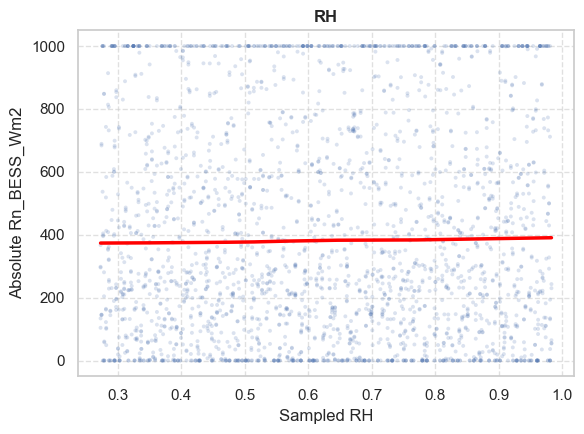

In [30]:
target_output = "Rn_BESS_Wm2"

input_variables = [
    "ST_C", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 2560 generated samples...
[2026-08-27 10:37:27 INFO] starting JET table processing
[2026-08-27 10:37:27 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:27 INFO] completed extracting geometry from JET input table (0.020 seconds)
[2026-08-27 10:37:27 INFO] started extracting time from JET input table
[2026-08-27 10:37:27 INFO] completed extracting time from JET input table (0.004 seconds)
[2026-08-27 10:37:27 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:27 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:27 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:27 INFO] * 0.0444982903496672: 2560
[2026-08-27 10:37:27 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:27 INFO] * 0.1450579477239534: 2560
[2026-08-27 10:37:27 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.00% (nan)
[2026-08-27 10:

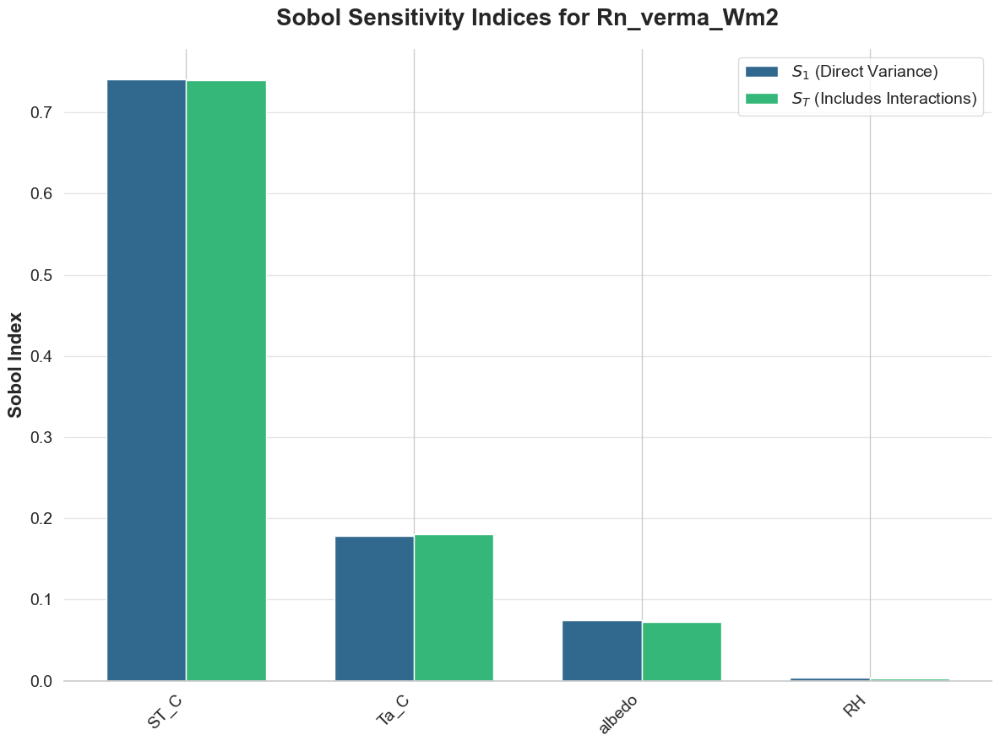

In [31]:
target_output = "Rn_verma_Wm2"

input_variables = [
    "ST_C", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 2560 generated samples (console output hidden)...
[2026-08-27 10:37:29 INFO] starting JET table processing
[2026-08-27 10:37:29 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:29 INFO] completed extracting geometry from JET input table (0.022 seconds)
[2026-08-27 10:37:29 INFO] started extracting time from JET input table
[2026-08-27 10:37:29 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:29 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:29 INFO] completed processing FLiES-ANN in 0.19 seconds
[2026-08-27 10:37:29 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:29 INFO] * 0.0444982903496672: 2560
[2026-08-27 10:37:29 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:29 INFO] * 0.1450579477239534: 2560
[2026-08-27 10:37:29 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.0

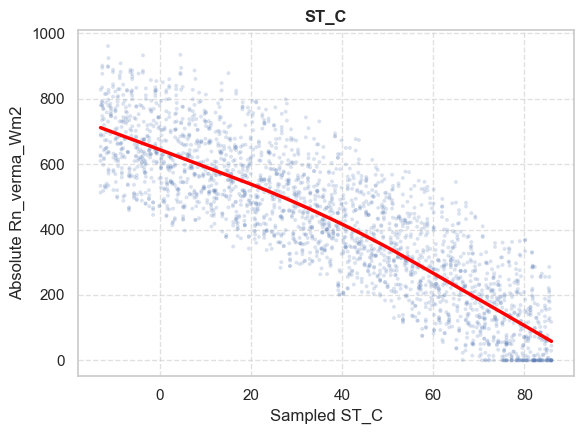

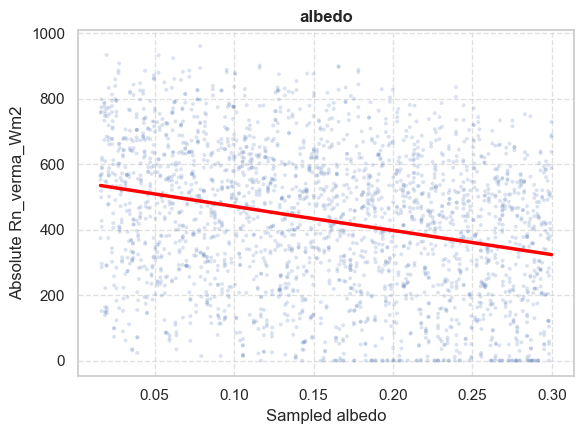

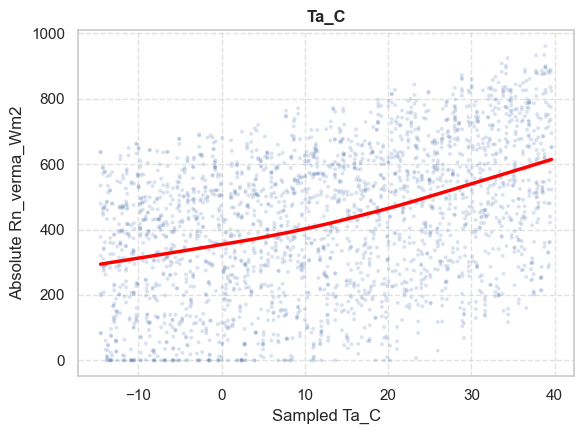

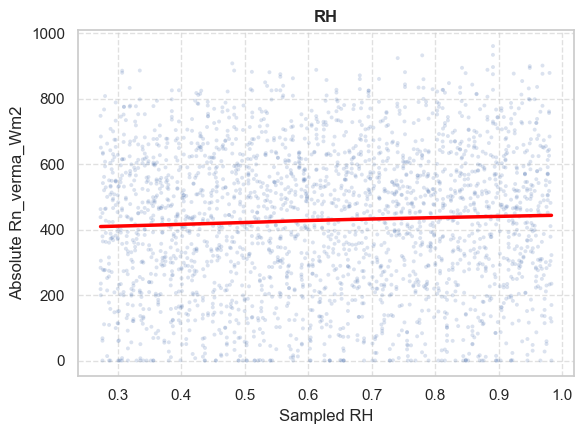

In [32]:
target_output = "Rn_verma_Wm2"

input_variables = [
    "ST_C", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:31 INFO] starting JET table processing
[2026-08-27 10:37:31 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:31 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:31 INFO] started extracting time from JET input table
[2026-08-27 10:37:31 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:31 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:31 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:31 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:31 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:31 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:31 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:31 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.00% (nan)
[2026-08-27 10:

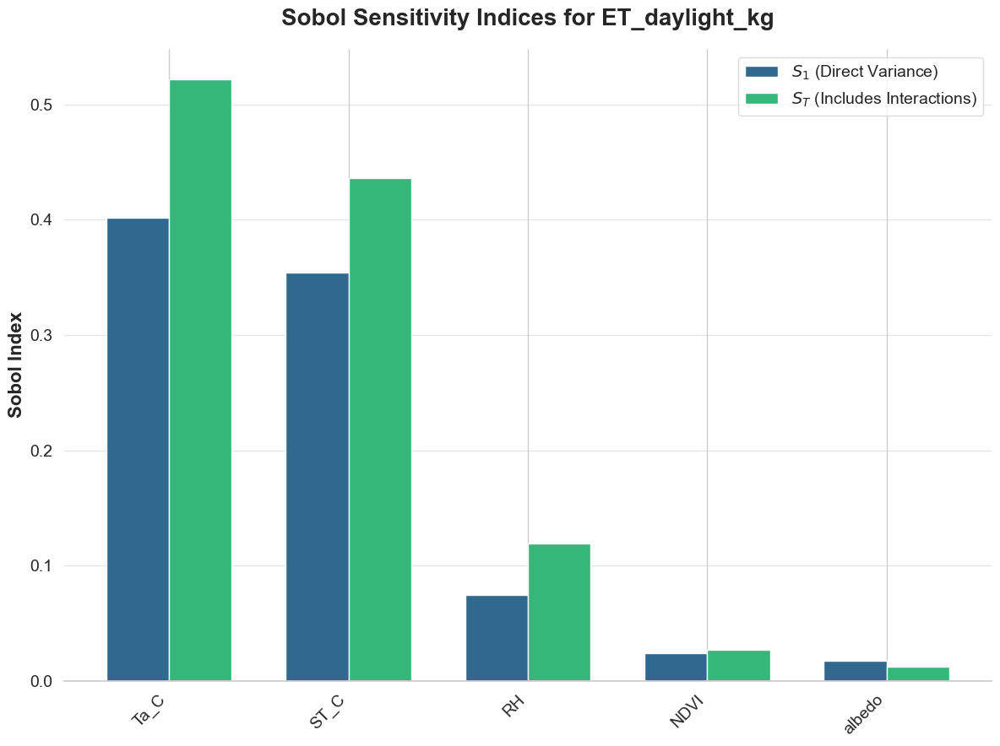

In [33]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:32 INFO] starting JET table processing
[2026-08-27 10:37:32 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:32 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:37:32 INFO] started extracting time from JET input table
[2026-08-27 10:37:32 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:32 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:32 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:37:32 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:32 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:32 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:32 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:32 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.0

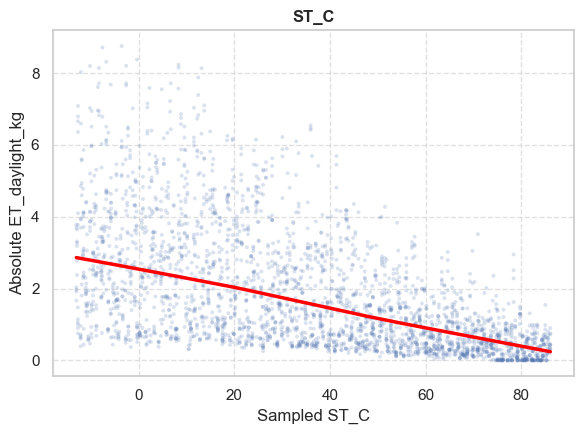

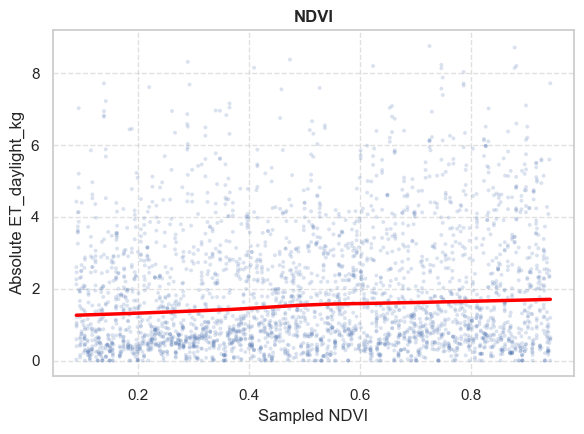

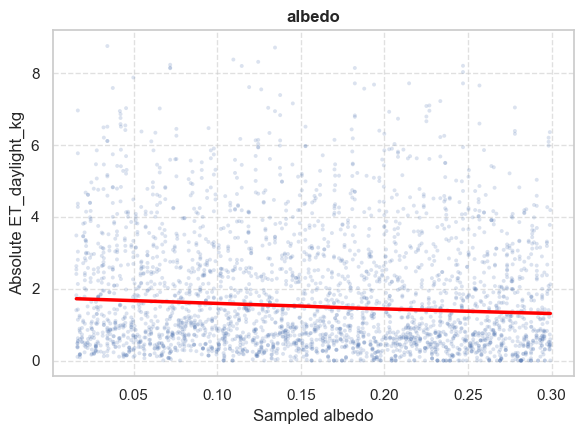

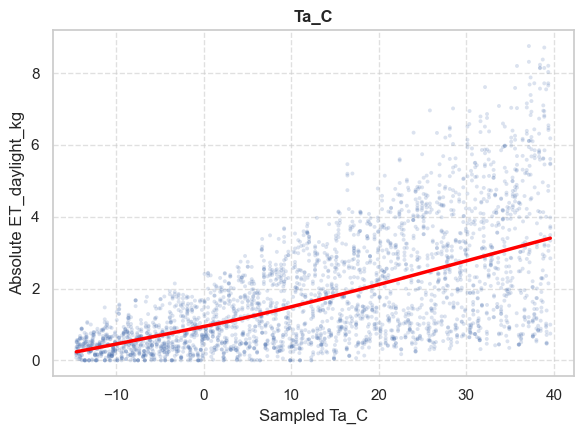

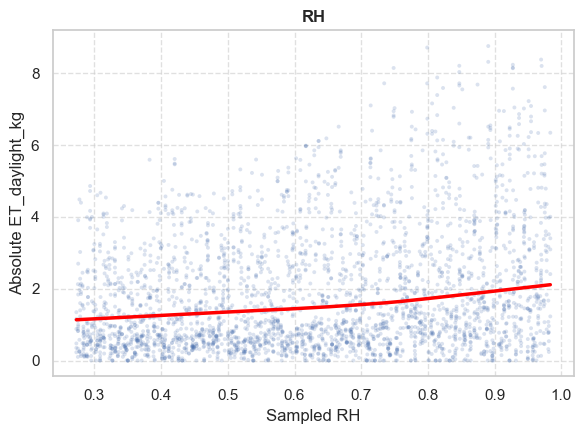

In [34]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:34 INFO] starting JET table processing
[2026-08-27 10:37:34 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:34 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:34 INFO] started extracting time from JET input table
[2026-08-27 10:37:34 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:34 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:35 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:35 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:35 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:35 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:35 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:35 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.0

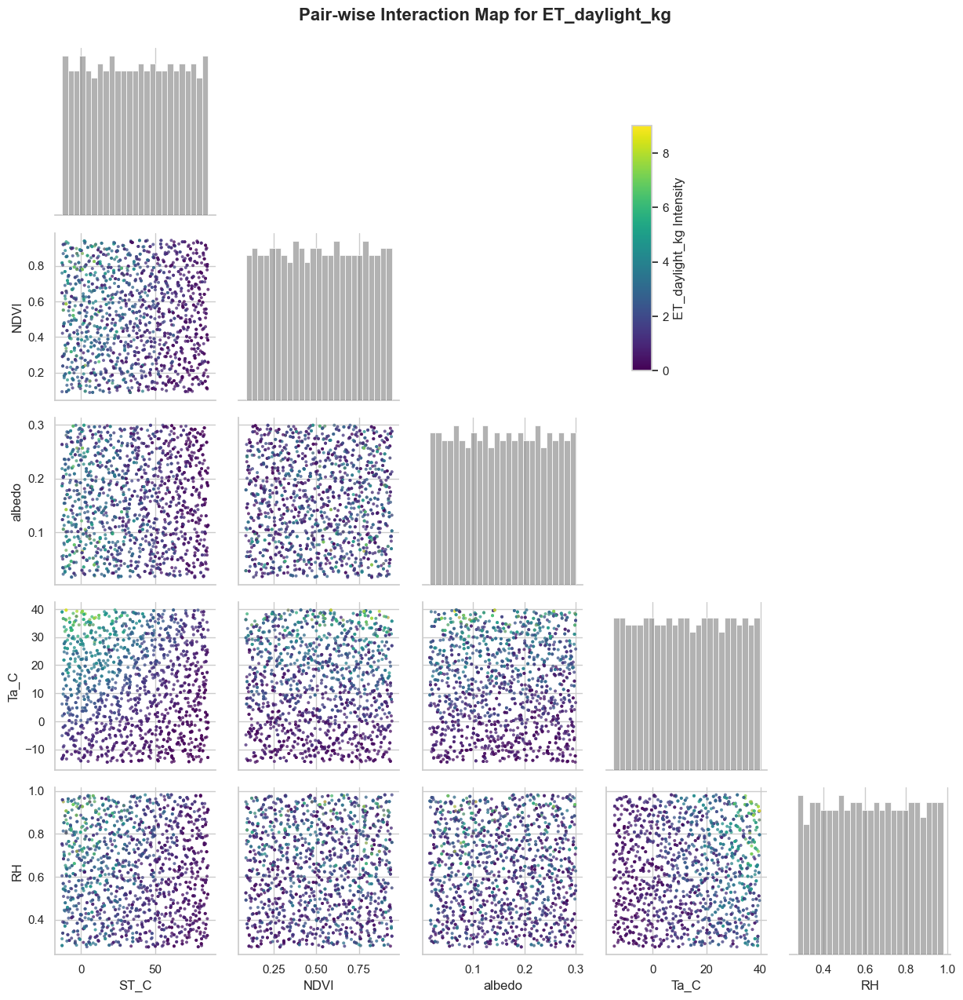

In [35]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_pairwise_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:37 INFO] starting JET table processing
[2026-08-27 10:37:37 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:37 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:37:37 INFO] started extracting time from JET input table
[2026-08-27 10:37:37 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:37 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:37 INFO] completed processing FLiES-ANN in 0.23 seconds
[2026-08-27 10:37:37 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:37 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:37 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:37 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:37 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.00% (nan)
[2026-08-27 10:

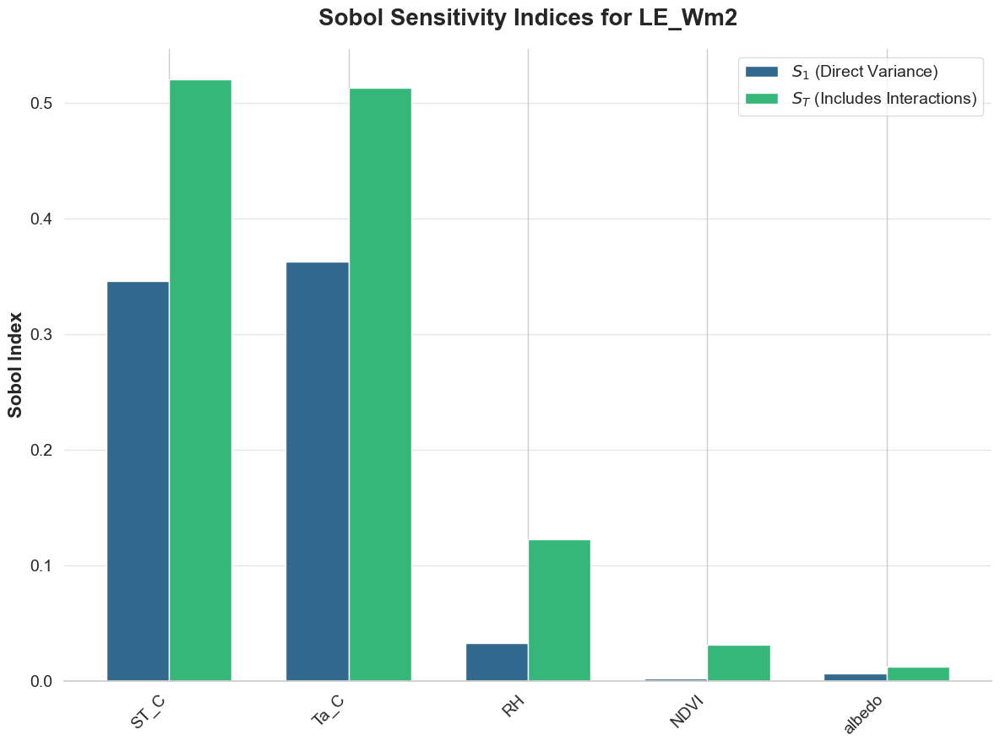

In [36]:
target_output = "LE_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:38 INFO] starting JET table processing
[2026-08-27 10:37:38 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:38 INFO] completed extracting geometry from JET input table (0.027 seconds)
[2026-08-27 10:37:38 INFO] started extracting time from JET input table
[2026-08-27 10:37:38 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:38 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:39 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:39 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:39 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:39 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:39 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:39 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.048 nan: 0.00% (nan)
[2026-08-27 10:

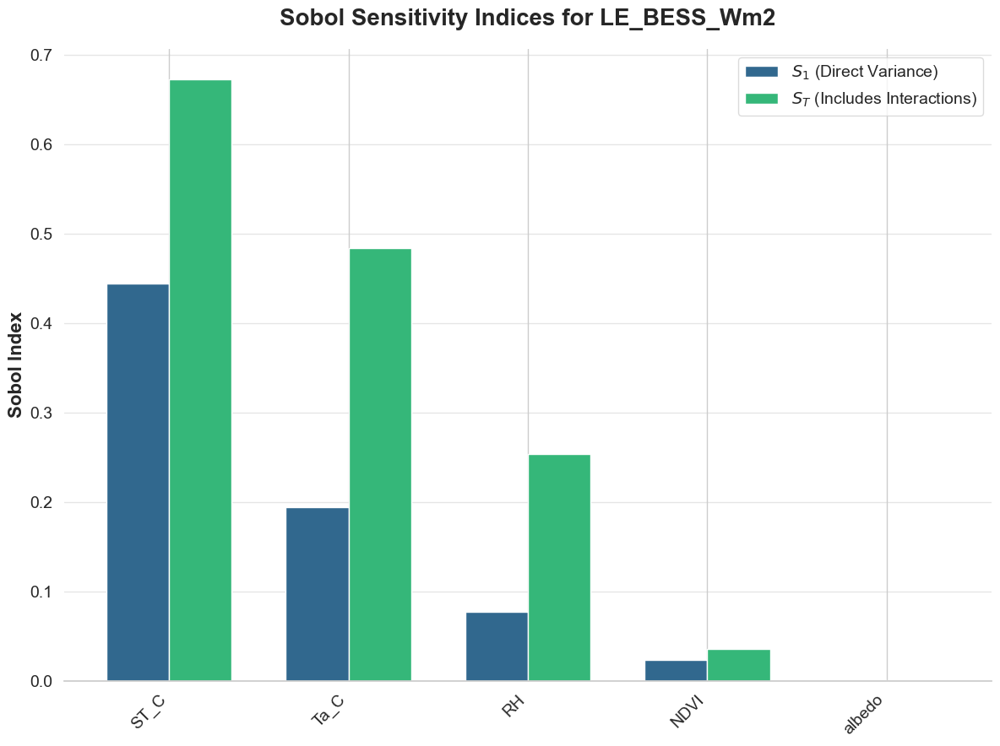

In [37]:
target_output = "LE_BESS_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:40 INFO] starting JET table processing
[2026-08-27 10:37:40 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:40 INFO] completed extracting geometry from JET input table (0.027 seconds)
[2026-08-27 10:37:40 INFO] started extracting time from JET input table
[2026-08-27 10:37:40 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:40 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:40 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:40 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:40 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:40 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:40 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:40 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.0

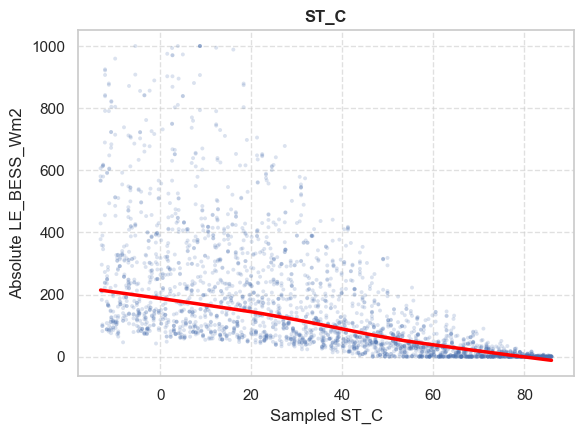

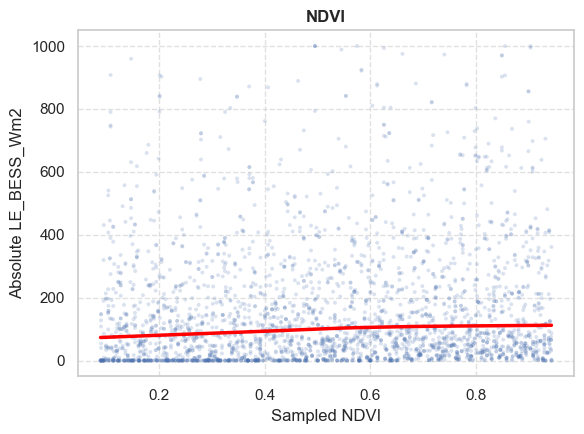

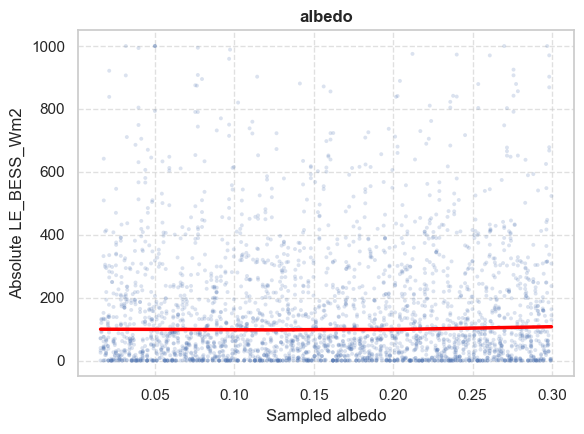

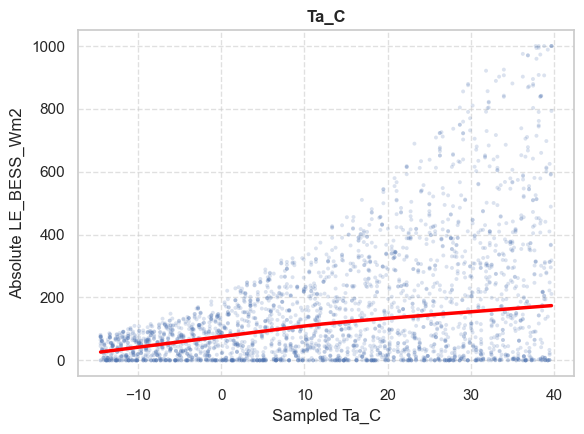

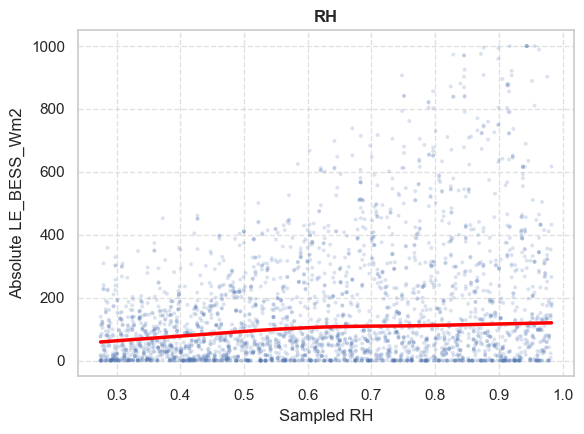

In [38]:
target_output = "LE_BESS_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:42 INFO] starting JET table processing
[2026-08-27 10:37:42 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:42 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:42 INFO] started extracting time from JET input table
[2026-08-27 10:37:42 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:42 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:42 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:42 INFO] variable PAR_albedo (float64) with [0.04449829] unique values
[2026-08-27 10:37:42 INFO] * 0.0444982903496672: 3072
[2026-08-27 10:37:42 INFO] variable NIR_albedo (float64) with [0.14505795] unique values
[2026-08-27 10:37:42 INFO] * 0.1450579477239534: 3072
[2026-08-27 10:37:42 INFO] variable PAR_direct_Wm2 min: 300.793 mean: 300.874 max: 301.049 nan: 0.00% (nan)
[2026-08-27 10:

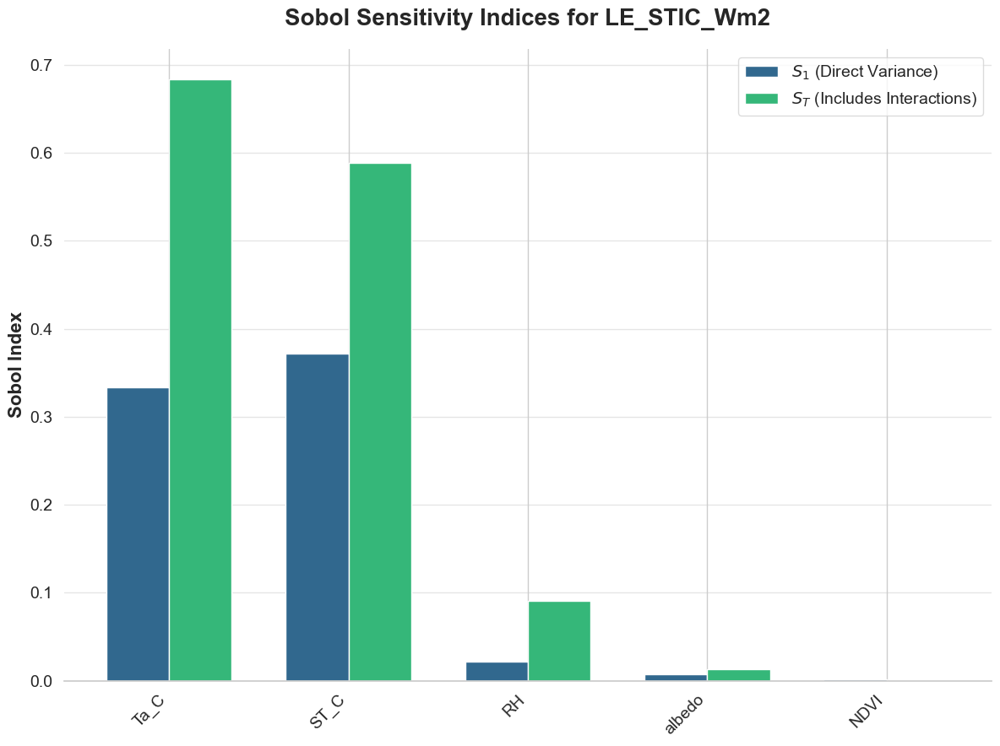

In [39]:
target_output = "LE_STIC_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

# ECOv003 JET Accuracy Analysis with ECOv002 Cal-Val

This notebook performs a sensitivity analysis of the JET ensemble using ECOSTRESS Collection 2 Cal-Val data. 

## Import Required Libraries and Functions

This cell imports all necessary libraries and functions for data processing, model execution, statistical analysis, and plotting. It includes custom modules for the JET ensemble, sensitivity analysis, and net radiation calculations, as well as standard scientific Python libraries.

In [40]:
import sys
import os
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname("__file__"), '..')))
from typing import Callable
from os import makedirs
from os.path import join
import numpy as np
import pandas as pd
from verma_net_radiation import verma_net_radiation_table
from JET3 import process_JET_table, load_ECOv002_calval_JET_inputs
import matplotlib.pyplot as plt
from scipy.stats import mstats
import seaborn as sns
from matplotlib.ticker import FuncFormatter

## Configuration Options

Set configuration options for the notebook, including whether to save plots to files.

In [41]:
# Configuration: Set to True to save plots to files, False to only display them
SAVE_PLOTS = False

In [42]:
input_variables = [
    "ST_C",
    "NDVI",
    "albedo",
    "Ta_C",
    "RH",
    "AOT",
    "COT",
    "vapor_gccm",
    "ozone_cm",
    "elevation_m",
    "canopy_height_meters"
]

output_variables = [
    "Rn_Wm2",
    "ET_daylight_kg",
    "GPP_inst_g_m2_s"
]

# Per-variable physical bounds to keep perturbations realistic
input_min = {
    "ST_C": 0.0,
    "NDVI": 0.05,
    "albedo": 0.0,
    "Ta_C": 0.0,
    "RH": 0.0,
    "AOT": 0.0,
    "COT": 0.0,
    "vapor_gccm": 0.0,
    "ozone_cm": 0.0,
    "elevation_m": 0.0,
    "canopy_height_meters": 0.0,
}

input_max = {
    "ST_C": 50.0,
    "NDVI": 1,
    "albedo": 1,
}

## Define Processing Function for Model Table

This cell defines the forward process for analysis as the BESS-JPL model.

In [43]:
forward_process = process_JET_table
model_name = "JET"

## Load and Filter Input Data

This cell loads the ECOSTRESS Cal-Val input data using a custom loader function and filters out surface temperatures greater than 50 Celsius and NDVI values less than 0.05. The resulting DataFrame is displayed for inspection.

In [44]:
input_df = load_ECOv002_calval_JET_inputs()

# Apply lower and upper bounds from configuration dictionaries
mask = pd.Series(True, index=input_df.index)
for var, min_val in input_min.items():
    if var in input_df.columns:
        mask &= input_df[var] >= min_val
for var, max_val in input_max.items():
    if var in input_df.columns:
        mask &= input_df[var] <= max_val

input_df = input_df[mask]
input_df = input_df.dropna()
input_df

,Unnamed: 0,ID,vegetation,climate,STICinst,BESSinst,MOD16inst,PTJPLSMinst,ETinst,ETinstUncertainty,...,CL,Tmin_open,Tmin_closed,VPD_open,VPD_closed,Tmin_C,Topt_C,fAPARmax,field_capacity,wilting_point
15,15,US-xAB,ENF,Csb,141.635670,168.24043,402.81810,159.71700,139.016083,107.183200,...,0.0032,8.31,-8.0,650.0,3000.0,11.940895,6.69,0.6040,0.33,0.16
17,17,US-xAB,ENF,Csb,1.881266,163.94730,301.40400,179.13661,131.273636,106.525215,...,0.0032,8.31,-8.0,650.0,3000.0,11.940895,6.69,0.6040,0.33,0.16
18,18,US-xAB,ENF,Csb,3.135606,246.87700,614.51480,405.50497,366.056641,222.890230,...,0.0032,8.31,-8.0,650.0,3000.0,11.940895,6.69,0.6040,0.33,0.16
19,19,US-xAB,ENF,Csb,311.482820,290.73126,672.27510,478.82382,439.821228,153.787670,...,0.0032,8.31,-8.0,650.0,3000.0,11.940895,6.69,0.6040,0.33,0.16
20,20,US-xAB,ENF,Csb,51.920338,95.28810,116.67136,73.20884,232.693512,24.038680,...,0.0032,8.31,-8.0,650.0,3000.0,11.940895,6.69,0.6040,0.33,0.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
992,992,US-xML,DBF,Dfb,417.831120,706.93066,523.92740,310.69684,356.174072,148.624050,...,0.0065,11.39,-8.0,650.0,3500.0,27.538052,2.66,0.5404,0.34,0.14
994,994,US-xML,DBF,Dfb,161.558200,306.15277,420.44678,206.48576,237.659103,98.727560,...,0.0065,11.39,-8.0,650.0,3500.0,27.538052,2.66,0.5404,0.34,0.14
1001,1001,US-UiB,CRO,Dfa,93.876100,251.38747,238.71077,198.90399,106.316444,67.694800,...,0.0070,12.02,-8.0,650.0,4500.0,9.637029,2.58,0.4060,0.32,0.14
1020,1020,US-ARM,CRO,Cfa,80.255005,0.00000,180.10085,211.28325,164.581390,84.672410,...,0.0070,12.02,-8.0,650.0,4500.0,9.637029,8.48,0.4017,0.29,0.12


## Process Input Data Through Model

This cell applies the processing function to the filtered input data, running it through the model, and displays the resulting DataFrame.

In [45]:
processed = forward_process(input_df)
processed

[2026-08-27 10:37:43 INFO] starting JET table processing
[2026-08-27 10:37:43 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:43 INFO] completed extracting geometry from JET input table (0.003 seconds)
[2026-08-27 10:37:43 INFO] started extracting time from JET input table
[2026-08-27 10:37:43 INFO] completed extracting time from JET input table (0.001 seconds)
[2026-08-27 10:37:43 INFO] running Forest Light Environmental Simulator
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
[2026-08-27 10:37:43 INFO] completed processing FLiES-ANN in 0.16 seconds
[2026-08-27 10:37:43 INFO] variable PAR_albedo min: 0.007 mean: 0.055 max: 0.193 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable NIR_albedo min: 0.066 mean: 0.162 max: 0.530 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable PAR_direct_Wm2 min: 7.148 mean: 269.735 max: 442.463 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable SWin_FLiES_ANN min: 163.676 mean: 716.916 max: 1095.605 nan: 0.00% (nan)
[2026-08-27 10:3

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')


[2026-08-27 10:37:43 INFO] variable UV min: 12.171 mean: 42.068 max: 67.767 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable SZA min: 17.642 mean: 46.017 max: 72.208 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable LAI min: 0.158 mean: 0.984 max: 4.031 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable CI min: 0.188 mean: 0.266 max: 0.298 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable albedo_visible min: 0.007 mean: 0.055 max: 0.193 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable albedo_NIR min: 0.066 mean: 0.162 max: 0.530 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable kb min: 0.525 mean: 0.799 max: 1.636 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable kk_Pb min: 0.483 mean: 0.735 max: 1.505 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable kk_Nb min: 0.219 mean: 0.334 max: 0.685 nan: 0.00% (nan)
[2026-08-27 10:37:43 INFO] variable kk_Nd (float64) with [0.1464155] unique values
[2026-08-27 10:37:43 INFO] * 0.14641550464346323: 1
[2026-08-27 10:37:43 

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Use

,Unnamed: 0,ID,vegetation,climate,STICinst,BESSinst,MOD16inst,PTJPLSMinst,ETinst,ETinstUncertainty,...,G_PMJPL_Wm2,G_Wm2,LE_instantaneous_Wm2,LE_Wm2,H_Wm2,ET_daylight_kg,ET_uncertainty,GPP_inst_g_m2_s,ET_canopy_inst_kg_m2_s,WUE
15,15,US-xAB,ENF,Csb,141.635670,168.24043,402.81810,159.71700,139.016083,107.183200,...,24.219544,24.219544,203.764376,203.764376,248.713696,2.900053,0.510811,0.000151,0.000058,2.606544
17,17,US-xAB,ENF,Csb,1.881266,163.94730,301.40400,179.13661,131.273636,106.525215,...,13.772918,13.772918,163.144742,163.144742,194.438550,2.854526,1.085331,0.000108,0.000034,3.174119
18,18,US-xAB,ENF,Csb,3.135606,246.87700,614.51480,405.50497,366.056641,222.890230,...,33.327171,33.327171,342.565013,342.565013,348.501129,4.442026,0.971980,0.000291,0.000122,2.390822
19,19,US-xAB,ENF,Csb,311.482820,290.73126,672.27510,478.82382,439.821228,153.787670,...,42.878466,42.878466,403.011097,403.011097,366.186555,4.947329,1.401781,0.000294,0.000211,1.388074
20,20,US-xAB,ENF,Csb,51.920338,95.28810,116.67136,73.20884,232.693512,24.038680,...,2.903705,2.903705,112.556235,112.556235,52.720986,2.991218,0.730132,0.000095,0.000015,6.238326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
992,992,US-xML,DBF,Dfb,417.831120,706.93066,523.92740,310.69684,356.174072,148.624050,...,29.623891,29.623891,397.732265,397.732265,216.894638,3.642505,1.045928,0.000233,0.000137,1.697664
994,994,US-xML,DBF,Dfb,161.558200,306.15277,420.44678,206.48576,237.659103,98.727560,...,21.577865,21.577865,285.469147,285.469147,216.864039,2.883329,1.141584,0.000138,0.000101,1.357232
1001,1001,US-UiB,CRO,Dfa,93.876100,251.38747,238.71077,198.90399,106.316444,67.694800,...,77.061858,77.061858,105.892160,105.892160,409.322436,1.323772,1.130343,0.000053,0.000016,3.203371
1020,1020,US-ARM,CRO,Cfa,80.255005,0.00000,180.10085,211.28325,164.581390,84.672410,...,69.968594,69.968594,119.836612,119.836612,285.958690,1.413853,1.294936,0.000048,0.000031,1.555148


## Accuracy Comparison of In-Situ Observations to Model Estimates

Examining the accuracy of model estimates compared to ground data.

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

def generate_accuracy_plot(df, x_variable, y_variable, output_variable, model_name, color_col='ST_C', cbar_label="ECOSTRESS Surface Temperature (°C)", save_plots=False):
    """
    Generates and optionally saves a scatter plot comparing in-situ data to model output,
    including a 1:1 line, OLS regression fit, R-squared, and RMSE annotations.
    """
    # FIX 3: Replaced hardcoded 'ST_C' with color_col parameter
    valid_data = df[[x_variable, y_variable, color_col]].dropna()
    
    # Create the scatter plot
    # FIX: Removed `color=None` to prevent conflicts with `c` in newer matplotlib versions
    sc = plt.scatter(
        x=valid_data[x_variable],
        y=valid_data[y_variable],
        c=valid_data[color_col],
        cmap="jet",
        s=5
    )

    # Get the actual data bounds to ensure lines span the whole plot
    x_min, x_max = valid_data[x_variable].min(), valid_data[x_variable].max()
    y_min, y_max = valid_data[y_variable].min(), valid_data[y_variable].max()
    
    # Calculate a square bounding box for the 1:1 line
    plot_min = min(x_min, y_min)
    plot_max = max(x_max, y_max)

    # FIX 2: Draw 1-to-1 line across the entire data range, not just 5th-95th percentile
    plt.plot([plot_min, plot_max], [plot_min, plot_max], color='black', linestyle='-', linewidth=1, label='1:1 Line')

    # Add OLS regression line
    coefs = np.polyfit(valid_data[x_variable], valid_data[y_variable], 1)
    ols_x = np.array([x_min, x_max])
    ols_y = coefs[0] * ols_x + coefs[1]
    plt.plot(ols_x, ols_y, color='black', linestyle='--', linewidth=1, label='OLS Fit')

    # FIX 1: Calculate metrics properly
    # R-squared of the linear fit (how linear the relationship is)
    y_true_for_r2 = valid_data[y_variable]
    y_pred_from_ols = coefs[0] * valid_data[x_variable] + coefs[1]
    r2 = r2_score(y_true_for_r2, y_pred_from_ols)
    
    # RMSE between the model and in-situ data (how accurate the model actually is)
    rmse = np.sqrt(mean_squared_error(valid_data[x_variable], valid_data[y_variable]))

    # Annotate R-squared and RMSE on plot in lower right corner
    plt.annotate(f"$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}",
                xy=(0.95, 0.05), xycoords='axes fraction',  # Changed x-coordinate to 0.95
                ha='right', va='bottom',                    # Changed horizontal alignment to 'right'
                fontsize=10,
                bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.7))

    # Format the plot
    plt.grid(True, zorder=0) 
    plt.xlabel(f"In-Situ {output_variable}")
    plt.ylabel(f"{model_name} {output_variable}")
    plt.title(f"Accuracy Comparison\nof In-Situ {output_variable}\nto {model_name} {output_variable}")
    
    # FIX 3: Use dynamic colorbar label
    plt.colorbar(sc, label=cbar_label)
    
    # Place the line legend in the top-left
    plt.legend(loc='upper left')
    
    # Save if requested
    if save_plots:
        plt.savefig(f"Accuracy Comparison of In-Situ {output_variable} to {model_name} {output_variable}.jpeg", format='jpeg', bbox_inches='tight')
        plt.savefig(f"Accuracy Comparison of In-Situ {output_variable} to {model_name} {output_variable}.svg", format='svg', bbox_inches='tight')
    
    plt.show()

analyzing JET accuracy for ET_daylight_kg compared to insitu_ET_daylight_kg


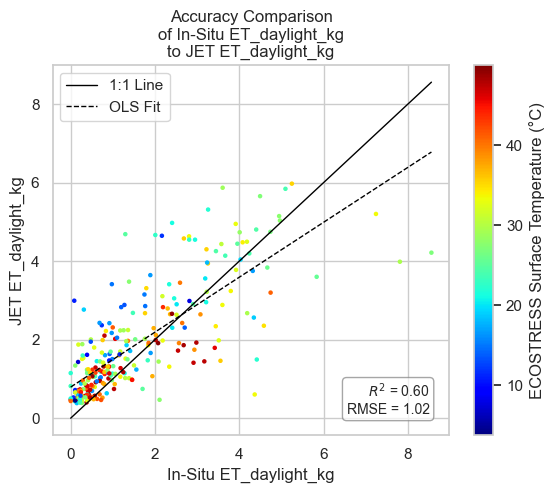

analyzing JET accuracy for G_Wm2 compared to insitu_G_Wm2


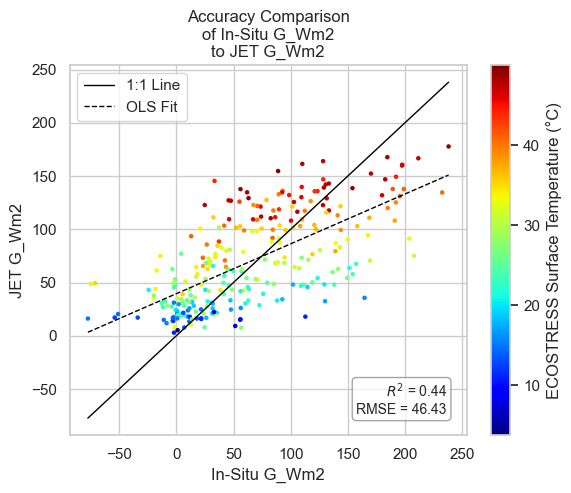

analyzing JET accuracy for H_Wm2 compared to insitu_H_Wm2


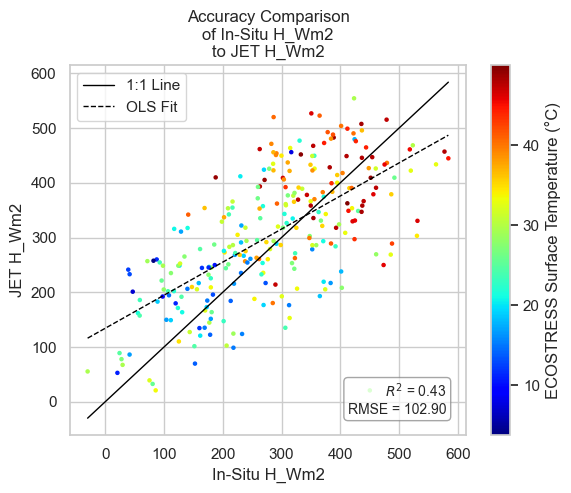

analyzing JET accuracy for LE_Wm2 compared to insitu_LE_Wm2


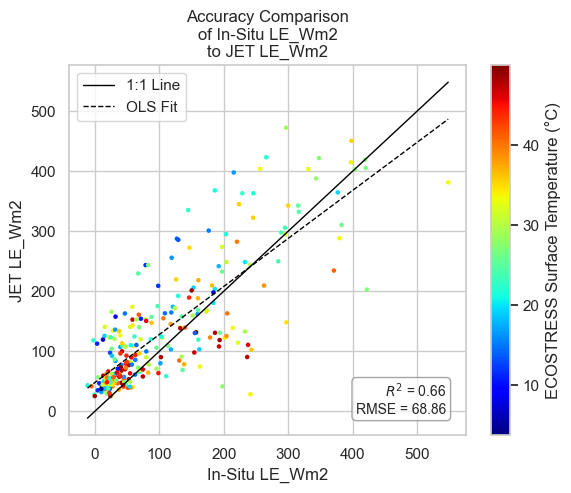

analyzing JET accuracy for LE_daylight_Wm2 compared to insitu_LE_daylight_Wm2
Error processing LE_daylight_Wm2: "['LE_daylight_Wm2'] not in index"
analyzing JET accuracy for RH compared to insitu_RH


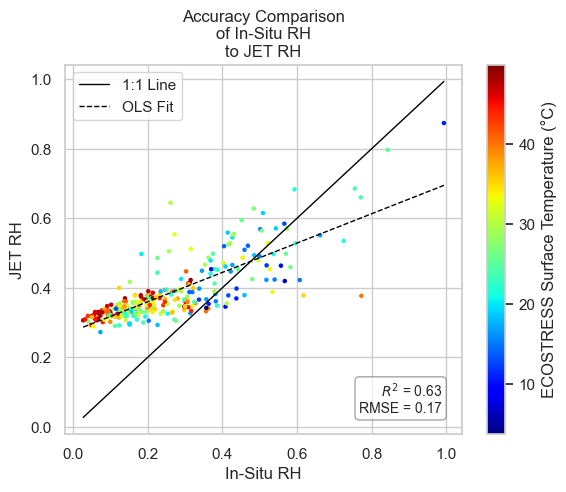

analyzing JET accuracy for Rn_Wm2 compared to insitu_Rn_Wm2


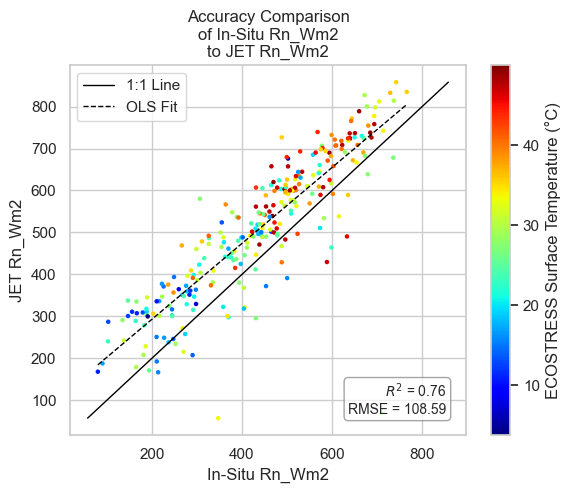

analyzing JET accuracy for Rn_daylight_Wm2 compared to insitu_Rn_daylight_Wm2
Error processing Rn_daylight_Wm2: "['Rn_daylight_Wm2'] not in index"
analyzing JET accuracy for SWin_Wm2 compared to insitu_SWin_Wm2


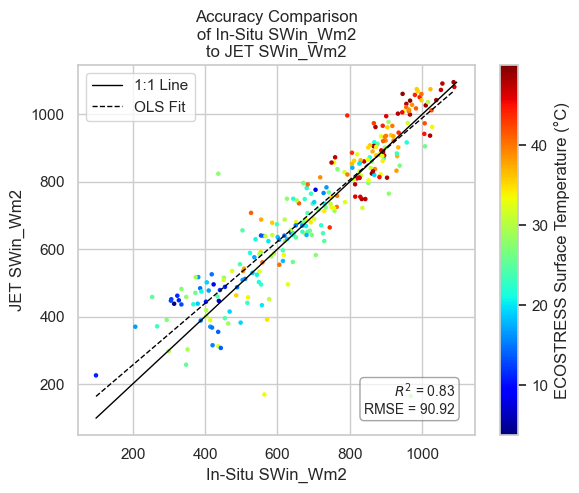

analyzing JET accuracy for Ta_C compared to insitu_Ta_C


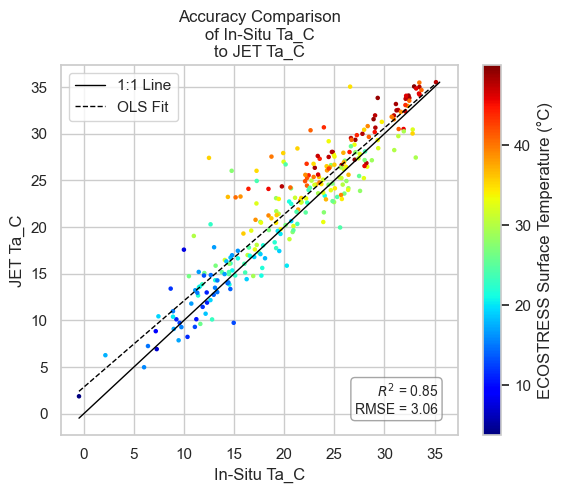

In [47]:
insitu_columns = sorted([column for column in processed.columns if "insitu" in column])

for insitu_variable in insitu_columns:
    output_variable = insitu_variable.replace("insitu_", "")
    print(f"analyzing {model_name} accuracy for {output_variable} compared to {insitu_variable}")
    
    try:
        generate_accuracy_plot(
            df=processed,
            x_variable=insitu_variable,
            y_variable=output_variable,
            output_variable=output_variable,
            model_name=model_name,
            save_plots=SAVE_PLOTS
        )
    except Exception as e:
        print(f"Error processing {output_variable}: {e}")
        continue

# Accuracy Comparison for Net Radiation between BESS and Verma

analyzing JET accuracy for Rn_BESS_Wm2 compared to insitu_Rn_Wm2


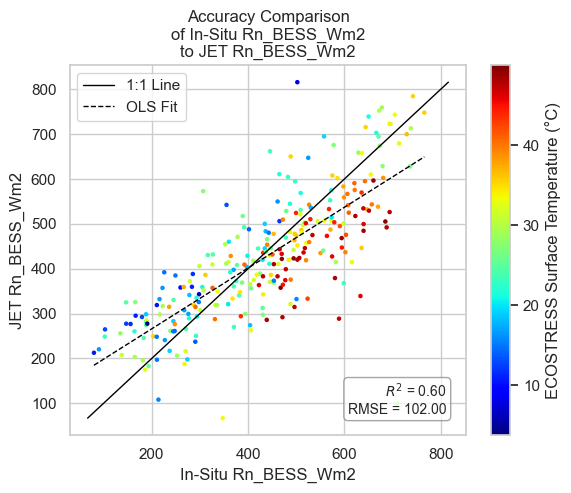

analyzing JET accuracy for Rn_verma_Wm2 compared to insitu_Rn_Wm2


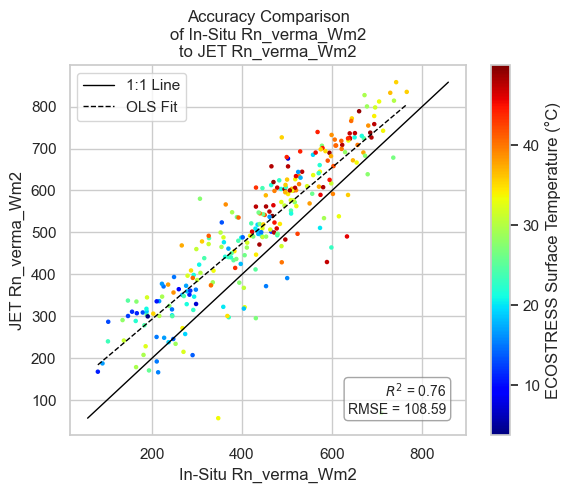

In [48]:
insitu_variable = "insitu_Rn_Wm2"

for output_variable in ["Rn_BESS_Wm2", "Rn_verma_Wm2"]:
    print(f"analyzing {model_name} accuracy for {output_variable} compared to {insitu_variable}")
    
    try:
        generate_accuracy_plot(
            df=processed,
            x_variable=insitu_variable,
            y_variable=output_variable,
            output_variable=output_variable,
            model_name=model_name,
            save_plots=SAVE_PLOTS
        )
    except Exception as e:
        print(f"Error processing {output_variable}: {e}")
        continue

analyzing JET accuracy for LE_BESS_Wm2 compared to insitu_LE_Wm2


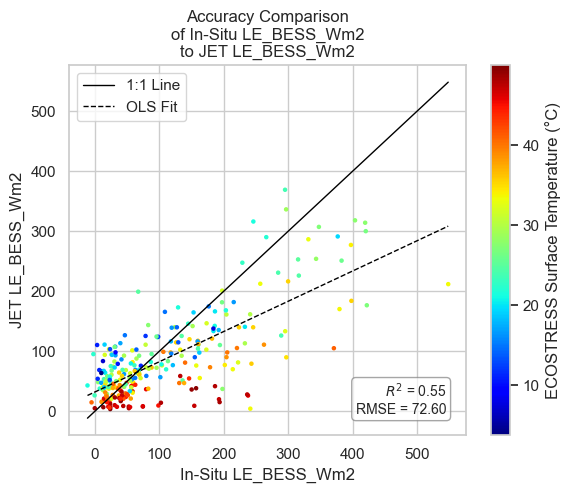

analyzing JET accuracy for LE_STIC_Wm2 compared to insitu_LE_Wm2


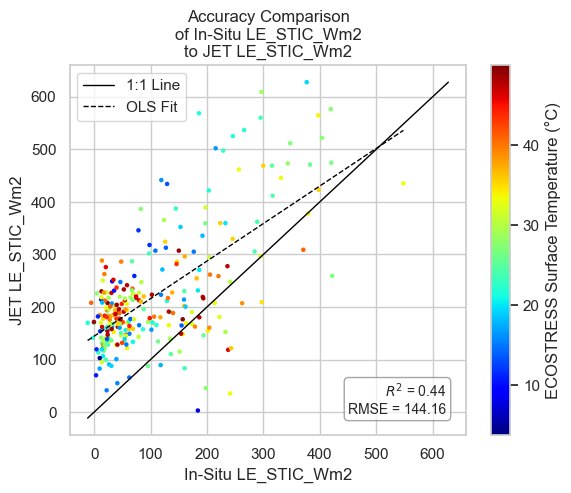

analyzing JET accuracy for LE_PTJPLSM_Wm2 compared to insitu_LE_Wm2


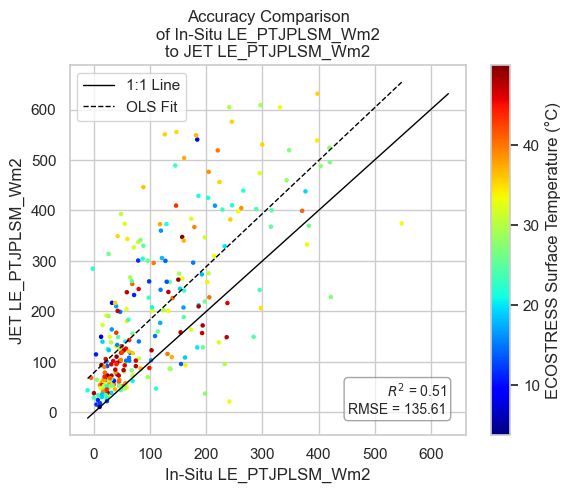

analyzing JET accuracy for LE_PMJPL_Wm2 compared to insitu_LE_Wm2


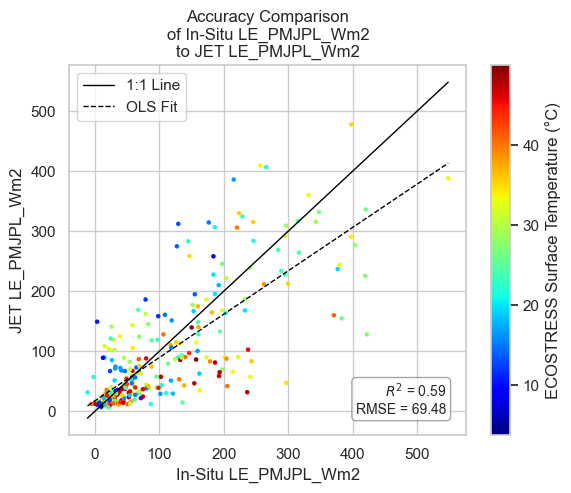

analyzing JET accuracy for LE_Wm2 compared to insitu_LE_Wm2


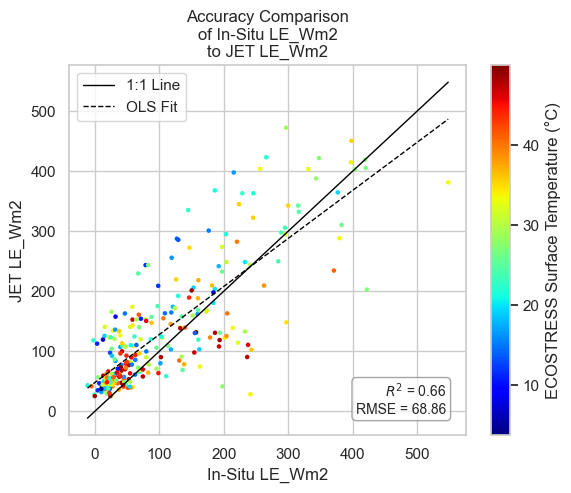

In [49]:
insitu_variable = "insitu_LE_Wm2"

output_variables = [
    "LE_BESS_Wm2",
    "LE_STIC_Wm2",
    "LE_PTJPLSM_Wm2",
    "LE_PMJPL_Wm2",
    "LE_Wm2"
]

for output_variable in output_variables:
    print(f"analyzing {model_name} accuracy for {output_variable} compared to {insitu_variable}")
    
    try:
        generate_accuracy_plot(
            df=processed,
            x_variable=insitu_variable,
            y_variable=output_variable,
            output_variable=output_variable,
            model_name=model_name,
            save_plots=SAVE_PLOTS
        )
    except Exception as e:
        print(f"Error processing {output_variable}: {e}")
        continue

In [50]:
import os
import contextlib
import math
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from SALib.sample import sobol as sobol_sample
from SALib.analyze import sobol

def SOBOL_sensitivity_analysis(
    input_df, 
    input_variables, 
    target_output, 
    forward_process, 
    custom_bounds=None, 
    groups=None,
    N=1024, 
    theme_name="whitegrid", 
    palette_name="viridis"
):
    """
    Generates Sobol samples from bounds, runs the forward model via a callback, 
    and computes/plots first-order (S1) and total-order (ST) Sobol indices.
    
    Parameters:
    - custom_bounds: Optional dictionary mapping variable names to [min, max].
    - groups: Optional list of group names matching the length of input_variables.
              Used to force rank-correlated dependent sampling for collinear inputs.
    """
    
    # 1. Clean the input table
    input_df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    
    # 2. Define problem bounds
    bounds = []
    for var in input_variables:
        if custom_bounds and var in custom_bounds:
            bounds.append(custom_bounds[var])
        else:
            bounds.append([input_df_clean[var].min(), input_df_clean[var].max()])
            
    problem = {
        'num_vars': len(input_variables),
        'names': input_variables,
        'bounds': bounds
    }
    
    # Inject groups if provided
    if groups is not None:
        if len(groups) != len(input_variables):
            raise ValueError("The 'groups' list must be exactly the same length as 'input_variables'.")
        problem['groups'] = groups
    
    # 3. Generate samples using SALib
    param_values = sobol_sample.sample(problem, N, calc_second_order=True)
    
    # 4. Create baseline dataset using the median of numeric columns 
    base_row = input_df_clean.iloc[[0]].copy()
    numeric_medians = input_df_clean.select_dtypes(include=[np.number]).median()
    
    for col in numeric_medians.index:
        base_row[col] = numeric_medians[col]
        
    # Broadcast base row and inject Sobol samples
    samples_df = pd.concat([base_row] * len(param_values), ignore_index=True)
    for i, var in enumerate(input_variables):
        samples_df[var] = param_values[:, i]
        
    # 5. Execute the forward run with suppressed console output
    print(f"Executing forward process for {len(samples_df)} generated samples...")
    
    with open(os.devnull, 'w') as fnull:
        with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
            processed_samples = forward_process(samples_df)
            
    print("Forward process complete.")
    
    # 6. Extract target output and handle NaNs safely
    Y = processed_samples[target_output].values
    
    if np.isnan(Y).any():
        nan_count = np.isnan(Y).sum()
        pct_missing = (nan_count / len(Y)) * 100
        warnings.warn(f"\nWarning: {nan_count} ({pct_missing:.2f}%) NaN values detected in output.")
        warnings.warn("Replacing NaNs with the mean of valid outputs. If missingness is high, variance indices will be artificially skewed.")
        
        valid_mean = np.nanmean(Y)
        Y = np.nan_to_num(Y, nan=valid_mean)
    
    # 7. Calculate Sobol indices
    Si = sobol.analyze(problem, Y, calc_second_order=True)
    
    # When grouping is used, SALib outputs the grouped names in Si['names']
    analyzed_names = Si.get('names', input_variables)
    
    # Sort the variables based on ST descending
    sort_indices = np.argsort(Si['ST'])[::-1]
    sorted_vars = [analyzed_names[i] for i in sort_indices]
    sorted_S1 = Si['S1'][sort_indices]
    sorted_ST = Si['ST'][sort_indices]
    
    # 8. Visualize First-Order and Total-Order Indices
    sns.set_theme(style=theme_name)
    colors = sns.color_palette(palette_name, n_colors=2)
    
    fig, ax = plt.subplots(figsize=(10, 8))
    x = np.arange(len(sorted_vars))
    width = 0.35
    
    ax.bar(x - width/2, sorted_S1, width, label='$S_1$ (Direct Variance)', color=colors[0], edgecolor="white", linewidth=1)
    ax.bar(x + width/2, sorted_ST, width, label='$S_T$ (Includes Interactions)', color=colors[1], edgecolor="white", linewidth=1)
    
    ax.set_ylabel('Sobol Index', fontsize=12, weight='bold')
    title = f'Grouped Sobol Sensitivity' if groups else f'Sobol Sensitivity Indices'
    ax.set_title(f'{title} for {target_output}', fontsize=15, weight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(sorted_vars, rotation=45, ha='right', fontsize=11)
    ax.legend(frameon=True, facecolor='white', edgecolor='lightgray')
    
    sns.despine(left=True)
    ax.grid(axis='y', linestyle='-', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    return Si


def SOBOL_scatter_analysis(
    input_df, 
    input_variables, 
    target_output, 
    forward_process, 
    custom_bounds=None,
    groups=None,
    N=1024, 
    theme_name="whitegrid"
):
    """
    Generates Sobol samples, runs the forward model, and computes Sobol indices.
    Outputs individual absolute main effect scatter plots with LOWESS trendlines.
    """
    # 1. Clean the input table
    input_df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    
    # 2. Define problem bounds
    bounds = []
    for var in input_variables:
        if custom_bounds and var in custom_bounds:
            bounds.append(custom_bounds[var])
        else:
            bounds.append([input_df_clean[var].min(), input_df_clean[var].max()])
            
    problem = {
        'num_vars': len(input_variables),
        'names': input_variables,
        'bounds': bounds
    }
    
    if groups is not None:
        if len(groups) != len(input_variables):
            raise ValueError("The 'groups' list must be exactly the same length as 'input_variables'.")
        problem['groups'] = groups
    
    # 3. Generate samples using SALib
    param_values = sobol_sample.sample(problem, N, calc_second_order=True)
    
    # 4. Create baseline dataset using the median of numeric columns 
    base_row = input_df_clean.iloc[[0]].copy()
    numeric_medians = input_df_clean.select_dtypes(include=[np.number]).median()
    
    for col in numeric_medians.index:
        base_row[col] = numeric_medians[col]
        
    # Broadcast base row and inject Sobol samples
    samples_df = pd.concat([base_row] * len(param_values), ignore_index=True)
    for i, var in enumerate(input_variables):
        samples_df[var] = param_values[:, i]
        
    # 5. Execute the forward run with suppressed console output
    print(f"Executing forward process for {len(samples_df)} generated samples (console output hidden)...")
    
    with open(os.devnull, 'w') as fnull:
        with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
            processed_samples = forward_process(samples_df)
            
    print("Forward process complete.")
    
    # 6. Extract the target output values and check for NaNs safely
    Y = processed_samples[target_output].values
    
    if np.isnan(Y).any():
        nan_count = np.isnan(Y).sum()
        pct_missing = (nan_count / len(Y)) * 100
        warnings.warn(f"\nWarning: {nan_count} ({pct_missing:.2f}%) NaN values detected in output.")
        warnings.warn("Replacing NaNs with the mean of valid outputs.")
        
        valid_mean = np.nanmean(Y)
        Y = np.nan_to_num(Y, nan=valid_mean)
    
    # 7. Calculate Sobol indices
    Si = sobol.analyze(problem, Y, calc_second_order=True)
    
    # 8. Visualize Absolute Main Effect Scatter Plots (Individually)
    print("Generating main effect scatter plots...")
    sns.set_theme(style=theme_name)
    
    # Build a DataFrame specifically for plotting
    plot_df = pd.DataFrame(param_values, columns=input_variables)
    plot_df[target_output] = Y
    
    for i, var in enumerate(input_variables):
        # Create a new, standalone figure for each variable
        fig, ax = plt.subplots(figsize=(6, 4.5))
        
        sns.regplot(
            data=plot_df, 
            x=var, 
            y=target_output, 
            ax=ax, 
            scatter_kws={'alpha': 0.2, 's': 8, 'edgecolor': 'none'}, 
            line_kws={'color': 'red', 'linewidth': 2.5},
            lowess=True
        )
        
        # If grouped, show the group name in the title for clarity
        group_label = f" (Group: {groups[i]})" if groups else ""
        ax.set_title(f'{var}{group_label}', weight='bold')
        ax.set_ylabel(f'Absolute {target_output}')
        ax.set_xlabel(f'Sampled {var}')
        ax.grid(True, linestyle='--', alpha=0.6)
        
        plt.tight_layout()
        plt.show()  # Renders the current figure so it outputs to the notebook cell immediately
    
    return Si

def SOBOL_pairwise_analysis(
    input_df, 
    input_variables, 
    target_output, 
    forward_process, 
    custom_bounds=None,
    groups=None,
    N=1024, 
    theme_name="whitegrid",
    colormap="viridis"
):
    """
    Generates Sobol samples, runs the forward model, and computes Sobol indices.
    Outputs a pairwise corner plot of the sampled variables, colored by the target output 
    to visualize parameter interactions and the response surface.
    """
    # 1. Clean the input table
    input_df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    
    # 2. Define problem bounds
    bounds = []
    for var in input_variables:
        if custom_bounds and var in custom_bounds:
            bounds.append(custom_bounds[var])
        else:
            bounds.append([input_df_clean[var].min(), input_df_clean[var].max()])
            
    problem = {
        'num_vars': len(input_variables),
        'names': input_variables,
        'bounds': bounds
    }
    
    if groups is not None:
        if len(groups) != len(input_variables):
            raise ValueError("The 'groups' list must be exactly the same length as 'input_variables'.")
        problem['groups'] = groups
    
    # 3. Generate samples using SALib
    param_values = sobol_sample.sample(problem, N, calc_second_order=True)
    
    # 4. Create baseline dataset using the median of numeric columns 
    base_row = input_df_clean.iloc[[0]].copy()
    numeric_medians = input_df_clean.select_dtypes(include=[np.number]).median()
    
    for col in numeric_medians.index:
        base_row[col] = numeric_medians[col]
        
    # Broadcast base row and inject Sobol samples
    samples_df = pd.concat([base_row] * len(param_values), ignore_index=True)
    for i, var in enumerate(input_variables):
        samples_df[var] = param_values[:, i]
        
    # 5. Execute the forward run with suppressed console output
    print(f"Executing forward process for {len(samples_df)} generated samples (console output hidden)...")
    
    with open(os.devnull, 'w') as fnull:
        with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
            processed_samples = forward_process(samples_df)
            
    print("Forward process complete.")
    
    # 6. Extract the target output values and check for NaNs safely
    Y = processed_samples[target_output].values
    
    if np.isnan(Y).any():
        nan_count = np.isnan(Y).sum()
        pct_missing = (nan_count / len(Y)) * 100
        warnings.warn(f"\nWarning: {nan_count} ({pct_missing:.2f}%) NaN values detected in output.")
        warnings.warn("Replacing NaNs with the mean of valid outputs.")
        
        valid_mean = np.nanmean(Y)
        Y = np.nan_to_num(Y, nan=valid_mean)
    
    # 7. Calculate Sobol indices
    Si = sobol.analyze(problem, Y, calc_second_order=True)
    
    # 8. Visualize Pair-wise Plots
    print("Generating pair-wise scatter plots...")
    sns.set_theme(style=theme_name)
    
    plot_df = pd.DataFrame(param_values, columns=input_variables)
    plot_df[target_output] = Y
    
    # Custom mapping function for the lower triangle to allow color mapping
    def scatter_colored(x, y, **kwargs):
        plt.scatter(x, y, c=Y, cmap=colormap, alpha=0.5, s=8, edgecolors='none')
        
    # Create the PairGrid (corner=True hides the redundant upper triangle)
    g = sns.PairGrid(plot_df, vars=input_variables, corner=True, height=2.5)
    
    # Map the lower triangle to the colored scatter and the diagonal to histograms
    g.map_lower(scatter_colored)
    g.map_diag(sns.histplot, color="gray", bins=25, alpha=0.6)
    
    # Add a unified colorbar for the figure
    sm = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(vmin=Y.min(), vmax=Y.max()))
    sm.set_array([])
    
    # Position the colorbar in the empty upper-right space
    cbar_ax = g.fig.add_axes([0.65, 0.65, 0.02, 0.25]) 
    g.fig.colorbar(sm, cax=cbar_ax, label=f'{target_output} Intensity')
    
    g.fig.suptitle(f"Pair-wise Interaction Map for {target_output}", y=1.02, fontsize=16, weight='bold')
    
    plt.show()
    
    return Si

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:45 INFO] starting JET table processing
[2026-08-27 10:37:45 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:45 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:45 INFO] started extracting time from JET input table
[2026-08-27 10:37:45 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:45 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:46 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:46 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:37:46 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:37:46 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:37:46 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:37:46 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.020 nan: 0.00% (nan)
[2026-08-27 10

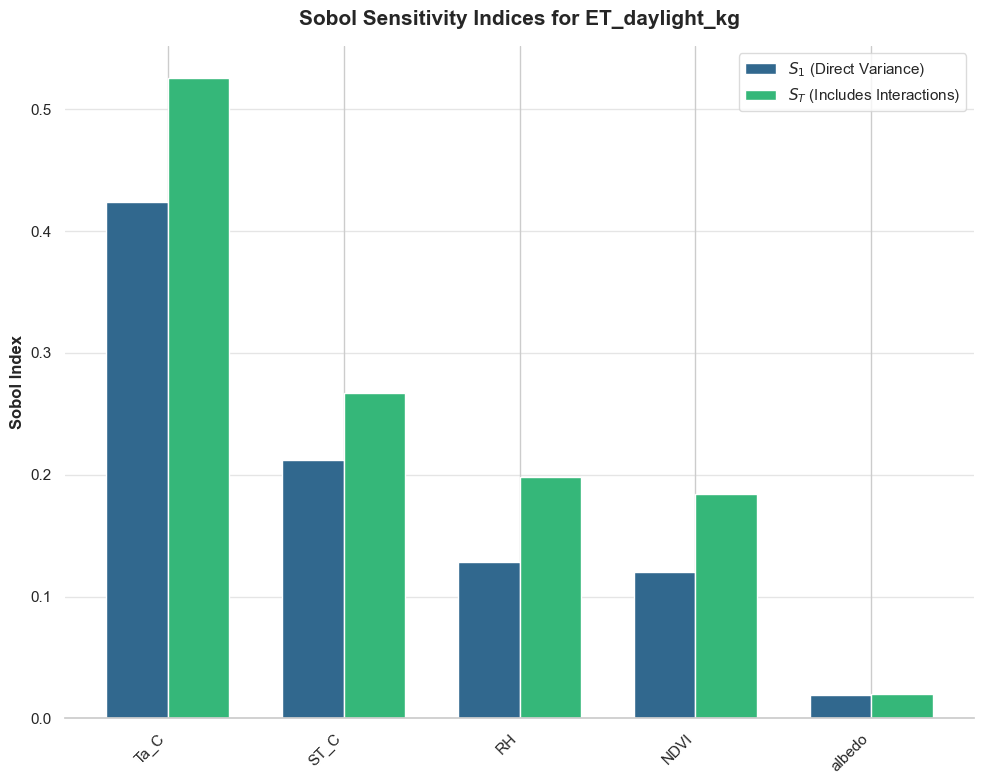

In [51]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:47 INFO] starting JET table processing
[2026-08-27 10:37:47 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:47 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:47 INFO] started extracting time from JET input table
[2026-08-27 10:37:47 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:47 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:47 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:47 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:37:47 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:37:47 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:37:47 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:37:47 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.021 nan: 0.

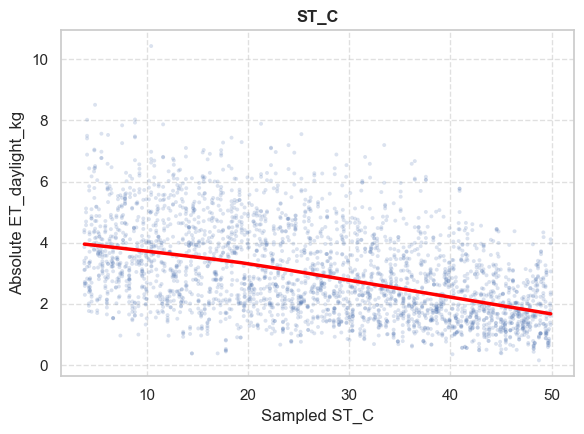

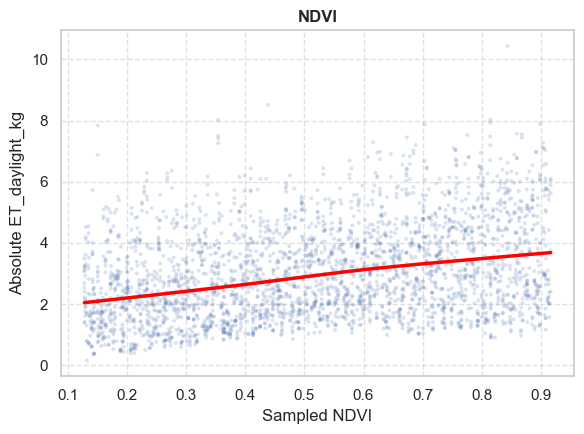

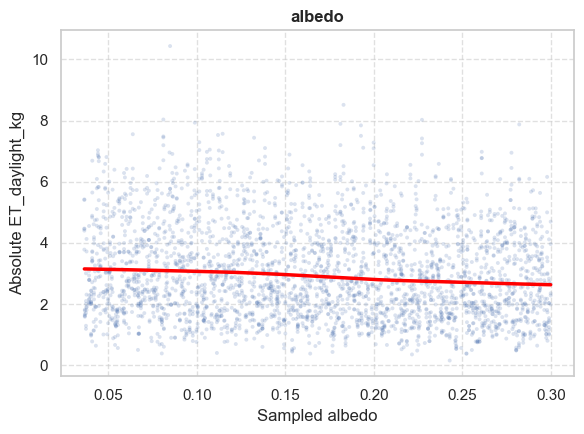

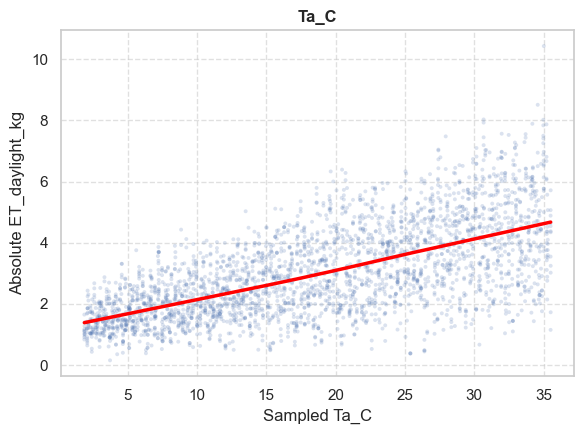

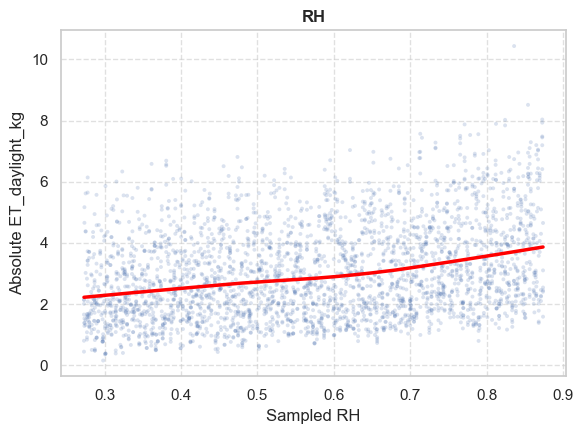

In [52]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_scatter_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples (console output hidden)...
[2026-08-27 10:37:49 INFO] starting JET table processing
[2026-08-27 10:37:49 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:49 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:37:49 INFO] started extracting time from JET input table
[2026-08-27 10:37:49 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:49 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:49 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:49 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:37:49 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:37:49 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:37:49 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:37:49 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.020 nan: 0.

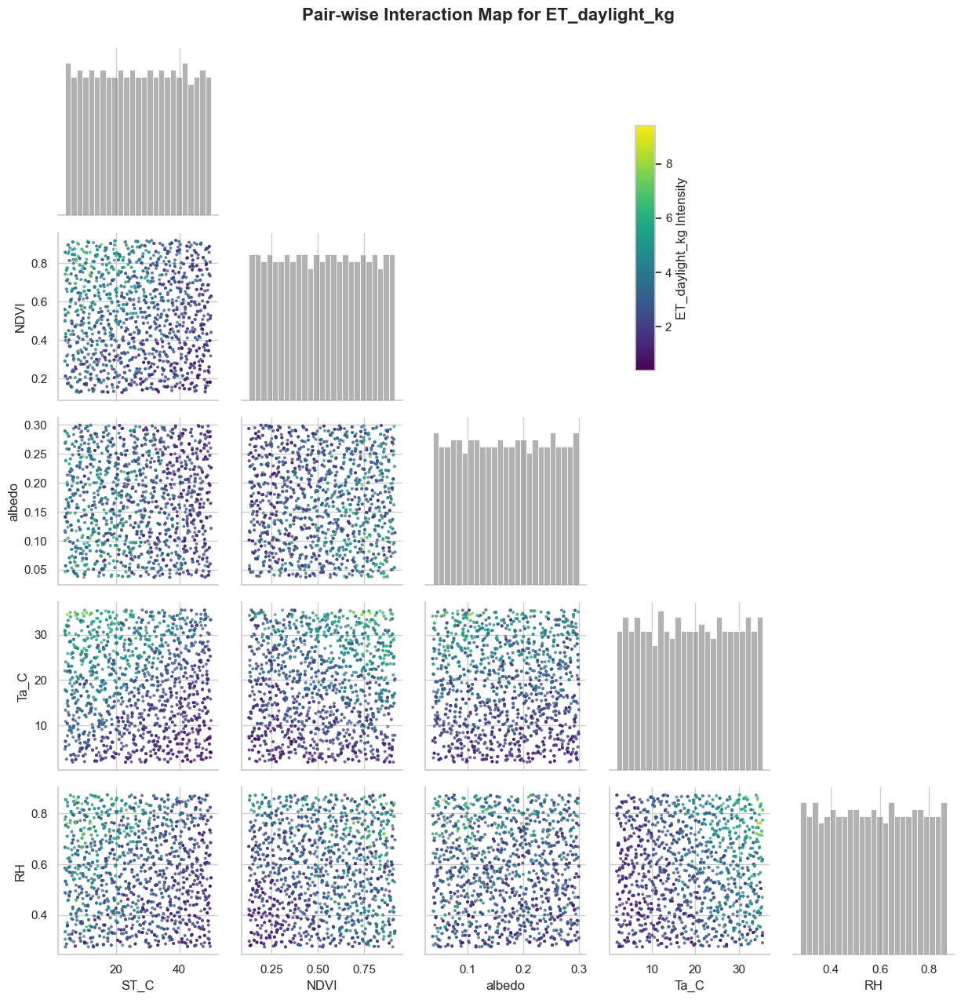

In [53]:
target_output = "ET_daylight_kg"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_pairwise_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:51 INFO] starting JET table processing
[2026-08-27 10:37:51 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:52 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:37:52 INFO] started extracting time from JET input table
[2026-08-27 10:37:52 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:52 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:52 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:52 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:37:52 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:37:52 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:37:52 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:37:52 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.020 nan: 0.00% (nan)
[2026-08-27 10

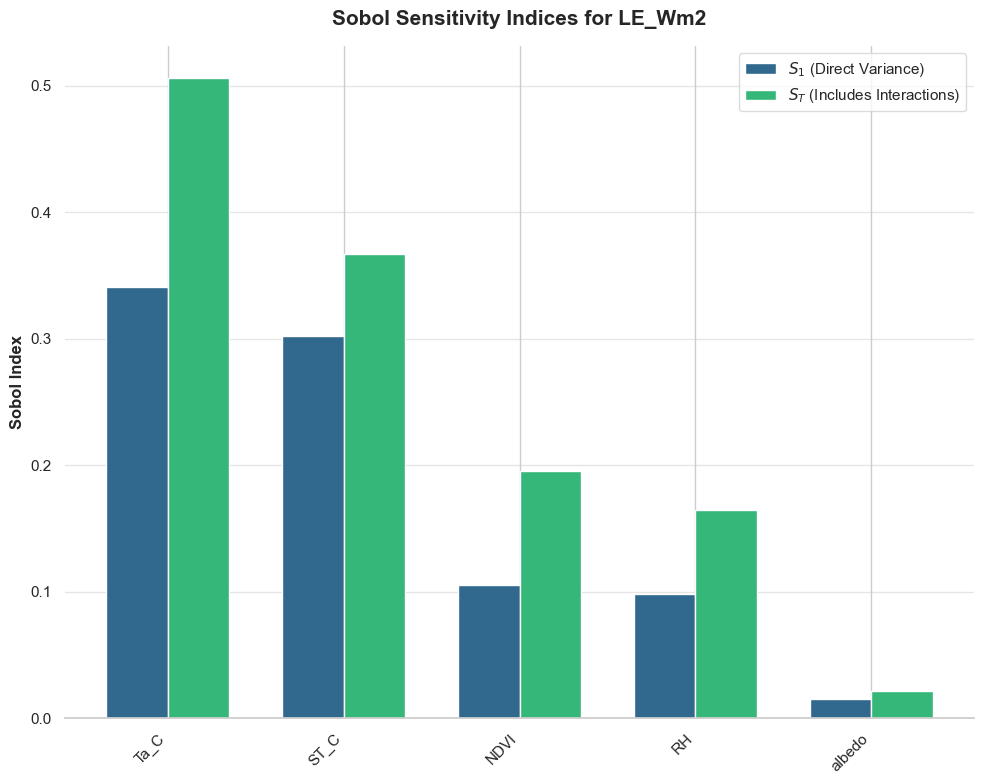

In [54]:
target_output = "LE_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:53 INFO] starting JET table processing
[2026-08-27 10:37:53 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:53 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:37:53 INFO] started extracting time from JET input table
[2026-08-27 10:37:53 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:53 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:53 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:53 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:37:53 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:37:53 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:37:53 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:37:53 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.021 nan: 0.00% (nan)
[2026-08-27 10

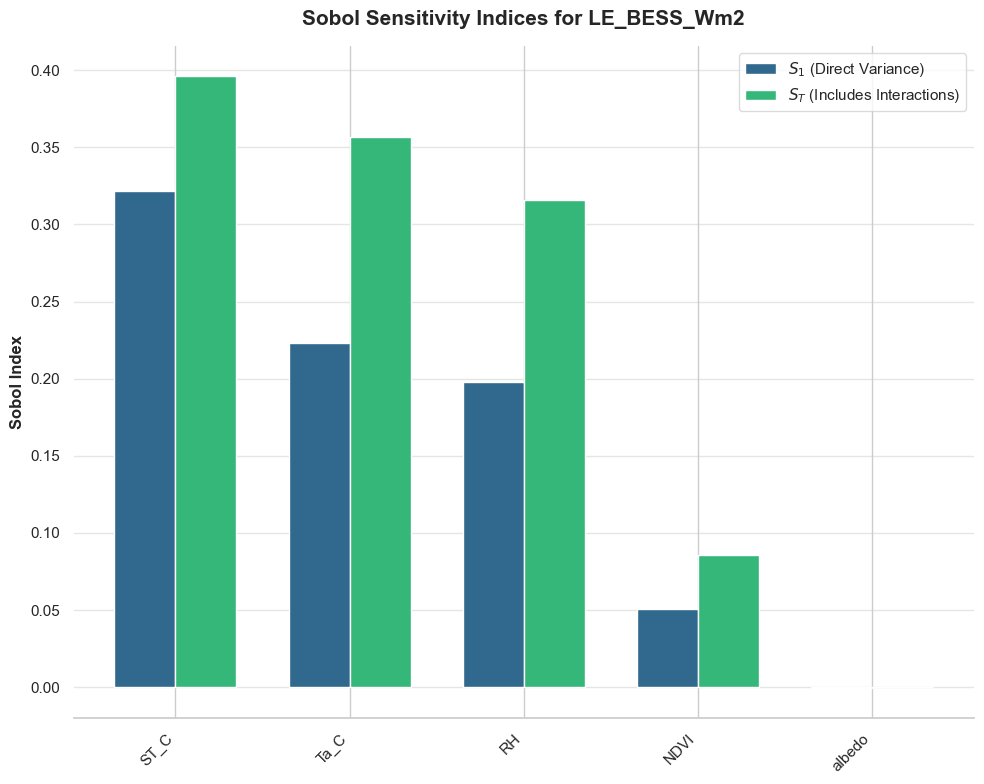

In [55]:
target_output = "LE_BESS_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:55 INFO] starting JET table processing
[2026-08-27 10:37:55 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:55 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:37:55 INFO] started extracting time from JET input table
[2026-08-27 10:37:55 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:55 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:55 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:55 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:37:55 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:37:55 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:37:55 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:37:55 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.019 nan: 0.00% (nan)
[2026-08-27 10

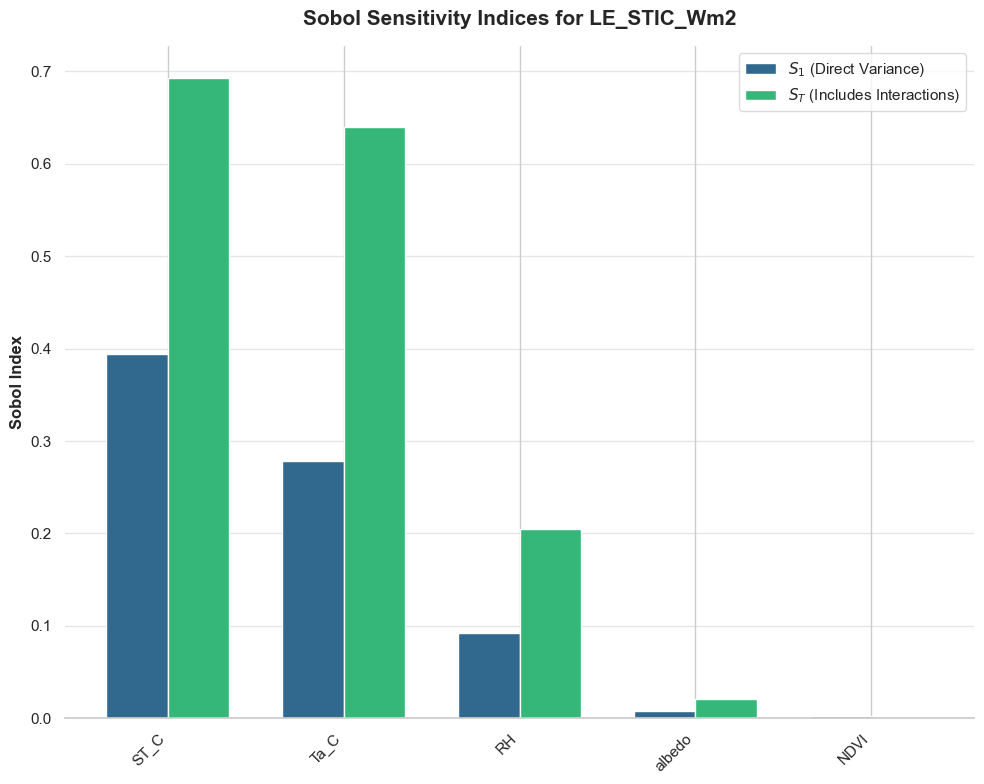

In [56]:
target_output = "LE_STIC_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:56 INFO] starting JET table processing
[2026-08-27 10:37:56 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:56 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:37:56 INFO] started extracting time from JET input table
[2026-08-27 10:37:56 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:56 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:57 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:57 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:37:57 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:37:57 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:37:57 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:37:57 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.020 nan: 0.00% (nan)
[2026-08-27 10

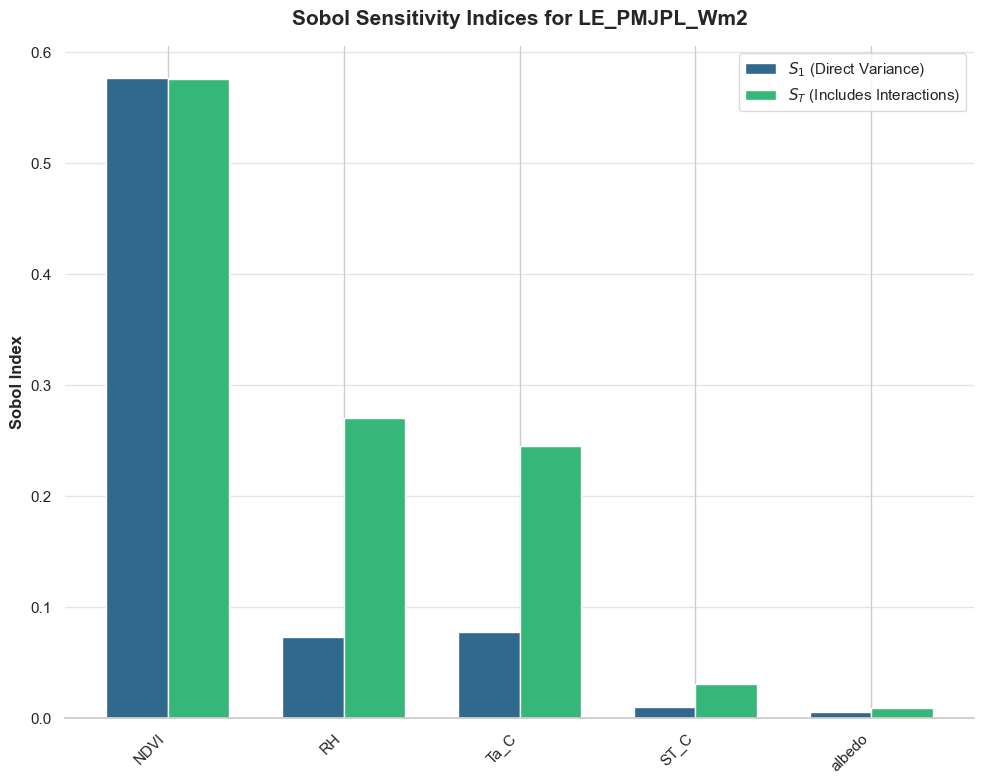

In [57]:
target_output = "LE_PMJPL_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:37:58 INFO] starting JET table processing
[2026-08-27 10:37:58 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:58 INFO] completed extracting geometry from JET input table (0.041 seconds)
[2026-08-27 10:37:58 INFO] started extracting time from JET input table
[2026-08-27 10:37:58 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:58 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:37:58 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:37:58 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:37:58 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:37:58 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:37:58 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:37:58 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.021 nan: 0.00% (nan)
[2026-08-27 10

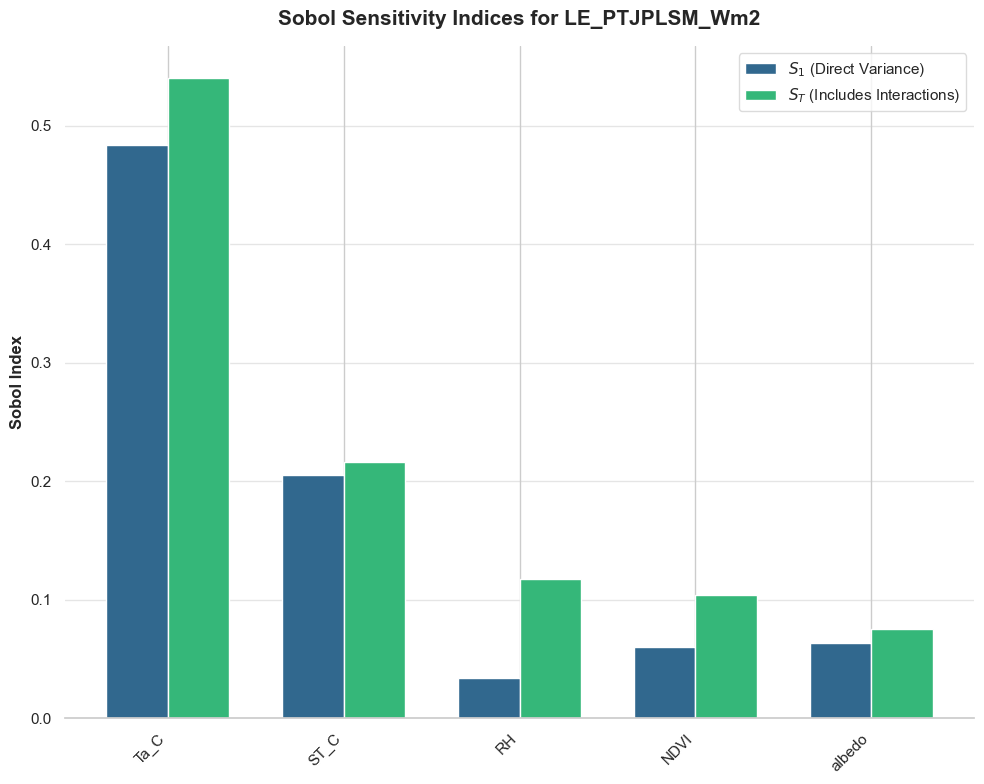

In [58]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256
)

Executing forward process for 2048 generated samples...
[2026-08-27 10:37:59 INFO] starting JET table processing
[2026-08-27 10:37:59 INFO] started extracting geometry from JET input table
[2026-08-27 10:37:59 INFO] completed extracting geometry from JET input table (0.017 seconds)
[2026-08-27 10:37:59 INFO] started extracting time from JET input table
[2026-08-27 10:37:59 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:37:59 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:38:00 INFO] completed processing FLiES-ANN in 0.17 seconds
[2026-08-27 10:38:00 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:38:00 INFO] * 0.05686349399279585: 2048
[2026-08-27 10:38:00 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:38:00 INFO] * 0.14780189943535538: 2048
[2026-08-27 10:38:00 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.020 nan: 0.00% (nan)
[2026-08-27 10

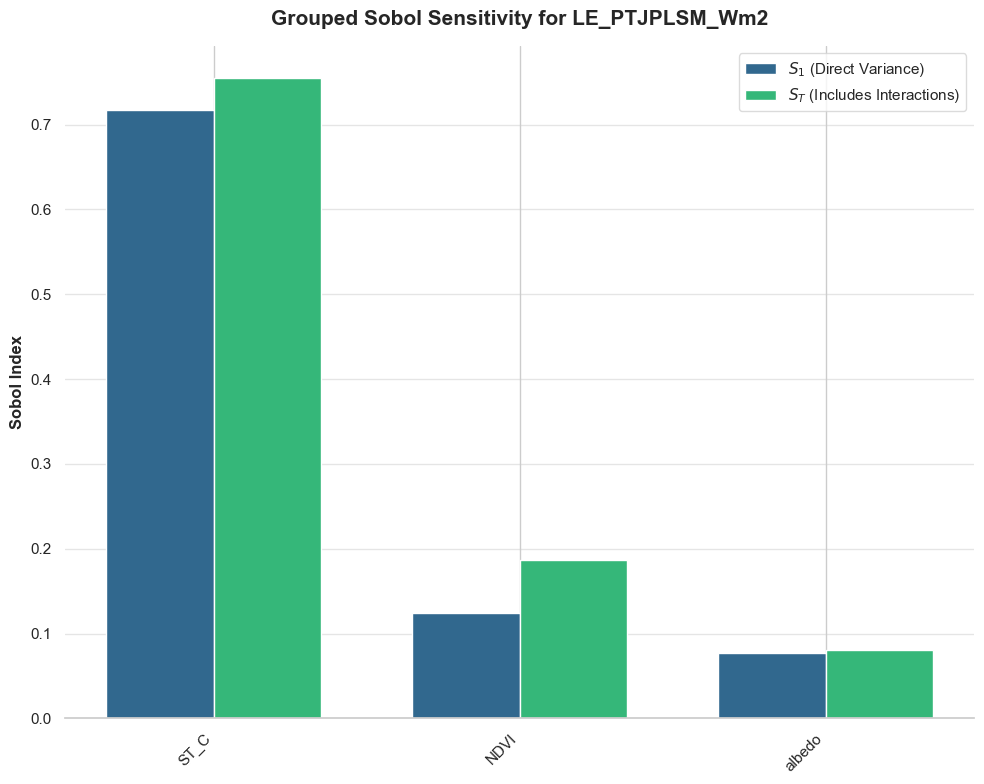

In [59]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

groups = [
    "Thermal", "Infrared", "Optical", "Thermal", "Infrared"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
    groups=groups
)

Executing forward process for 1536 generated samples...
[2026-08-27 10:38:01 INFO] starting JET table processing
[2026-08-27 10:38:01 INFO] started extracting geometry from JET input table
[2026-08-27 10:38:01 INFO] completed extracting geometry from JET input table (0.013 seconds)
[2026-08-27 10:38:01 INFO] started extracting time from JET input table
[2026-08-27 10:38:01 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:38:01 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:38:01 INFO] completed processing FLiES-ANN in 0.15 seconds
[2026-08-27 10:38:01 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:38:01 INFO] * 0.05686349399279585: 1536
[2026-08-27 10:38:01 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:38:01 INFO] * 0.14780189943535538: 1536
[2026-08-27 10:38:01 INFO] variable PAR_direct_Wm2 (float32) with [297.7827] unique values
[2026-08-27 10:38:01 INFO] * 29

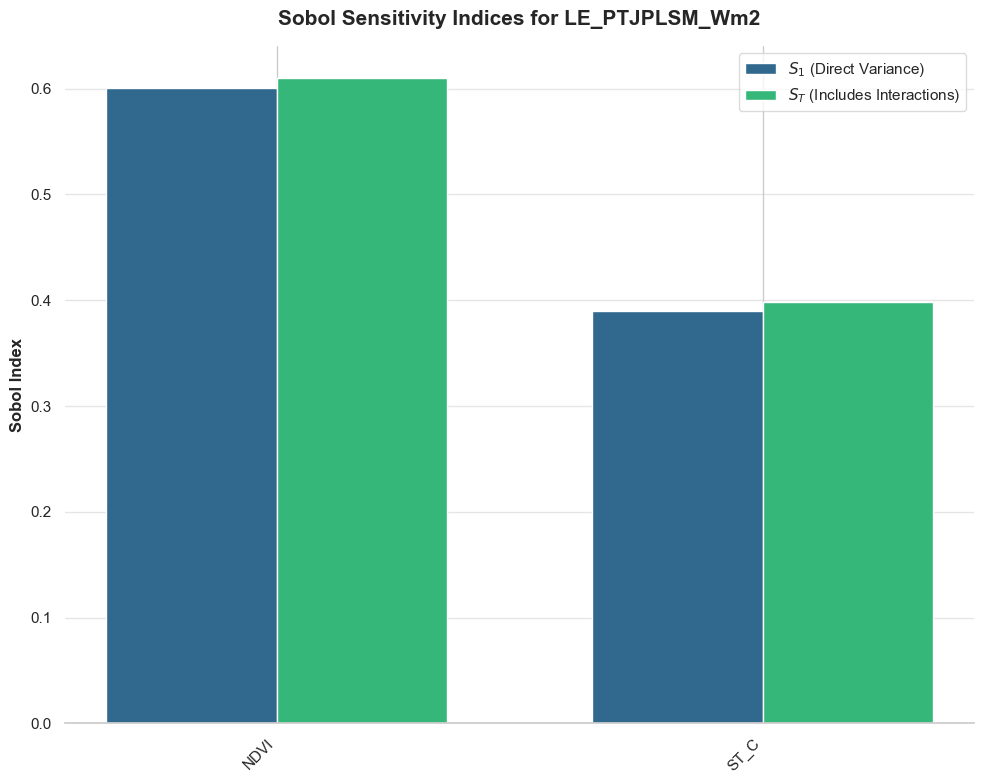

In [60]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

In [61]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

def analyze_input_collinearity(
    input_df, 
    input_variables, 
    theme_name="whitegrid", 
    cmap_name="coolwarm"
):
    """
    Analyzes and visualizes the collinearity of input variables using a 
    Pearson correlation heatmap and calculates Variance Inflation Factors (VIF).
    
    Returns:
    - corr_matrix: DataFrame containing the Pearson correlation coefficients.
    - vif_data: DataFrame containing the computed VIF for each variable.
    """
    
    # 1. Clean the input table
    df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    X = df_clean[input_variables]
    
    # 2. Compute Pearson Correlation Matrix
    corr_matrix = X.corr()
    
    # 3. Compute Variance Inflation Factor (VIF)
    # Add a constant (intercept) to baseline the VIF calculation properly
    X_vif = X.copy()
    X_vif['intercept'] = 1 
    
    vif_data = pd.DataFrame()
    vif_data["Variable"] = input_variables
    vif_data["VIF"] = [
        variance_inflation_factor(X_vif.values, i) 
        for i in range(len(input_variables))
    ]
    
    # 4. Visualization Setup
    sns.set_theme(style=theme_name)
    fig = plt.figure(figsize=(14, 6))
    
    # --- Subplot 1: Correlation Heatmap ---
    ax1 = fig.add_subplot(1, 2, 1)
    
    # Create a mask to hide the upper triangle for a cleaner look
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    sns.heatmap(
        corr_matrix, 
        mask=mask, 
        cmap=cmap_name, 
        vmax=1.0, 
        vmin=-1.0, 
        center=0, 
        annot=True, 
        fmt=".2f", 
        square=True, 
        linewidths=.5, 
        cbar_kws={"shrink": .8},
        ax=ax1
    )
    ax1.set_title("Pearson Correlation Matrix", weight='bold', fontsize=14, pad=15)
    
    # --- Subplot 2: VIF Bar Chart ---
    ax2 = fig.add_subplot(1, 2, 2)
    
    # Extract a color from the colormap for the bars
    bar_color = sns.color_palette(cmap_name)[-1] 
    
    sns.barplot(
        data=vif_data, 
        x="VIF", 
        y="Variable", 
        color=bar_color, 
        ax=ax2,
        edgecolor="white"
    )
    
    # Add a vertical threshold line at VIF = 5 (standard threshold for high collinearity)
    ax2.axvline(x=5, color='red', linestyle='--', linewidth=1.5, label='High Collinearity Threshold (VIF=5)')
    
    ax2.set_title("Variance Inflation Factor (VIF)", weight='bold', fontsize=14, pad=15)
    ax2.set_xlabel("VIF Score", weight='bold')
    ax2.set_ylabel("")
    ax2.legend(frameon=True, facecolor='white', edgecolor='lightgray')
    
    sns.despine(left=True, ax=ax2)
    ax2.grid(axis='x', linestyle='-', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    return corr_matrix, vif_data

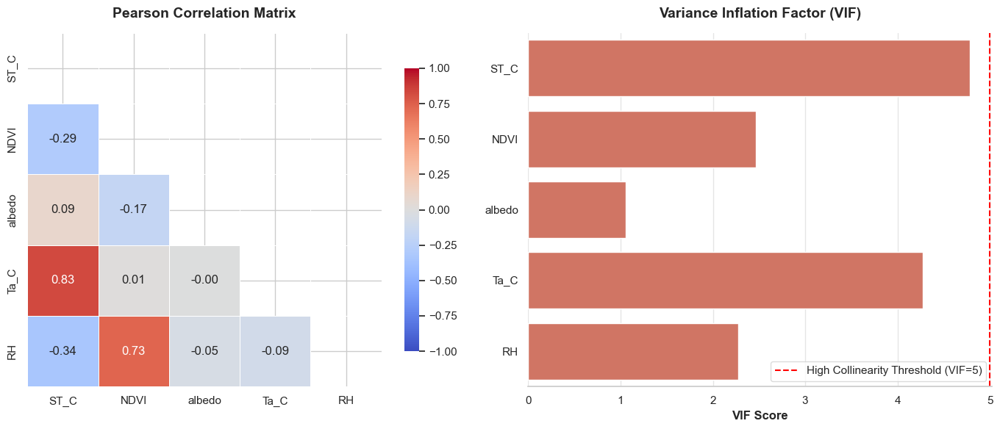

In [62]:
input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

collinearity_results = analyze_input_collinearity(
    input_df=input_df, 
    input_variables=input_variables
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:38:02 INFO] starting JET table processing
[2026-08-27 10:38:02 INFO] started extracting geometry from JET input table
[2026-08-27 10:38:02 INFO] completed extracting geometry from JET input table (0.026 seconds)
[2026-08-27 10:38:02 INFO] started extracting time from JET input table
[2026-08-27 10:38:02 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:38:02 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:38:02 INFO] completed processing FLiES-ANN in 0.21 seconds
[2026-08-27 10:38:02 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:38:02 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:38:02 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:38:02 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:38:02 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.021 nan: 0.00% (nan)
[2026-08-27 10

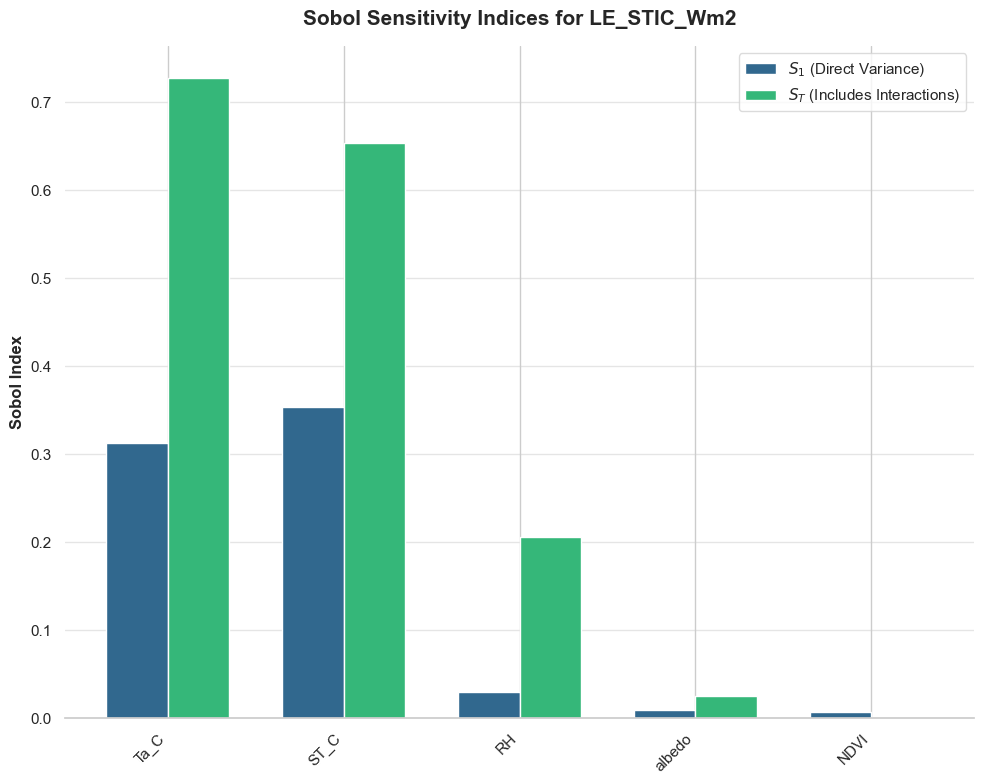

In [63]:
target_output = "LE_STIC_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:38:04 INFO] starting JET table processing
[2026-08-27 10:38:04 INFO] started extracting geometry from JET input table
[2026-08-27 10:38:04 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:38:04 INFO] started extracting time from JET input table
[2026-08-27 10:38:04 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:38:04 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:38:04 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:38:04 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:38:04 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:38:04 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:38:04 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:38:04 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.021 nan: 0.00% (nan)
[2026-08-27 10

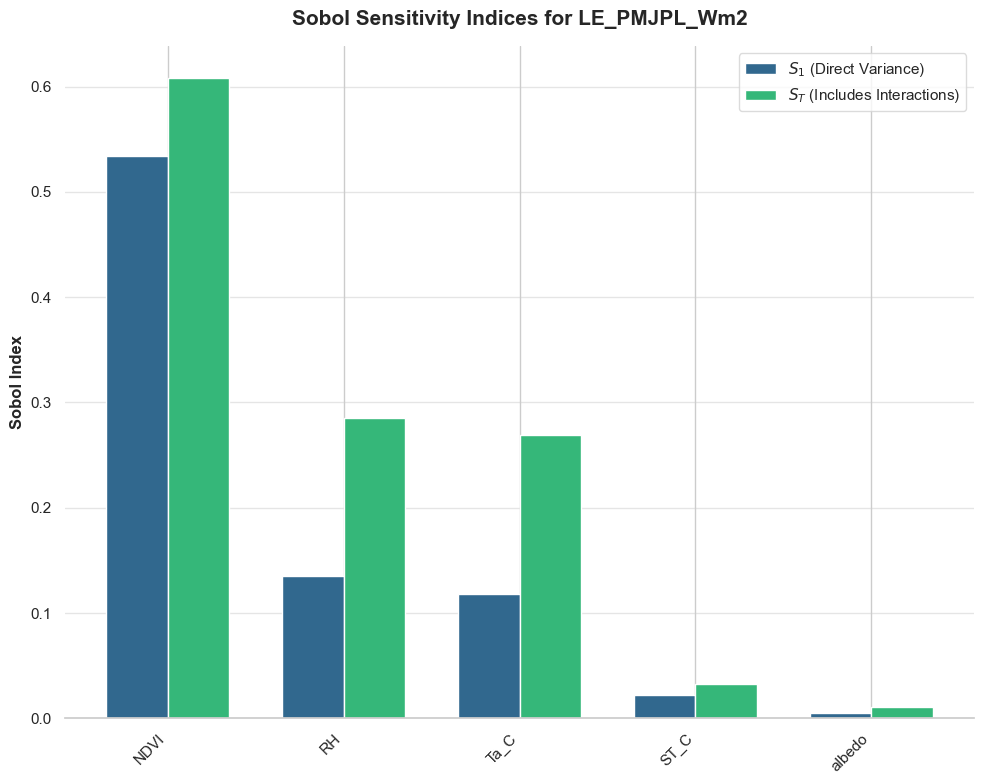

In [64]:
target_output = "LE_PMJPL_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

Executing forward process for 3072 generated samples...
[2026-08-27 10:38:05 INFO] starting JET table processing
[2026-08-27 10:38:05 INFO] started extracting geometry from JET input table
[2026-08-27 10:38:05 INFO] completed extracting geometry from JET input table (0.025 seconds)
[2026-08-27 10:38:05 INFO] started extracting time from JET input table
[2026-08-27 10:38:05 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:38:05 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:38:06 INFO] completed processing FLiES-ANN in 0.22 seconds
[2026-08-27 10:38:06 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:38:06 INFO] * 0.05686349399279585: 3072
[2026-08-27 10:38:06 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:38:06 INFO] * 0.14780189943535538: 3072
[2026-08-27 10:38:06 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.021 nan: 0.00% (nan)
[2026-08-27 10

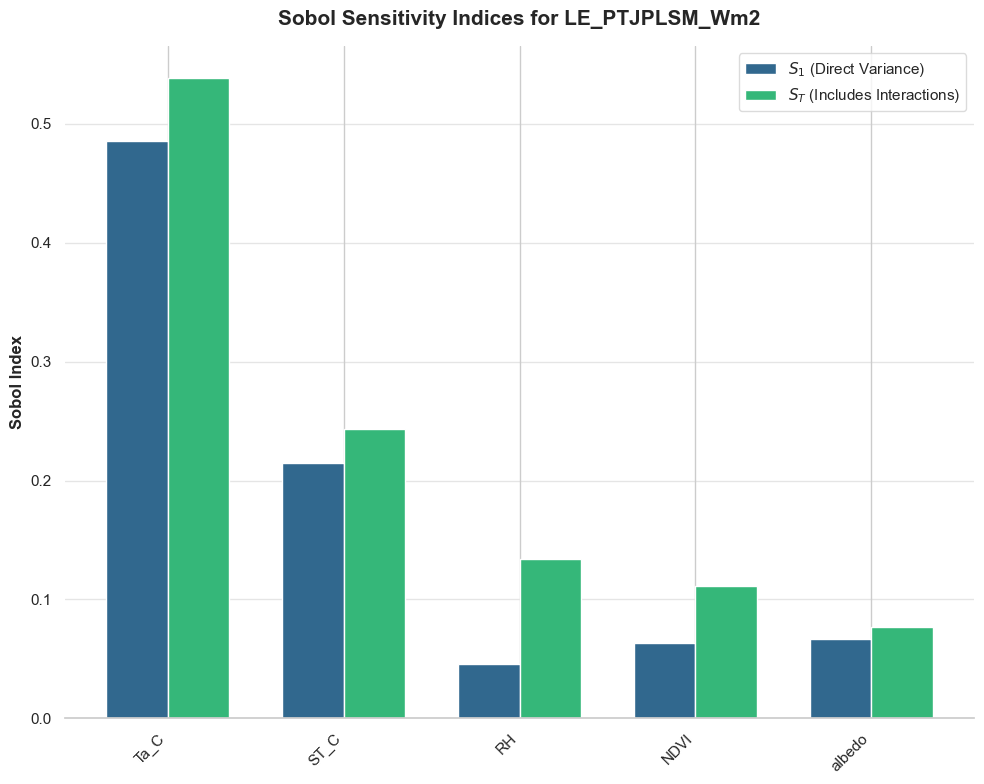

In [65]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256
)

Executing forward process for 2048 generated samples...
[2026-08-27 10:38:07 INFO] starting JET table processing
[2026-08-27 10:38:07 INFO] started extracting geometry from JET input table
[2026-08-27 10:38:07 INFO] completed extracting geometry from JET input table (0.017 seconds)
[2026-08-27 10:38:07 INFO] started extracting time from JET input table
[2026-08-27 10:38:07 INFO] completed extracting time from JET input table (0.002 seconds)
[2026-08-27 10:38:07 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:38:07 INFO] completed processing FLiES-ANN in 0.29 seconds
[2026-08-27 10:38:07 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:38:07 INFO] * 0.05686349399279585: 2048
[2026-08-27 10:38:07 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:38:07 INFO] * 0.14780189943535538: 2048
[2026-08-27 10:38:07 INFO] variable PAR_direct_Wm2 min: 297.768 mean: 297.839 max: 298.021 nan: 0.00% (nan)
[2026-08-27 10

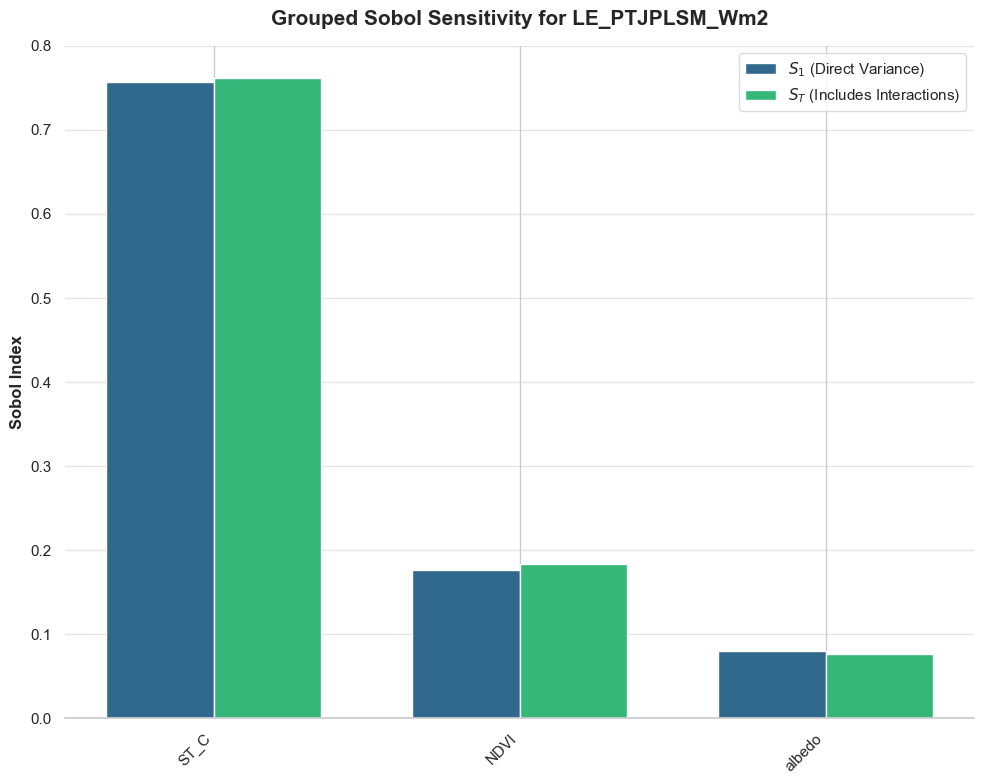

In [66]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

groups = [
    "Thermal", "Infrared", "Optical", "Thermal", "Infrared"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
    groups=groups
)

Executing forward process for 1536 generated samples...
[2026-08-27 10:38:08 INFO] starting JET table processing
[2026-08-27 10:38:08 INFO] started extracting geometry from JET input table
[2026-08-27 10:38:08 INFO] completed extracting geometry from JET input table (0.013 seconds)
[2026-08-27 10:38:08 INFO] started extracting time from JET input table
[2026-08-27 10:38:08 INFO] completed extracting time from JET input table (0.001 seconds)
[2026-08-27 10:38:08 INFO] running Forest Light Environmental Simulator
[2026-08-27 10:38:08 INFO] completed processing FLiES-ANN in 0.15 seconds
[2026-08-27 10:38:08 INFO] variable PAR_albedo (float64) with [0.05686349] unique values
[2026-08-27 10:38:08 INFO] * 0.05686349399279585: 1536
[2026-08-27 10:38:08 INFO] variable NIR_albedo (float64) with [0.1478019] unique values
[2026-08-27 10:38:08 INFO] * 0.14780189943535538: 1536
[2026-08-27 10:38:08 INFO] variable PAR_direct_Wm2 (float32) with [297.7827] unique values
[2026-08-27 10:38:08 INFO] * 29

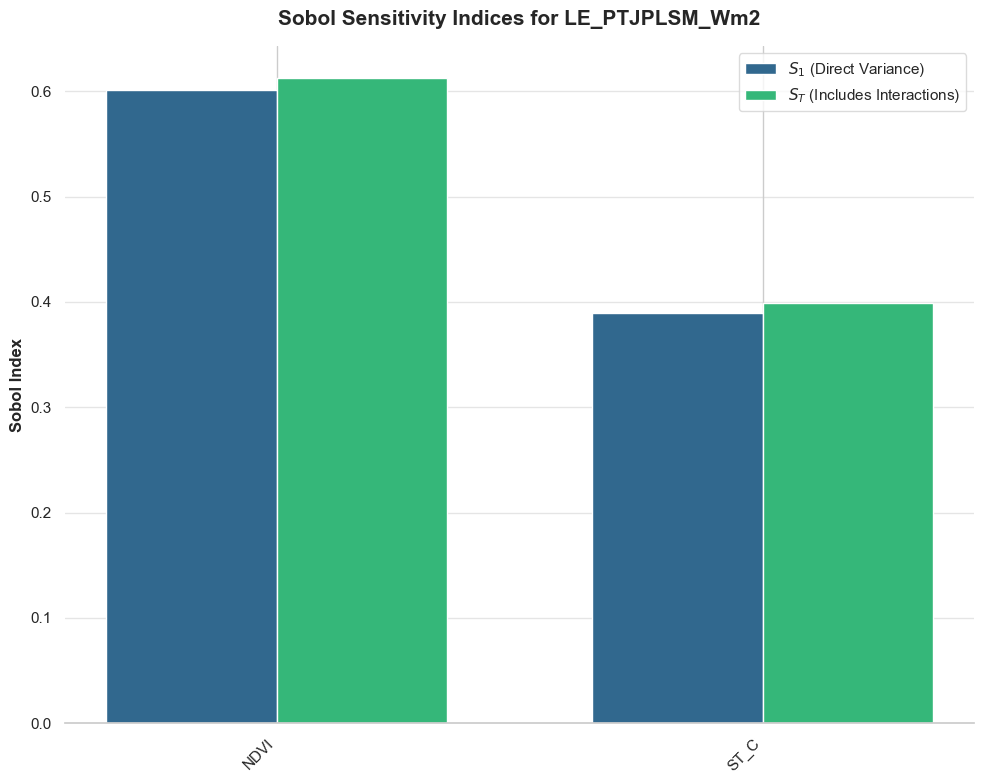

In [67]:
target_output = "LE_PTJPLSM_Wm2"

input_variables = [
    "ST_C", "NDVI"
]

Si_results = SOBOL_sensitivity_analysis(
    input_df=input_df, 
    input_variables=input_variables, 
    target_output=target_output,
    forward_process=process_JET_table,
    N=256,
)

In [68]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

def analyze_input_collinearity(
    input_df, 
    input_variables, 
    theme_name="whitegrid", 
    cmap_name="coolwarm"
):
    """
    Analyzes and visualizes the collinearity of input variables using a 
    Pearson correlation heatmap and calculates Variance Inflation Factors (VIF).
    
    Returns:
    - corr_matrix: DataFrame containing the Pearson correlation coefficients.
    - vif_data: DataFrame containing the computed VIF for each variable.
    """
    
    # 1. Clean the input table
    df_clean = input_df.dropna(subset=[var for var in input_variables if var in input_df.columns]).copy()
    X = df_clean[input_variables]
    
    # 2. Compute Pearson Correlation Matrix
    corr_matrix = X.corr()
    
    # 3. Compute Variance Inflation Factor (VIF)
    # Add a constant (intercept) to baseline the VIF calculation properly
    X_vif = X.copy()
    X_vif['intercept'] = 1 
    
    vif_data = pd.DataFrame()
    vif_data["Variable"] = input_variables
    vif_data["VIF"] = [
        variance_inflation_factor(X_vif.values, i) 
        for i in range(len(input_variables))
    ]
    
    # 4. Visualization Setup
    sns.set_theme(style=theme_name)
    fig = plt.figure(figsize=(14, 6))
    
    # --- Subplot 1: Correlation Heatmap ---
    ax1 = fig.add_subplot(1, 2, 1)
    
    # Create a mask to hide the upper triangle for a cleaner look
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    sns.heatmap(
        corr_matrix, 
        mask=mask, 
        cmap=cmap_name, 
        vmax=1.0, 
        vmin=-1.0, 
        center=0, 
        annot=True, 
        fmt=".2f", 
        square=True, 
        linewidths=.5, 
        cbar_kws={"shrink": .8},
        ax=ax1
    )
    ax1.set_title("Pearson Correlation Matrix", weight='bold', fontsize=14, pad=15)
    
    # --- Subplot 2: VIF Bar Chart ---
    ax2 = fig.add_subplot(1, 2, 2)
    
    # Extract a color from the colormap for the bars
    bar_color = sns.color_palette(cmap_name)[-1] 
    
    sns.barplot(
        data=vif_data, 
        x="VIF", 
        y="Variable", 
        color=bar_color, 
        ax=ax2,
        edgecolor="white"
    )
    
    # Add a vertical threshold line at VIF = 5 (standard threshold for high collinearity)
    ax2.axvline(x=5, color='red', linestyle='--', linewidth=1.5, label='High Collinearity Threshold (VIF=5)')
    
    ax2.set_title("Variance Inflation Factor (VIF)", weight='bold', fontsize=14, pad=15)
    ax2.set_xlabel("VIF Score", weight='bold')
    ax2.set_ylabel("")
    ax2.legend(frameon=True, facecolor='white', edgecolor='lightgray')
    
    sns.despine(left=True, ax=ax2)
    ax2.grid(axis='x', linestyle='-', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    return corr_matrix, vif_data

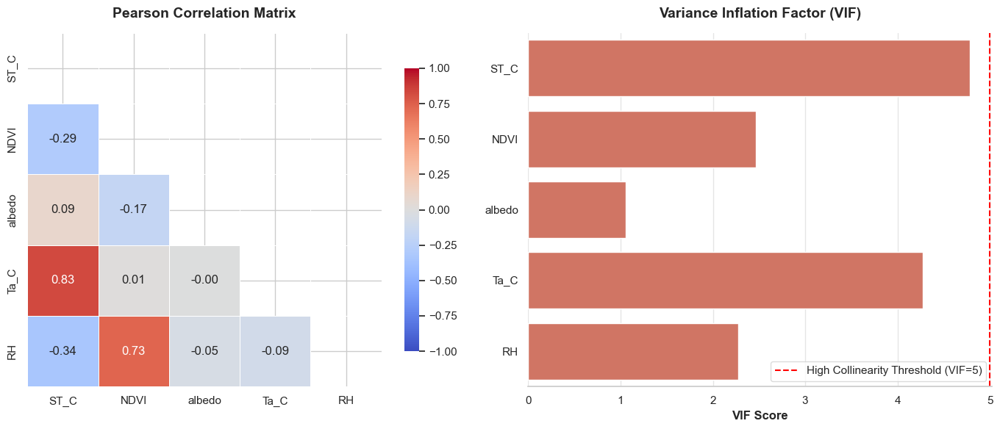

In [69]:
input_variables = [
    "ST_C", "NDVI", "albedo", "Ta_C", "RH"
]

collinearity_results = analyze_input_collinearity(
    input_df=input_df, 
    input_variables=input_variables
)

In [78]:
[column for column in processed.columns if "insitu" in column]

['insitu_LE_Wm2',
 'insitu_H_Wm2',
 'insitu_Rn_Wm2',
 'insitu_G_Wm2',
 'insitu_SWin_Wm2',
 'insitu_Ta_C',
 'insitu_RH',
 'insitu_Rn_daylight_Wm2',
 'insitu_LE_daylight_Wm2',
 'insitu_ET_daylight_kg']

In [79]:
processed["ET_error"] = processed["ET_daylight_kg"] - processed["insitu_ET_daylight_kg"]

In [81]:
processed["LE_error"] = processed["LE_Wm2"] - processed["insitu_LE_Wm2"]

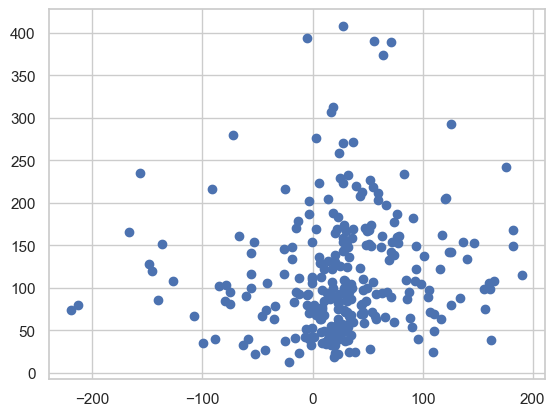

In [82]:
plt.scatter(processed.LE_error, processed.ETinstUncertainty)

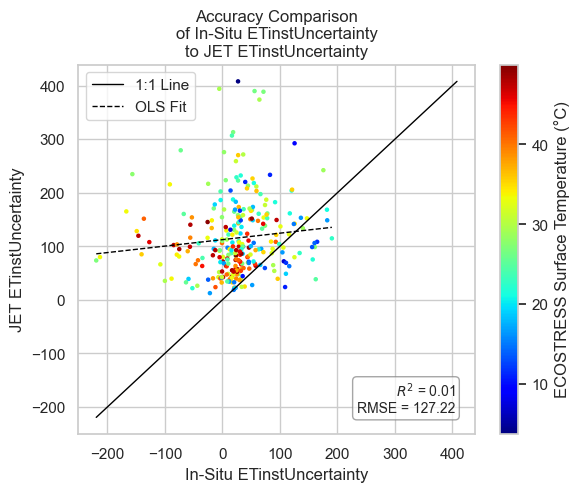

In [83]:
generate_accuracy_plot(
    df=processed,
    x_variable="LE_error",
    y_variable="ETinstUncertainty",
    output_variable="ETinstUncertainty",
    model_name=model_name,
    color_col='ST_C',
    cbar_label="ECOSTRESS Surface Temperature (°C)",
    save_plots=SAVE_PLOTS
)

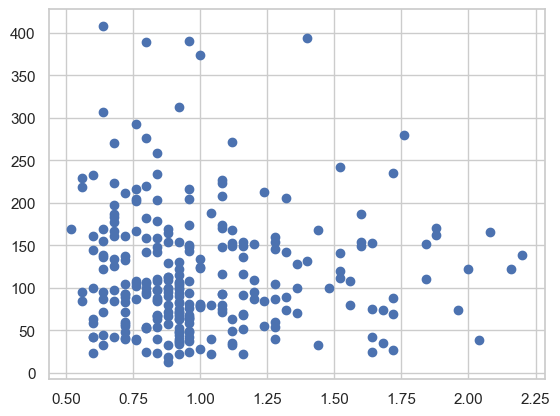

In [73]:
plt.scatter(input_df.LST_err, input_df.ETinstUncertainty)

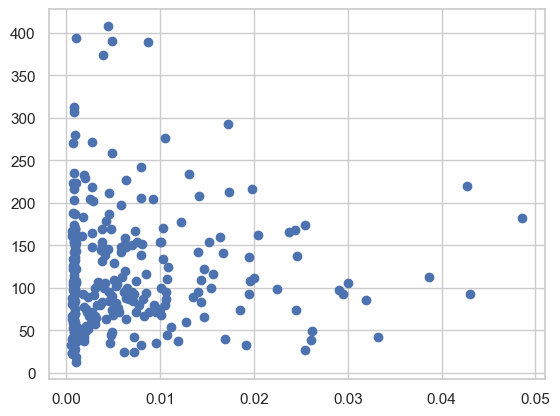

In [74]:
plt.scatter(input_df["NDVI-UQ"], input_df.ETinstUncertainty)

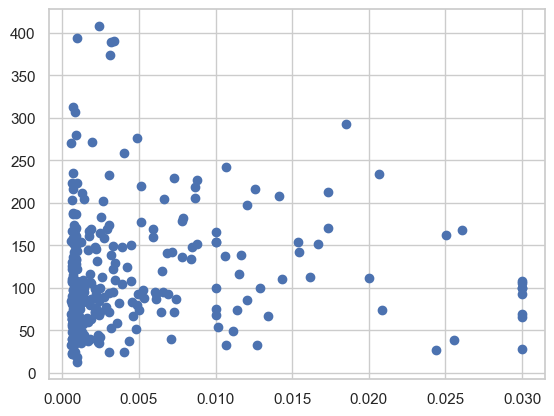

In [75]:
plt.scatter(input_df["albedo-UQ"], input_df.ETinstUncertainty)